# Поиск временных признаков для рекомендательной модели

Один и тот же счетчик можно посчитать за день, неделю или месяц. Например, число
реакций на исполнителя за последние три дня говорит о недавнем интересе, а за
полгода — о более устойчивом предпочтении. Обычно такие окна выбирает человек.
Здесь проверяем, можно ли передать этот выбор автоматическому поиску и получить
результат не хуже разумно настроенного ручного baseline.

Сначала разберем данные и построим LightGBM с ручными признаками. Затем зададим
правила генерации кандидатов: по кому группировать события, что считать и за какой
период. Система рассчитает эти варианты и сравнит наборы на будущей по времени
validation. Модель во всех основных сравнениях остается бустингом: так проще понять,
что изменилось именно из-за признаков.

Используем два источника. В KION предсказываем, достигла ли доля просмотра 50%,
среди уже наблюдаемых пар пользователь–фильм. В Yambda предсказываем like или dislike
среди явных реакций. Эти данные позволяют проверить исторические признаки, но
не дают оценить выдачу рекомендаций по всему каталогу. Ограничения разберем ниже.

Вся вычислительная часть находится в ячейках этого файла. Папки `src` и `scripts`
для его выполнения не нужны. На диск сохраняются исходные данные, рассчитанные
матрицы и результаты, чтобы повторный запуск не начинал все сначала.

Перед запуском выберите один из режимов:

- `saved` — прочитать результаты уже выполненного полного исследования и построить графики;
- `smoke` — проверить весь код на первых 100 тысячах событий с коротким обучением;
- `full` — обучить модели на полном выбранном наборе, провести по 20 HPO trials
  для manual и auto и повторить основные модели с тремя seeds.

При наличии результатов по умолчанию включается `saved`, иначе — `smoke`.
Для запуска в отдельной папке нужны этот `.ipynb` и установленные библиотеки.
Недостающие данные скачиваются из официальных источников. Новые расчеты сохраняются
в собственный каталог; его имя задается через `RUN_NAME`.

В проекте уже прошел независимый аудит: после него исправлены выбор ручного baseline
и несколько ошибок воспроизводимости. Тот же test был виден до исправлений,
поэтому текущие цифры — повторная оценка на известном holdout. Выбор признаков и
параметров по-прежнему делается только на search validation; нового слепого
подтверждения эти результаты не заменяют. MovieLens сохранен как архивный запуск.

## 1. Библиотеки и окружение

Расчеты проверены на Python 3.13. Polars нужен для исторических агрегаций, LightGBM —
для обучения, Optuna — для подбора параметров. Остальные библиотеки используются
для метрик, SVD, тестов и графиков. Версии зафиксированы, чтобы изменение библиотеки
не стало незаметной причиной другого результата.

Если пакеты еще не установлены, раскомментируйте `%pip install` в следующей ячейке.
Лимит в четыре потока уменьшает конкуренцию за память на обычном ноутбуке.

In [1]:
from importlib import metadata

# %pip устанавливает пакеты в окружение текущего kernel.
REQUIRED_PACKAGES = ['numpy==2.3.2', 'polars==1.43.2', 'pandas==2.3.1', 'lightgbm==4.6.0', 'optuna==4.9.0', 'scikit-learn==1.7.2', 'scipy==1.16.3', 'matplotlib==3.10.9', 'psutil==7.0.0', 'PyYAML==6.0.2', 'pytest==9.0.2', 'nbformat==5.10.4', 'nbclient==0.10.2', 'ipykernel==6.30.0']
install = []
for requirement in REQUIRED_PACKAGES:
    package, version = requirement.split("==")
    try:
        actual = metadata.version(package)
    except metadata.PackageNotFoundError:
        actual = None
    if actual != version:
        install.append(requirement)
if install:
    get_ipython().run_line_magic("pip", "install --disable-pip-version-check " + " ".join(install))
assert all(metadata.version(r.split("==")[0]) == r.split("==")[1] for r in REQUIRED_PACKAGES)
print("Проверенные зависимости доступны")

Проверенные зависимости доступны


In [2]:
import os
import ast
import sys
import gc
import io
import json
import re
import hashlib
import inspect
import textwrap
import pickle
import threading
import time
import urllib.request
import zipfile
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass
from datetime import datetime, timedelta
from pathlib import Path
from time import perf_counter

os.environ.setdefault("POLARS_MAX_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/yandex-notebook-mpl")

import numpy as np
import polars as pl
import lightgbm as lgb
import optuna
import psutil
import pytest
from scipy.sparse import coo_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import log_loss, roc_auc_score
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

print("Python:", sys.version.split()[0])
print("Versions:", {m.__name__: m.__version__ for m in [np, pl, lgb, optuna]})

Python: 3.13.5
Versions: {'numpy': '2.3.2', 'polars': '1.43.2', 'lightgbm': '4.6.0', 'optuna': '4.9.0'}


## 2. Настройки запуска

Выберите `DATASET`: `kion` или `yambda`. Режим `MODE` определяет, будем ли мы читать
готовые результаты или заново обучать модели. Для отдельного эксперимента измените
`RUN_NAME`, чтобы его файлы было легко отличить от предыдущих.

`CONFIG` задает бюджет обучения, seeds и границы выборок. `AUTO_CONFIG` описывает
пространство признаков: возможные окна, размеры проверяемых наборов и порог KEEP/DROP.
Эти настройки задает исследователь. Автоматизация начинается внутри этого пространства,
а не с самостоятельного выбора target или смысла событий.

В `smoke` бюджет намеренно уменьшен. Его метрики нужны для проверки выполнения,
а не для выводов о качестве метода. Переменные `TEMPORAL_NOTEBOOK_*` позволяют
выбирать те же настройки при автоматическом запуске.

In [3]:
WORK_DIR = Path.cwd()
if WORK_DIR.name == "notebooks":
    WORK_DIR = WORK_DIR.parent
os.chdir(WORK_DIR)
DATASET = os.environ.get("TEMPORAL_NOTEBOOK_DATASET", "kion")  # kion | yambda | movielens
assert DATASET in {"kion", "yambda", "movielens"}
REFERENCE_ROOT = WORK_DIR / "artifacts" / DATASET
MODE = os.environ.get("TEMPORAL_NOTEBOOK_MODE", "saved" if (REFERENCE_ROOT / "final_results.json").exists() else "smoke")
RUN_NAME = os.environ.get("TEMPORAL_NOTEBOOK_RUN", "notebook_" + MODE)
assert MODE in {"saved", "smoke", "full"}
OUTPUT_ROOT = REFERENCE_ROOT if MODE == "saved" else WORK_DIR / "artifacts" / (DATASET + "_" + RUN_NAME)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RAW_DIR = WORK_DIR / "data" / "raw"
CUSTOM_DATA_PATH = None  # Путь к своей таблице с user_id, item_id, timestamp и бинарным label.
POSITIVE_LABEL = None   # Для многоклассовой таблицы: какое значение считать положительным исходом.

CONFIG = {'seed': 42,
 'threads': 4,
 'split_fractions': [0.7, 0.775, 0.85],
 'hyperparameter_trials': 20,
 'max_tuning_train_rows': 300000,
 'max_estimators': 600,
 'early_stopping_rounds': 40,
 'objective': 'logloss',
 'bootstrap_repeats': 300,
 'seeds': [42, 2024, 7]}
AUTO_CONFIG = {'windows': [1, 3, 7, 14, 21, 30, 60, 90, 180, None],
 'max_features': 700,
 'near_constant_fraction': 0.9999,
 'max_missing_fraction': 0.999,
 'correlation_threshold': 0.9999,
 'selection_sizes': [32, 64, 96, 128],
 'agent_rounds': 2,
 'agent_proposals_per_round': 8,
 'keep_min_logloss_gain': 0.0001}
if MODE == "smoke":
    CONFIG.update(hyperparameter_trials=2, max_estimators=80, early_stopping_rounds=10,
                  seeds=[42], bootstrap_repeats=20)
    AUTO_CONFIG.update(windows=[1, 7, 30, None], selection_sizes=[16, 32], agent_rounds=1)
if DATASET != "movielens":
    CONFIG.update(dataset_name=DATASET, run_representations=True)
    AUTO_CONFIG["max_features"] = 900
print("Mode:", MODE, "| Output:", OUTPUT_ROOT)
print("HPO trials per model:", CONFIG["hyperparameter_trials"], "| Seeds:", CONFIG["seeds"])

Mode: saved | Output: /private/tmp/fe-publication-20261025/artifacts/kion
HPO trials per model: 20 | Seeds: [42, 2024, 7]


## 3. Загрузка данных

Скачиваем конкретные версии KION и Yambda, а не содержимое меняющейся ссылки
«на сегодня». Для каждого файла сохраняем размер и SHA256. Это позволяет проверить,
что повторный запуск действительно использует те же данные.

Для Yambda берем likes/dislikes из части flat/50m и таблицы связей с исполнителями
и альбомами. Полный Yambda-5B и аудиоэмбеддинги для этого эксперимента не нужны.
Загрузчик умеет продолжить недокачанный файл и повторить запрос при обрыве сети.

In [4]:
KION_REVISION = "f69775be31fa5779907cf0a92ddedb70037fb5ae"


YAMBDA_REVISION = "dd6f3a19eef5866e346c3270e098baa641a44948"


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download_verified(url, path, expected_size=None, sha256=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    def valid():
        return (path.exists() and (expected_size is None or path.stat().st_size == expected_size)
                and (sha256 is None or file_sha256(path) == sha256))
    if valid():
        return path
    partial = path.with_suffix(path.suffix + ".part")
    for attempt in range(8):
        offset = partial.stat().st_size if partial.exists() else 0
        request = urllib.request.Request(url, headers={"Range": f"bytes={offset}-"} if offset else {})
        try:
            with urllib.request.urlopen(request, timeout=90) as response:
                resume = offset and response.status == 206
                if resume and not response.headers.get("Content-Range", "").startswith(f"bytes {offset}-"):
                    raise RuntimeError("Wrong resume byte range")
                with partial.open("ab" if resume else "wb") as out:
                    for chunk in iter(lambda: response.read(1024 * 256), b""):
                        out.write(chunk)
            if expected_size is not None and partial.stat().st_size != expected_size:
                raise OSError("Incomplete download")
            if sha256 and file_sha256(partial) != sha256:
                partial.unlink()
                raise OSError("SHA256 mismatch")
            partial.replace(path)
            print(f"Downloaded and verified {path.name}: {path.stat().st_size / 2**20:.1f} MiB", flush=True)
            return path
        except OSError as error:
            print(f"Retry {path.name} #{attempt + 1}: {error}", flush=True)
            time.sleep(min(attempt + 1, 5))
    raise RuntimeError(f"Cannot download {url}")


def fetch_sources(dataset, raw_dir="data/raw"):
    raw = Path(raw_dir) / dataset
    raw.mkdir(parents=True, exist_ok=True)
    manifest_path = raw / "source_manifest.json"
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
    elif dataset == "kion":
        with urllib.request.urlopen(f"https://api.github.com/repos/irsafilo/KION_DATASET/git/trees/{KION_REVISION}?recursive=1", timeout=60) as r:
            tree = json.load(r)["tree"]
        wanted = {"interactions.csv.zip", "data_original/users.csv", "data_original/items.csv"}
        manifest = {"dataset": "kion", "revision": KION_REVISION, "files": [
            {"name": Path(row["path"]).name, "size": row["size"],
             "url": f"https://raw.githubusercontent.com/irsafilo/KION_DATASET/{KION_REVISION}/{row['path']}"}
            for row in tree if row["path"] in wanted]}
    elif dataset == "yambda":
        revision = YAMBDA_REVISION
        with urllib.request.urlopen(f"https://huggingface.co/api/datasets/yandex/yambda/tree/{revision}?recursive=true&limit=1000", timeout=60) as r:
            tree = json.load(r)
        wanted = {"flat/50m/likes.parquet", "flat/50m/dislikes.parquet", "artist_item_mapping.parquet", "album_item_mapping.parquet"}
        manifest = {"dataset": "yambda", "revision": revision, "scale": "50m", "files": [
            {"name": Path(row["path"]).name, "size": row["size"], "sha256": row["lfs"]["oid"],
             "url": f"https://huggingface.co/datasets/yandex/yambda/resolve/{revision}/{row['path']}?download=true"}
            for row in tree if row["path"] in wanted]}
    else:
        raise ValueError("Supported sources: kion, yambda")
    expected_count = 3 if dataset == "kion" else 4
    if len(manifest["files"]) != expected_count:
        raise ValueError("Official source inventory differs from expected files")
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
    def fetch(entry):
        path = download_verified(entry["url"], raw / entry["name"], entry["size"], entry.get("sha256"))
        return {**entry, "sha256": file_sha256(path)}
    with ThreadPoolExecutor(max_workers=4) as pool:
        manifest["files"] = list(pool.map(fetch, manifest["files"]))
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
    return manifest

In [5]:
URL = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"


EXPECTED_MD5 = "c4d9eecfca2ab87c1945afe126590906"


def download():
    path = Path("data/raw/ml-1m.zip")
    path.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(20):
        if path.exists() and hashlib.md5(path.read_bytes()).hexdigest() == EXPECTED_MD5:
            print("MovieLens archive verified", flush=True)
            return
        offset = path.stat().st_size if path.exists() else 0
        headers = {"Range": f"bytes={offset}-"} if offset else {}
        try:
            request = urllib.request.Request(URL, headers=headers)
            with urllib.request.urlopen(request, timeout=60) as response:
                if offset and response.status != 206:
                    raise RuntimeError("Server did not honor resume range")
                if offset and not response.headers.get("Content-Range", "").startswith(f"bytes {offset}-"):
                    raise RuntimeError("Incorrect resume range")
                with path.open("ab" if offset else "wb") as out:
                    last_log = time.monotonic()
                    while True:
                        chunk = response.read(16384)
                        if not chunk:
                            break
                        out.write(chunk)
                        if time.monotonic() - last_log >= 30:
                            out.flush()
                            print(f"Downloaded {out.tell() / 2**20:.2f} MiB", flush=True)
                            last_log = time.monotonic()
            if hashlib.md5(path.read_bytes()).hexdigest() != EXPECTED_MD5:
                raise RuntimeError("Archive checksum mismatch")
        except (OSError, TimeoutError) as error:
            print(f"Download retry {attempt + 1}: {error}", flush=True)
            time.sleep(min(attempt + 1, 5))
            continue
    raise RuntimeError("Download failed after 20 resumptions")

## 4. Подготовка общей таблицы событий

Два источника устроены по-разному, поэтому приводим их к общей схеме:
`user_id`, `item_id`, `timestamp`, `event`, `label` и доступные metadata. `label`
нужен модели как ответ, `event` — движку для отбора прошлых действий нужного типа.
Они не подаются в модель как признаки текущей строки.

Каждое событие получает уникальный `row_id`. По нему потом возвращаем агрегаты
в исходный порядок и сверяем predictions с labels. Проверки пустых ID, времени
и повторных row_id нужны до обучения: хороший score не поможет заметить перепутанные
строки. Функции MovieLens здесь оставлены для чтения архивного эксперимента.

In [6]:
def _dat(path, columns):
    content = Path(path).read_bytes().decode("latin-1").replace("::", "\t")
    return pl.read_csv(io.StringIO(content), separator="\t", has_header=False,
                       new_columns=columns, infer_schema_length=10000)


def load_movielens(raw_dir="data/raw"):
    raw = Path(raw_dir)
    folder = raw / "ml-1m"
    if not folder.exists():
        if hashlib.md5((raw / "ml-1m.zip").read_bytes()).hexdigest() != "c4d9eecfca2ab87c1945afe126590906":
            raise ValueError("MovieLens archive is incomplete or checksum differs")
        with zipfile.ZipFile(raw / "ml-1m.zip") as archive:
            for name in ("ratings.dat", "movies.dat", "users.dat", "README"):
                member = f"ml-1m/{name}"
                if member in archive.namelist():
                    folder.mkdir(parents=True, exist_ok=True)
                    (folder / name).write_bytes(archive.read(member))
    ratings = _dat(folder / "ratings.dat", ["user_id", "item_id", "rating", "timestamp"])
    users = _dat(folder / "users.dat", ["user_id", "gender", "age", "occupation", "zip"])
    items = _dat(folder / "movies.dat", ["item_id", "title", "genres"])
    items = items.with_columns(
        pl.col("genres").str.split("|").list.first().alias("category_id"),
        pl.col("title").str.extract(r"\((\d{4})\)$", 1).cast(pl.Int32).alias("release_year"),
    ).drop("title")
    df = ratings.join(users, on="user_id", how="left", validate="m:1").join(
        items, on="item_id", how="left", validate="m:1"
    ).with_columns(
        (pl.col("rating") >= 4).cast(pl.Int8).alias("label"),
        pl.when(pl.col("rating") >= 4).then(pl.lit("positive")).otherwise(
            pl.lit("negative")).alias("event"),
        pl.from_epoch("timestamp", time_unit="s").alias("timestamp"),
    ).sort(["timestamp", "user_id", "item_id"]).with_row_index("row_id")
    validate_data(df)
    return df


def load_interactions(path, event_map=None, positive_label=None):
    path = Path(path)
    df = pl.read_parquet(path) if path.suffix == ".parquet" else pl.read_csv(path)
    if df.schema["timestamp"].is_numeric():
        df = df.with_columns(pl.from_epoch("timestamp", time_unit="s"))
    elif df.schema["timestamp"] == pl.String:
        df = df.with_columns(pl.col("timestamp").str.to_datetime())
    if "event" not in df.columns:
        if event_map:
            df = df.with_columns(pl.col("label").replace_strict(
                {int(k): v for k, v in event_map.items()}).alias("event"))
        else:
            df = df.with_columns(pl.col("label").cast(pl.String).alias("event"))
    if positive_label is not None:
        df = df.with_columns((pl.col("label") == positive_label).cast(pl.Int8).alias("label"))
    if set(df["label"].unique().to_list()) != {0, 1}:
        raise ValueError("Classifier requires both binary labels; specify positive_label explicitly")
    df = df.sort(["timestamp", "user_id", "item_id"]).with_row_index("row_id")
    validate_data(df)
    return df


def validate_data(df):
    required = {"user_id", "item_id", "timestamp", "label", "event", "row_id"}
    if not required <= set(df.columns):
        raise ValueError(f"Missing columns: {required - set(df.columns)}")
    if df.select(pl.any_horizontal(pl.col(c).is_null() for c in required).any()).item():
        raise ValueError("Required identifiers, times, events and targets cannot be null")
    if df["row_id"].n_unique() != df.height:
        raise ValueError("row_id must be unique")
    if not df["timestamp"].is_sorted():
        raise ValueError("Interactions must be sorted by timestamp")


def describe_data(df):
    return {
        "rows": df.height, "users": df["user_id"].n_unique(),
        "items": df["item_id"].n_unique(),
        "start": str(df["timestamp"].min()), "end": str(df["timestamp"].max()),
        "schema": {k: str(v) for k, v in df.schema.items()},
        "nulls": df.null_count().row(0, named=True),
        "label_distribution": df.group_by("label").len().sort("label").to_dicts(),
        "event_distribution": df.group_by("event").len().sort("event").to_dicts(),
        "duplicate_events": df.height - df.unique(
            ["user_id", "item_id", "timestamp", "label"]).height,
        "repeat_user_item_rows": df.height - df.unique(["user_id", "item_id"]).height,
        "distinct_timestamps": df["timestamp"].n_unique(),
        "same_timestamp_rows": df.height - df["timestamp"].n_unique(),
        "memory_mb": df.estimated_size("mb"),
    }


def dataset_fingerprint(df):
    return hashlib.sha256(df.hash_rows(seed=42).to_numpy().tobytes()).hexdigest()


def study_statistics(df, split):
    stats = describe_data(df)
    stats["splits"] = {}
    train = df.head(split.train_end)
    users, items = train["user_id"].unique().implode(), train["item_id"].unique().implode()
    for name, indices in [("train", split.train), ("validation_search", split.search),
                          ("validation_audit", split.audit), ("test", split.test)]:
        part = df[indices]
        stats["splits"][name] = {"rows": len(indices), "start": str(part["timestamp"].min()),
            "end": str(part["timestamp"].max()),
            "positive_rate": part["label"].mean() if name != "test" else None,
            "cold_users_fraction": 1-part["user_id"].is_in(users).mean(),
            "cold_items_fraction": 1-part["item_id"].is_in(items).mean()}
    return stats


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str) + "\n")

In [7]:
def positive_event(events):
    for event in ["positive", "like", "watch_high"]:
        if event in events:
            return event
    return sorted(events)[-1]


def finish_interactions(df):
    df = df.sort(["timestamp", "user_id", "item_id", "event"]).with_row_index("row_id")
    validate_data(df)
    if set(df["label"].unique().to_list()) != {0, 1}:
        raise ValueError("Both binary labels are required")
    return df


def kion_interactions(interactions, users, items, user_modulus=1):
    """Predict reported aggregate watch percentage; same-day records are atomic."""
    required = {"user_id", "item_id", "last_watch_dt", "watched_pct"}
    if not required <= set(interactions.columns):
        raise ValueError(f"KION columns missing: {required - set(interactions.columns)}")
    if user_modulus < 1:
        raise ValueError("user_modulus must be >= 1")
    df = interactions.filter(pl.col("user_id") % user_modulus == 0)
    df = df.with_columns(pl.col("watched_pct").cast(pl.Float64, strict=False))
    df = df.filter(pl.col("watched_pct").is_not_null() & (pl.col("watched_pct") >= 0))
    users = users.select("user_id", "age", "income", "sex", "kids_flg").rename({"sex": "gender"})
    items = items.select("item_id", "content_type", "release_year", "genres", "countries",
                         "for_kids", "age_rating", "directors").with_columns(
        pl.col("genres").str.split(",").list.first().str.strip_chars().alias("category_id"),
        pl.col("directors").str.split(",").list.first().str.strip_chars().alias("author"),
    ).drop("directors")
    df = df.join(users, on="user_id", how="left", validate="m:1").join(
        items, on="item_id", how="left", validate="m:1")
    df = df.with_columns(
        pl.col("last_watch_dt").cast(pl.String).str.to_date().cast(pl.Datetime("us")).alias("timestamp"),
        (pl.col("watched_pct") >= 50).cast(pl.Int8).alias("label"),
        pl.when(pl.col("watched_pct") >= 50).then(pl.lit("watch_high")).otherwise(
            pl.lit("watch_low")).alias("event"),
        pl.col("watched_pct").alias("history_value"),
        pl.lit(False).alias("time_is_relative"),
    ).drop("last_watch_dt", "watched_pct")
    if "total_dur" in df.columns:
        df = df.drop("total_dur")  # Длительность текущего просмотра стала бы подсказкой о target.
    df = df.with_columns([pl.col(c).fill_null("__unknown__") for c in
                          ["category_id", "author", "gender", "genres", "countries", "content_type", "income", "age"]])
    return finish_interactions(df)


def load_kion(raw_dir="data/raw", user_modulus=1):
    folder = Path(raw_dir) / "kion"
    with zipfile.ZipFile(folder / "interactions.csv.zip") as archive:
        members = [name for name in archive.namelist() if Path(name).name == "interactions.csv"]
        if len(members) != 1:
            raise ValueError("Expected one interactions.csv in official KION archive")
        interactions = pl.read_csv(io.BytesIO(archive.read(members[0])), infer_schema_length=10000)
    return kion_interactions(interactions, pl.read_csv(folder / "users.csv", infer_schema_length=10000),
                             pl.read_csv(folder / "items.csv", infer_schema_length=10000), user_modulus)


def yambda_interactions(likes, dislikes, artists, albums):
    # В статье T' = floor((T-T0)/5)*5: это уже секунды, округленные до 5s.
    # Повторное умножение на пять растянуло бы все временные окна.
    df = pl.concat([likes.with_columns(pl.lit("like").alias("event"), pl.lit(1, pl.Int8).alias("label")),
                    dislikes.with_columns(pl.lit("dislike").alias("event"), pl.lit(0, pl.Int8).alias("label"))])
    df = df.rename({"uid": "user_id", "timestamp": "relative_seconds"})
    if df.filter(pl.col("relative_seconds") % 5 != 0).height:
        raise ValueError("Yambda timestamps must be multiples of 5 seconds")
    if not df["is_organic"].is_in([0, 1]).all():
        raise ValueError("Invalid is_organic flag")
    # У item может быть несколько артистов и альбомов. Для этого эксперимента берем
    # минимальный ID, чтобы join не размножил события; часть информации при этом теряется.
    artists = artists.group_by("item_id").agg(pl.col("artist_id").min().alias("author"))
    albums = albums.group_by("item_id").agg(pl.col("album_id").min().alias("category_id"))
    df = df.join(artists, on="item_id", how="left", validate="m:1").join(
        albums, on="item_id", how="left", validate="m:1").with_columns(
        pl.from_epoch(pl.col("relative_seconds").cast(pl.Int64), time_unit="s").alias("timestamp"),
        pl.col("author").cast(pl.String).fill_null("__unknown__"),
        pl.col("category_id").cast(pl.String).fill_null("__unknown__"),
        pl.lit(True).alias("time_is_relative"),
    )
    return finish_interactions(df)


def load_yambda(raw_dir="data/raw"):
    folder = Path(raw_dir) / "yambda"
    return yambda_interactions(*[pl.read_parquet(folder / name) for name in
                                 ["likes.parquet", "dislikes.parquet", "artist_item_mapping.parquet", "album_item_mapping.parquet"]])


def dataset_protocol(name, user_modulus=1):
    if name == "kion":
        return {"name": "KION", "target": "reported watched_pct >= 50 among observed aggregate watches",
                "events": ["watch_high", "watch_low"], "cohort": f"user_id % {user_modulus} == 0; all valid-target records; no temporal row truncation",
                "time": "last_watch_dt at day precision; exclude entire target day",
                "history_value": "reported watched_pct (past records only)",
                "category_id": "first listed genre", "author": "first listed director",
                "limitations": "One aggregate user-item record, not session/impression log; no CTR or full-catalog retrieval claim; static metadata assumed"}
    if name == "yambda":
        return {"name": "Yambda-50M explicit-feedback subset", "target": "like (1) vs dislike (0), conditional on an explicit reaction",
                "events": ["like", "dislike"], "cohort": "all likes and dislikes from official flat/50m files; no row sampling",
                "time": "relative seconds, rounded DOWN to multiples of 5; epoch is an internal coordinate only; no calendar features",
                "category_id": "minimum album_id per item", "author": "minimum artist_id per item",
                "limitations": "No listen/unlike/undislike context in this run; event-history counts are not current preference state; action-conditioned probabilities are not CTR or retrieval metrics"}
    return {"name": name}

### Реальная семантика источников

**KION.** В скачанном архиве 1 594 787 строк за 13 марта — 22 августа 2021 года;
268 строк без доли просмотра исключаются. Эти числа расходятся с описанием репозитория,
поэтому ориентируемся на сам файл. Каждая строка — агрегат по user–item с датой
последнего просмотра. По нему нельзя восстановить полную последовательность сессий.

Положительный исход — `watched_pct >= 50`. Прошлую долю просмотра используем
как `history_value`, текущую — нельзя: из нее напрямую получен ответ. По той же причине
не передаем модели текущий `total_dur`. Время известно до дня, поэтому исключаем из
истории весь текущий день. Доступность прошлых агрегатов после их `last_watch_dt`
принимается как offline допущение; реального времени готовности labels в файле нет.

**Yambda.** Используем 881 456 likes и 107 776 dislikes — всего 989 232 реакции.
Это все такие события из flat/50m, но не все 50 миллионов событий: прослушивания
и отмены реакций в run не входят. Предсказываем знак уже выраженной реакции.
Вероятность like среди всех прослушиваний по этому набору оценить нельзя.

У item бывает несколько артистов или альбомов. Для простой связи выбираем минимальный
ID; это теряет часть информации, зато не размножает строки при join. Дубликаты реакций
сохраняются: при точности 5 секунд нельзя надежно решить, где повторное действие,
а где повтор логирования. Статические metadata в обоих источниках считаем заранее
доступными; их историю изменений данные не дают.

**Единицы времени Yambda.** Формула в статье — `floor((T−T0)/5)*5`.
Значения уже выражены в секундах и округлены вниз до 5 секунд. Умножать их еще раз
на пять нельзя. Дата 1970 года нужна только для работы с elapsed time в Polars;
реальные час и день недели неизвестны, поэтому такие признаки отключены.

Первичные источники: [KION](https://github.com/irsafilo/KION_DATASET),
[Yambda dataset card](https://huggingface.co/datasets/yandex/yambda),
[Yambda timestamp formula](https://arxiv.org/html/2505.22238v1).

## 5. Разбиение по времени и первый взгляд на данные

Модель должна предсказывать будущее по прошлому, поэтому случайное разбиение
здесь не подходит. Берем около 70% ранних событий для train, следующие 7.5% —
для выбора признаков и параметров (`search`), еще 7.5% — для проверки уже выбранных
вариантов (`audit`), последние 15% — для final test.

Два validation участка нужны из-за многократного поиска: если постоянно выбирать
лучший вариант по одной выборке, к ней тоже можно переобучиться. Audit дает следующую
по времени проверку и не меняет выбор модели. События с одинаковым timestamp
остаются в одной части, даже если из-за этого проценты слегка сдвигаются.

После загрузки смотрим размер, пропуски, повторные пары и долю новых пользователей.
Это помогает понять, какие истории вообще могут быть полезны. Например, если пара
user–item не повторяется, ее счетчик будет нулевым почти для каждой строки.

In [8]:
@dataclass(frozen=True)
class TemporalSplit:
    train_end: int
    search_end: int
    validation_end: int
    n_rows: int

    @property
    def train(self):
        return np.arange(self.train_end)

    @property
    def search(self):
        return np.arange(self.train_end, self.search_end)

    @property
    def audit(self):
        return np.arange(self.search_end, self.validation_end)

    @property
    def test(self):
        return np.arange(self.validation_end, self.n_rows)


def temporal_split(df, fractions=(0.70, 0.775, 0.85)):
    if not df.height or not df["timestamp"].is_sorted() or df["timestamp"].null_count():
        raise ValueError("Temporal split requires nonempty, sorted, non-null timestamps")
    times = df["timestamp"].to_numpy()
    if not 0 < fractions[0] < fractions[1] < fractions[2] < 1:
        raise ValueError("Expected train < search validation < audit validation < test")
    # Номинальная граница может попасть внутрь дня или 5s bin. Сдвигаем ее
    # к первому событию этого timestamp, чтобы одинаковое время не разделилось между частями.
    bounds = [int(np.searchsorted(times, times[int(len(times) * f)], side="left"))
              for f in fractions]
    if not 0 < bounds[0] < bounds[1] < bounds[2] < len(times):
        raise ValueError("Too few distinct timestamps for temporal split")
    for bound in bounds:
        assert times[bound - 1] < times[bound], "Equal timestamps crossed a split"
    return TemporalSplit(*bounds, len(times))

In [9]:
if CUSTOM_DATA_PATH is None and DATASET in {"kion", "yambda"}:
    folder = RAW_DIR / DATASET
    needed = ["interactions.csv.zip", "users.csv", "items.csv"] if DATASET == "kion" else [
        "likes.parquet", "dislikes.parquet", "artist_item_mapping.parquet", "album_item_mapping.parquet"]
    if not all((folder / name).exists() for name in needed):
        fetch_sources(DATASET, RAW_DIR)
    data_df = load_kion(RAW_DIR) if DATASET == "kion" else load_yambda(RAW_DIR)
elif CUSTOM_DATA_PATH is None:
    extracted = RAW_DIR / "ml-1m"
    if not all((extracted / name).exists() for name in ["ratings.dat", "movies.dat", "users.dat"]):
        download()
    data_df = load_movielens(RAW_DIR)
else:
    assert MODE != "saved", "Custom data require an independent run directory"
    data_df = load_interactions(CUSTOM_DATA_PATH, positive_label=POSITIVE_LABEL)
if MODE == "smoke":
    data_df = data_df.head(100000)
split = temporal_split(data_df, tuple(CONFIG["split_fractions"]))
development_df = data_df.head(split.validation_end)
eda = describe_data(development_df)
print("Whole dataset:", data_df.shape)
print("Development prefix:", development_df.shape, "| memory MiB:", round(eda["memory_mb"], 2))
print("Missing values:", eda["nulls"])
print("Duplicate events:", eda["duplicate_events"], "| repeat user-item rows:", eda["repeat_user_item_rows"])
display(pl.DataFrame([{"column": name, "dtype": dtype} for name, dtype in eda["schema"].items()]))
display(development_df.head(10))
if MODE != "saved":
    save_json(OUTPUT_ROOT / "eda.json", eda)
    save_json(OUTPUT_ROOT / "dataset_protocol.json", dataset_protocol(DATASET))

Whole dataset: (1594519, 20)
Development prefix: (1354072, 20) | memory MiB: 266.88
Missing values: {'row_id': 0, 'user_id': 0, 'item_id': 0, 'age': 0, 'income': 0, 'gender': 0, 'kids_flg': 255445, 'content_type': 0, 'release_year': 89, 'genres': 0, 'countries': 0, 'for_kids': 1323927, 'age_rating': 1, 'category_id': 0, 'author': 0, 'timestamp': 0, 'label': 0, 'event': 0, 'history_value': 0, 'time_is_relative': 0}
Duplicate events: 0 | repeat user-item rows: 0


column,dtype
str,str
"""row_id""","""UInt32"""
"""user_id""","""Int64"""
"""item_id""","""Int64"""
"""age""","""String"""
"""income""","""String"""
…,…
"""timestamp""","""Datetime(time_unit='us', time_…"
"""label""","""Int8"""
"""event""","""String"""


row_id,user_id,item_id,age,income,gender,kids_flg,content_type,release_year,genres,countries,for_kids,age_rating,category_id,author,timestamp,label,event,history_value,time_is_relative
u32,i64,i64,str,str,str,i64,str,f64,str,str,f64,f64,str,str,datetime[μs],i8,str,f64,bool
0,46,15399,"""age_25_34""","""income_20_40""","""Ж""",0,"""series""",2021.0,"""драмы, мелодрамы""","""Россия""",0.0,18.0,"""драмы""","""Иван Китаев""",2021-03-13 00:00:00,0,"""watch_low""",12.0,false
1,133,14470,"""age_25_34""","""income_40_60""","""М""",0,"""film""",2015.0,"""драмы, мелодрамы""","""Франция""",null,18.0,"""драмы""","""Гаспар Ноэ""",2021-03-13 00:00:00,0,"""watch_low""",7.0,false
2,1069,5894,"""age_35_44""","""income_40_60""","""Ж""",1,"""film""",2008.0,"""мультфильм, фэнтези, приключен…","""США""",null,6.0,"""мультфильм""","""Джимми Хейуорд""",2021-03-13 00:00:00,0,"""watch_low""",10.0,false
3,1071,15124,"""__unknown__""","""__unknown__""","""__unknown__""",null,"""film""",2017.0,"""драмы, биография, историческое""","""Великобритания, США""",null,12.0,"""драмы""","""Стивен Фрирз""",2021-03-13 00:00:00,1,"""watch_high""",100.0,false
4,1411,8109,"""age_18_24""","""income_20_40""","""М""",0,"""film""",2011.0,"""боевики, триллеры""","""Великобритания, Австралия""",null,16.0,"""боевики""","""Гэри МакКендри""",2021-03-13 00:00:00,0,"""watch_low""",21.0,false
5,1567,7417,"""age_35_44""","""income_40_60""","""Ж""",1,"""film""",2020.0,"""комедии""","""Россия""",null,16.0,"""комедии""","""Олег Асадулин""",2021-03-13 00:00:00,1,"""watch_high""",100.0,false
6,1650,1572,"""age_25_34""","""income_40_60""","""М""",1,"""film""",2015.0,"""драмы, триллеры, мелодрамы, фа…","""Ирландия, Великобритания, Грец…",null,18.0,"""драмы""","""Йоргос Лантимос""",2021-03-13 00:00:00,1,"""watch_high""",95.0,false
7,1813,4997,"""age_35_44""","""income_20_40""","""Ж""",1,"""series""",2005.0,"""детективы, мелодрамы""","""Россия""",null,12.0,"""детективы""","""Давид Кеосаян""",2021-03-13 00:00:00,1,"""watch_high""",100.0,false
8,1816,15997,"""age_45_54""","""income_40_60""","""Ж""",0,"""film""",2020.0,"""комедии""","""Великобритания, Италия""",null,12.0,"""комедии""","""Джеймс Д’Арси""",2021-03-13 00:00:00,1,"""watch_high""",100.0,false


In [10]:
source_manifest_path = RAW_DIR / DATASET / "source_manifest.json"
if MODE != "saved" and source_manifest_path.exists():
    save_json(OUTPUT_ROOT / "source_manifest.json", json.loads(source_manifest_path.read_text()))

In [11]:
split_rows = []
train_users = data_df[split.train]["user_id"].unique().implode()
for name, indices in [("train", split.train), ("validation_search", split.search),
                      ("validation_audit", split.audit), ("test", split.test)]:
    part = data_df[indices]
    split_rows.append({"split": name, "rows": len(indices),
                       "start_time_coordinate": str(part["timestamp"].min()), "end_time_coordinate": str(part["timestamp"].max()),
                       "positive_rate": part["label"].mean() if name != "test" else None,
                       "unknown_user_id_fraction": 1 - part["user_id"].is_in(train_users).mean()})
display(pl.DataFrame(split_rows))
print("For Yambda these are relative coordinates, not calendar dates.")

split,rows,start_time_coordinate,end_time_coordinate,positive_rate,unknown_user_id_fraction
str,i64,str,str,f64,f64
"""train""",1103170,"""2021-03-13 00:00:00""","""2021-07-23 00:00:00""",0.472883,0.0
"""validation_search""",121125,"""2021-07-24 00:00:00""","""2021-07-31 00:00:00""",0.382423,0.445209
"""validation_audit""",129777,"""2021-08-01 00:00:00""","""2021-08-08 00:00:00""",0.374974,0.554251
"""test""",240447,"""2021-08-09 00:00:00""","""2021-08-22 00:00:00""",null,0.629607


For Yambda these are relative coordinates, not calendar dates.


## 6. Почему выбран поиск признаков поверх бустинга

Можно заменить всю модель на GNN или Transformer, но тогда трудно понять, какая
часть разницы связана с признаками, а какая — с новой моделью и другой задачей.
Для основного эксперимента оставляем LightGBM и меняем способ построения его входов.

Featuretools подсказывает удобную идею: описывать признак через связь и агрегацию.
Добавляем к этому явное временное окно и проверяем наборы на temporal validation.
Ниже сравнение подходов и источники, на которые опирается этот выбор. Это обзор,
а не таблица измеренного качества GNN/Transformers: они здесь не обучались.
SVD реализован отдельно как недорогая проверка другого источника сигнала.
В разделах 7–18 определяем функции; само обучение начнется в разделе 19.

# Техническое исследование

### Основные данные: KION и Yambda

По уточнению постановки основное исследование теперь использует
[KION](https://github.com/irsafilo/KION_DATASET) и
[Yambda](https://huggingface.co/datasets/yandex/yambda).
MovieLens остается архивным предварительным экспериментом.

KION дает богатые film/user metadata и агрегированные user–item watches с последней
датой. Actual public archive содержит 1,594,787 строк, после удаления 268 строк без
watched_pct — 1,594,519. README описывает больший dataset; для выводов используется
фактический скачанный файл. Target — watched_pct>=50 среди наблюдаемых агрегатов;
весь текущий день исключается. Это не impression-level CTR и не воспроизведение contest.

Yambda дает настоящие action types и повторные user–item события. Практичный локальный
эксперимент: все 989,232 likes/dislikes из flat/50m, плюс artist/album mappings.
Классификация like vs dislike относится к conditional explicit-feedback scoring.
Listens/unlikes/undislikes в этом run не включены: historical event counts нельзя
считать полным preference state. Полные аудиоэмбеддинги не загружаются; controlled SVD
из прошлого — независимая дешевая representation alternative.

[Статья Yambda](https://arxiv.org/html/2505.22238v1) задает относительное время в секундах,
округленное к 5s: floor((T−T0)/5)*5. Дополнительное умножение на пять недопустимо.
Calendar fields отключены; epoch datetime служит только внутренней координатой.

Выбор подхода сохраняется: ограниченная temporal factory изолирует исследуемые windows
и relations при одинаковом LightGBM backend. Graph/sequence модели были бы естественнее
для full-catalog retrieval, но меняли бы target и evaluation protocol. Их результаты
нельзя напрямую сравнивать с нашим conditional scoring. Детали доступности labels,
timestamp granularity и metadata assumptions входят в REPORT.md и standalone notebook.

Исследовательский вопрос: можно ли заменить ручной выбор конкретных temporal features
поиском в ограниченной грамматике `entity × event × aggregation × window`, сохранив
градиентный бустинг, строгий cutoff и интерпретируемость?

Ниже приведены инженерные оценки для этого задания, а не измеренные сравнительные
результаты перечисленных моделей. «Высокое качество» означает потенциал при подходящем
датасете. Полные GNN и Transformers в этом репозитории не обучаются.

| Подход | Потенциал качества | Сложность и стоимость | 1M | 1B+ | Leakage risk | Интерпретируемость | Как доказать результат |
|---|---|---|---|---|---|---|---|
| Manual LightGBM/CatBoost | Высокий для табличного scoring | Низкая/средняя; CPU | Реалистично | Distributed ETL, offline training, sampled fitting | Средний: агрегаты и target encoding | Высокая | Temporal holdout, ablation |
| DFS / Featuretools | Средний/высокий, зависит от primitives | Средняя; relational space быстро растет | Ограниченный depth и число features | Нужен специализированный агрегатор, не прямой pandas запуск | Cutoff поддерживается, границу нужно настроить | Высокая | Сравнить одинаковые признаки и cutoff |
| Large temporal factory + gain selection | Высокий потенциал | Средняя; широкая матрица дорогая | Несколько сотен features | Распределенные window states и поиск на выборке | Средний; единый движок облегчает аудит | Высокая | Фиксированные vs найденные окна, pruning curve |
| Greedy group search | Высокий при небольшом бюджете | Много последовательных fitting rounds | Реалистично для десятков групп | Offline выборка + переиспользование расчетов | Validation overfitting при многих шагах | Высокая | Лог KEEP/DROP и следующий временной holdout |
| Optuna feature masks | Высокий потенциал, не гарантирован | Экспоненциальная структура масок, TPE не устраняет сложность | Компактные family masks | Поиск на репрезентативной выборке | Многократный selection bias | Высокая | Равный budget и нетронутый test |
| RL / Neural Feature Search | Потенциал зависит от задачи | Высокая; controller и множество переобучений | Возможно, но не оправдано здесь | Специализированная инфраструктура | Cutoff и reward contamination | Средняя | Нужно отделить вклад controller от числа trials |
| AutoFIS / AutoField / AutoRecSys | Высокий для CTR при богатых полях | Средняя/высокая; differentiable field/interaction search | Реалистично с GPU | Distributed embeddings и обучение | Временной split, leakage в preprocessing | Средняя/низкая | Temporal reimplementation, разные search budgets |
| MF / ALS / item2vec / graph embeddings + GBM | Высокий для collaborative structure | Средняя | Реалистично | Sharding, incremental или periodic refresh | Высокий: train-row embedding нельзя fit на будущем train | Средняя | Prefix-frozen basis и одинаковые train rows |
| LightGCN / heterogeneous GNN link prediction | Высокий для каталогового retrieval | Высокая, граф и negative sampling | Возможно на GPU | Distributed graph sampling, freshness и cold start | Высокий: будущие edges в графе | Средняя/низкая | Retrieval protocol, одинаковые кандидаты |
| SASRec / sequential Transformer | Высокий для next-item prediction | Высокая; другая цель и candidate evaluation | Возможно | Distributed training, bounded sequences и serving | Высокий: sequence masks, split и target alignment | Низкая | Next-item benchmark с честным cutoff |
| TabTransformer / FT-Transformer | Потенциал на табличных данных | Выше GBM; сами историю не строят | Возможно, GPU полезен | Sampling / distributed training | Исторические features все равно нужны | Низкая | Равные inputs и training budget |
| TabPFN-like | Сильный small-data потенциал | Foundation-model inference; не temporal engine | Не основной инструмент для 1M | Прямой full-data запуск не рассматривается | Preprocessing и контекст labels | Низкая | Отдельный обоснованный small-data протокол |

### Что переносим из опубликованных подходов

**Deep Feature Synthesis.** Признак строится композицией relational paths и aggregation /
transformation primitives. Отсюда берем идею декларативной грамматики, но ограничиваем
глубину отношений и число окон. Полный DFS здесь добавил бы стоимость и усложнил аудит
без ответа на главный вопрос об автоматическом выборе временных масштабов.
Источники: [Kanter & Veeramachaneni, DSAA 2015](https://groups.csail.mit.edu/EVO-DesignOpt/groupWebSite/uploads/Site/DSAA_DSM_2015.pdf),
[исходный код Featuretools](https://github.com/alteryx/featuretools).

**Temporal cutoff.** Featuretools предоставляет cutoff_time и training_window. Его
`include_cutoff_time` по умолчанию равен True; для нашего контракта необходимо False.
Мы используем Polars `rolling(closed="left")`, а для all-history сначала объединяем
равные timestamps и лишь затем применяем cumulative/shift. SQL-подобная семантика
явно содержит `h.timestamp < q.timestamp`.
Источники: [Featuretools Handling Time](https://featuretools.alteryx.com/en/stable/getting_started/handling_time.html),
[Polars rolling API](https://docs.pola.rs/api/python/stable/reference/dataframe/api/polars.DataFrame.rolling.html).

**Generic feature generation и RL.** autofeat генерирует нелинейные преобразования с
последующим отбором. NFS применяет recurrent controller и reinforcement learning к
цепочкам преобразований. Эти идеи полезны как generate→evaluate→select, но арифметические
преобразования уже готовых колонок не заменяют causal temporal aggregation. RL потребовал
бы дополнительных evaluation rounds и отдельного эксперимента о качестве controller.
Источники: [autofeat](https://arxiv.org/abs/1901.07329),
[NFS, ICDM 2019](https://www.microsoft.com/en-us/research/publication/neural-feature-search-a-neural-architecture-for-automated-feature-engineering/),
[AutoFS](https://arxiv.org/abs/2008.12001).

**AutoML в RecSys.** AutoFIS выбирает взаимодействия признаков в factorization-based CTR
моделях; AutoField выбирает поля differentiable controller-ом. Они автоматизируют другой
уровень пространства: наличие полей и взаимодействий уже представленных inputs. Ни один
из этих механизмов сам по себе не устанавливает, из какого исторического интервала считать
покупки или оценки. AutoRecSys — направление поиска архитектур, embeddings и interaction
blocks, а не гарантия замены исторической feature factory. Для нашей задачи структура
истории первична, neural interaction search оставляем альтернативой.
Источники: [AutoFIS](https://arxiv.org/abs/2003.11235),
[AutoField](https://arxiv.org/abs/2204.09078).

Из конкретных framework-ов [AutoRec / autorecsys](https://github.com/datamllab/AutoRec)
предлагает Keras-based search для rating prediction и CTR; его
[paper](https://arxiv.org/abs/2007.07224) описывает model search и HPO в TensorFlow ecosystem.
[Auto-Surprise](https://github.com/ISG-Siegen/Auto-Surprise) автоматизирует выбор
алгоритма и гиперпараметров Surprise с TPE, см.
[paper](https://arxiv.org/abs/2008.13532). Это альтернативы автоматизации model choice,
но они не заменяют требование строгой временной доступности inputs. Для данного
исследования замена одновременно feature engine и model family мешала бы изолировать
вклад temporal search. Обобщение search fields/embeddings/interactions/architectures
представлено в [AutoML for Deep Recommender Systems](https://arxiv.org/abs/2203.13922).

**Boosting и ranking.** LightGBM поддерживает бинарное scoring и LambdaRank с query groups.
Competition и production experience NVIDIA демонстрирует применение GBM совместно с
learned representations. Это поддерживает практическую применимость hybrid подхода, но
не доказывает преимущество нашей фабрики на KION или Yambda. Здесь оптимизируем logloss;
ranking по наблюдаемым взаимодействиям одного времени — вспомогательный proxy.
Источники: [LGBMRanker API](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRanker.html),
[NVIDIA RecSys best practices](https://docs.nvidia.com/deeplearning/performance/recsys-best-practices/index.html),
[competition ETL и XGBoost notebook](https://nvidia-merlin.github.io/NVTabular/v1.0.0/examples/winning-solution-recsys2020-twitter/01-02-04-Download-Convert-ETL-with-NVTabular-Training-with-XGBoost.html).

**Representation learning.** LightGCN упрощает graph convolution до propagation по
user-item графу. SASRec использует attention по предыдущим items для next-item prediction.
В нашей постановке link prediction и next-item отличаются от conditional scoring
наблюдаемого просмотра или реакции. Поэтому реализуем небольшой SVD/co-occurrence hybrid: basis
обучается только на warmup prefix, а user profile обновляется строго по прошлому. Полный
граф будущих train edges недопустим даже при последующем temporal train/test split.
Источники: [LightGCN, SIGIR 2020](https://arxiv.org/abs/2002.02126),
[LightGCN implementation](https://github.com/gusye1234/LightGCN-PyTorch),
[SASRec, ICDM 2018](https://arxiv.org/abs/1808.09781),
[авторская реализация SASRec](https://github.com/kang205/SASRec).

**Tabular Transformers.** TabTransformer contextualizes categorical embeddings;
FT-Transformer is a general tabular backbone. Они не получают temporal history из
таблицы событий автоматически. В original TabPFN paper 2025 исследуется small-data regime
до 10k samples; это характеристика цитируемой работы, а не утверждение о всех будущих
версиях библиотеки. Для 1M interactions сравнение с ними отвлекло бы бюджет от temporal
feature search.
Источники: [TabTransformer](https://arxiv.org/abs/2012.06678),
[FT-Transformer, NeurIPS 2021](https://arxiv.org/abs/2106.11959),
[TabPFN, Nature 2025](https://www.nature.com/articles/s41586-024-08328-6).

### Выбранная гипотеза и trade-off

Основной метод: bounded temporal factory → train-only pruning → train gain ranking →
validation selection по размеру набора и доступным окнам → небольшая Optuna настройка →
две bounded agent proposals. Fixed-window selection служит контрольным экспериментом.
Человек задает schema relations, event meaning и допустимую грамматику; отдельные окна
и итоговые признаки выбираются по temporal validation. Это перенос ручной работы на
уровень search space, а не полная автоматизация исследования.

Оптимизация гиперпараметров использует [Optuna / TPE](https://arxiv.org/abs/1907.10902).
Gain — дешевый, но смещенный proposal signal; он не доказывает причинную полезность.
Полезность итогового набора проверяется переобучением, audit validation и final test.
Попарно коррелированные окна и ограниченный budget не позволяют объявлять выбранное
окно единственным «правильным» временем памяти пользователя.

### Dataset provenance

MovieLens 1M предоставлен GroupLens для исследований. Рейтинги являются explicit feedback,
а не кликами или показами. Источники:
[официальный датасет](https://grouplens.org/datasets/movielens/1m/),
[официальный README и условия использования](https://files.grouplens.org/datasets/movielens/ml-1m-README.txt),
[Harper & Konstan, 2015: History and Context](https://files.grouplens.org/papers/harper-tiis2015.pdf).
Сырые данные исключены из Git; скачивание воспроизводится отдельно.

In [12]:
STUDY_PROTOCOL_VERSION = "audit-v3"


def implementation_signature(*functions):
    # Сравниваем структуру кода, а не текст файла. Комментарии и перенос в notebook
    # не меняют подпись; изменение вычислений должно остановить reuse старого run.
    bodies = [ast.dump(ast.parse(textwrap.dedent(inspect.getsource(f))), include_attributes=False)
              for f in functions]
    return hashlib.sha256("\n".join(bodies).encode()).hexdigest()

## 7. Как описывается один признак: FeatureSpec

Вместо отдельной функции на каждую колонку создаем небольшое описание.
Например, `keys=(user_id, category_id)`, `event=like`, `aggregation=count`,
`window_days=14` означает: посчитать прошлые like этого пользователя в этой категории
за последние 14 дней. `None` вместо окна означает всю доступную историю.

Одно описание используется генератором, движком, поиском и журналом выбранных признаков.
Так проще проследить, откуда взялась колонка модели. Валидация не пропустит неизвестное
поле, отрицательное окно или исполняемый код вместо имени. Следующая ячейка печатает
SQL того же признака для наглядности; сам расчет выполняет Polars.

In [13]:
AGGREGATIONS = {"count", "sum", "mean", "min", "max", "nunique", "recency",
                "event_rate", "conversion", "frequency", "trend"}


@dataclass(frozen=True)
class FeatureSpec:
    keys: tuple[str, ...]
    event: str = "all"
    aggregation: str = "count"
    window_days: int | None = None
    value_column: str | None = None
    denominator_event: str = "all"
    long_window_days: int | None = None
    smoothing: float = 1.0

    @property
    def entity(self):
        return "_".join(k.removesuffix("_id") for k in self.keys) or "global"

    @property
    def name(self):
        window = "all" if self.window_days is None else f"{self.window_days}d"
        parts = [self.entity, self.event, self.aggregation, window]
        if self.value_column:
            parts.append(self.value_column)
        if self.aggregation in {"event_rate", "conversion"}:
            parts.append(self.denominator_event)
        if self.aggregation == "trend":
            parts.append("all" if self.long_window_days is None else f"{self.long_window_days}d")
        if self.smoothing != 1.0:
            parts.append(f"s{self.smoothing:g}".replace(".", "p"))
        return "__".join(parts)

    def validate(self, schema, events, allowed_keys=None):
        # Описание может прийти от proposer или внешней модели. До расчета проверяем,
        # что поля существуют, окно осмысленно, а вместо имени не передан исполняемый код.
        if self.aggregation not in AGGREGATIONS:
            raise ValueError(f"Unsupported aggregation: {self.aggregation}")
        names = [*self.keys, self.event, self.denominator_event]
        if self.value_column:
            names.append(self.value_column)
        if any(not re.fullmatch(r"[A-Za-z0-9_]+", n) for n in names):
            raise ValueError("FeatureSpec accepts identifiers, never executable code")
        if len(set(self.keys)) != len(self.keys):
            raise ValueError("Repeated keys")
        if any(k not in schema for k in self.keys):
            raise ValueError("Unknown entity key")
        if {"label", "event", "timestamp", "rating", "row_id", "history_value", "watched_pct", "total_dur"} & set(self.keys):
            raise ValueError("Targets, event values and times cannot be entity keys")
        if allowed_keys is not None and self.keys not in allowed_keys:
            raise ValueError("Entity relationship is not allowlisted")
        for event in (self.event, self.denominator_event):
            if event != "all" and event not in events:
                raise ValueError(f"Unknown event: {event}")
        for window in (self.window_days, self.long_window_days):
            if window is not None and (type(window) is not int or not 1 <= window <= 3650):
                raise ValueError("Windows must be integer days in [1, 3650]")
        if not 0 < self.smoothing <= 100:
            raise ValueError("Smoothing must be positive and bounded")
        if self.aggregation in {"sum", "mean", "min", "max", "nunique"}:
            if self.value_column not in schema:
                raise ValueError("Aggregation requires an existing value_column")
            if self.aggregation != "nunique" and not schema[self.value_column].is_numeric():
                raise ValueError("Numeric aggregation needs a numeric column")
        elif self.value_column is not None:
            raise ValueError("value_column does not apply to this aggregation")
        if self.aggregation == "trend":
            if self.window_days is None:
                raise ValueError("Trend needs a finite short window")
            if self.long_window_days is not None and self.long_window_days <= self.window_days:
                raise ValueError("Trend needs long window > short window")

    def to_dict(self):
        return asdict(self)

    @classmethod
    def from_dict(cls, value):
        value = dict(value)
        value["keys"] = tuple(value["keys"])
        return cls(**value)


def count_spec(spec, window):
    return FeatureSpec(spec.keys, spec.event, "count", window)


def to_sql(spec):
    # SQL нужен, чтобы показать смысл признака привычными GROUP BY/JOIN операциями.
    # В самом эксперименте эти запросы не выполняются: вычисления делает Polars.
    match = " AND ".join(f'h."{k}" IS NOT DISTINCT FROM q."{k}"' for k in spec.keys) or "TRUE"
    time = 'h.timestamp < q.timestamp'
    if spec.window_days is not None:
        time += f" AND h.timestamp >= q.timestamp - INTERVAL '{spec.window_days} days'"
    event = "TRUE" if spec.event == "all" else f"h.event = '{spec.event}'"
    expressions = {"count": "COUNT(h.row_id)", "sum": f'COALESCE(SUM(h."{spec.value_column}"), 0)',
                   "mean": f'AVG(h."{spec.value_column}")', "min": f'MIN(h."{spec.value_column}")',
                   "max": f'MAX(h."{spec.value_column}")',
                   "nunique": f'COUNT(DISTINCT h."{spec.value_column}")',
                   "recency": "EXTRACT(EPOCH FROM (q.timestamp - MAX(h.timestamp))) / 86400"}
    if spec.aggregation not in expressions:
        raise ValueError("Derived features compile from count/recency SQL primitives")
    return (f'SELECT q.row_id, {expressions[spec.aggregation]} AS "{spec.name}"\n'
            f'FROM interactions q LEFT JOIN interactions h ON {match} AND {time} AND {event}\n'
            'GROUP BY q.row_id, q.timestamp;')

In [14]:
example_spec = FeatureSpec(("user_id", "category_id"), positive_event(set(development_df["event"].unique())), "count", 14)
print(to_sql(example_spec))

SELECT q.row_id, COUNT(h.row_id) AS "user_category__watch_high__count__14d"
FROM interactions q LEFT JOIN interactions h ON h."user_id" IS NOT DISTINCT FROM q."user_id" AND h."category_id" IS NOT DISTINCT FROM q."category_id" AND h.timestamp < q.timestamp AND h.timestamp >= q.timestamp - INTERVAL '14 days' AND h.event = 'watch_high'
GROUP BY q.row_id, q.timestamp;


## 8. Расчет признаков без будущих событий

Для строки в момент `T` используем только события с временем меньше `T`.
Окно длины `W` — это `[T-W, T)`: нижняя граница включена, текущий момент исключен.
Например, для второго события 2 января счетчик не видит ни это событие, ни другое
событие с той же датой. Если доступна только дата, порядок внутри дня нам неизвестен.

Оконные агрегаты считаются через Polars rolling с `closed=left`. Для всей истории
сначала объединяем события одинакового времени, потом берем накопленную статистику
со сдвигом. Простого `shift(1)` по исходным строкам было бы недостаточно из-за ties.

Trend рассчитывается из двух прошлых счетчиков: `(short + smoothing) / (long + smoothing)`.
Rates используют те же временные границы для числителя и знаменателя. У первой строки
count равен нулю, а recency и mean могут быть пропущены: прошлых наблюдений еще нет.
Движок также проверяет число строк после join и отсутствие бесконечных значений.

In [15]:
FEATURE_ENGINE_VERSION = "2"


def feature_engine_signature():
    return implementation_signature(_mask, _count, _rolling_expr, _all_history,
                                    generate_features, count_spec, FeatureSpec.validate,
                                    FeatureSpec.name.fget)


def _mask(event):
    return pl.lit(True) if event == "all" else pl.col("event") == event


def _count(event):
    return pl.col("__event_" + event).sum()


def _rolling_expr(spec):
    mask = _mask(spec.event)
    aggregation = spec.aggregation
    if aggregation == "count":
        value = _count(spec.event)
    elif aggregation in {"sum", "mean", "min", "max"}:
        value = getattr(pl.col(f"__value_{spec.event}_{spec.value_column}"), aggregation)()
    elif aggregation == "nunique":
        value = pl.col(f"__value_{spec.event}_{spec.value_column}").drop_nulls().n_unique()
    elif aggregation == "recency":
        value = pl.col("__time_" + spec.event).max()
    elif aggregation in {"event_rate", "conversion"}:
        value = (_count(spec.event) + spec.smoothing) / (
            _count(spec.denominator_event) + 2 * spec.smoothing)
    elif aggregation == "frequency":
        value = _count(spec.event) / spec.window_days
    else:
        raise ValueError(aggregation)
    return value.alias(spec.name)


def _all_history(raw, keys, specs):
    # События с одним timestamp сначала объединяем. Обычный shift по строкам
    # позволил бы второй строке увидеть первую, хотя их порядок во времени неизвестен.
    expressions = []
    transforms = []
    for i, spec in enumerate(specs):
        alias = f"__a{i}"
        mask = _mask(spec.event)
        agg = spec.aggregation
        def previous_sum(name):
            # Сдвигаем уже сумму по временным блокам: весь текущий блок остается за границей истории.
            return pl.col(name).cum_sum().shift(1).over(keys).fill_null(0)
        if agg in {"count", "frequency"}:
            expressions.append(_count(spec.event).alias(alias))
            value = previous_sum(alias)
            if agg == "frequency":
                expressions.append(pl.col("timestamp").min().dt.epoch("us").alias(alias + "t"))
                start = pl.col(alias + "t").cum_min().shift(1).over(keys)
                days = ((pl.col("timestamp").dt.epoch("us") - start) / 86_400_000_000).clip(1, None)
                value = (value / days).fill_null(0)
        elif agg == "nunique":
            marker = alias + "first"
            identity = list(dict.fromkeys([*keys, spec.value_column]))
            raw = raw.with_columns(
                pl.when(mask & pl.col(spec.value_column).is_not_null()).then(
                    pl.struct(identity).is_first_distinct()
                ).otherwise(False).alias(marker)
            ) if spec.event == "all" else raw.with_columns(
                pl.when(mask & pl.col(spec.value_column).is_not_null()).then(
                    pl.struct([*identity, "event"]).is_first_distinct()
                ).otherwise(False).alias(marker)
            )
            expressions.append(pl.col(marker).sum().alias(alias))
            value = previous_sum(alias)
        elif agg in {"sum", "mean", "min", "max"}:
            col = pl.col(spec.value_column).filter(mask)
            if agg == "mean":
                expressions.extend([col.sum().alias(alias), col.count().alias(alias + "n")])
                denominator = previous_sum(alias + "n")
                value = pl.when(denominator > 0).then(previous_sum(alias) / denominator)
            else:
                expressions.append(getattr(col, agg)().alias(alias))
                if agg == "sum":
                    value = previous_sum(alias)
                else:
                    value = getattr(pl.col(alias), f"cum_{agg}")().forward_fill().shift(1).over(keys)
        elif agg == "recency":
            expressions.append(pl.col("timestamp").filter(mask).max().dt.epoch("us").alias(alias))
            previous = pl.col(alias).cum_max().forward_fill().shift(1).over(keys)
            value = (pl.col("timestamp").dt.epoch("us") - previous) / 86_400_000_000
        elif agg in {"event_rate", "conversion"}:
            expressions.extend([_count(spec.event).alias(alias),
                                _count(spec.denominator_event).alias(alias + "n")])
            value = (previous_sum(alias) + spec.smoothing) / (
                previous_sum(alias + "n") + 2 * spec.smoothing)
        else:
            raise ValueError(agg)
        transforms.append(value.cast(pl.Float32).alias(spec.name))
    blocks = raw.group_by([*keys, "timestamp"]).agg(expressions).sort([*keys, "timestamp"])
    audit = blocks.select((pl.col("timestamp").shift(1).over(keys) >= pl.col("timestamp")).any()).item()
    if audit:
        raise AssertionError("History cutoff invariant failed")
    return blocks.with_columns(transforms).select([*keys, "timestamp", *[s.name for s in specs]])


def generate_features(df, specs, progress=None):
    started = perf_counter()
    if df["row_id"].n_unique() != df.height:
        raise ValueError("Query row identifiers are not unique")
    events = set(df["event"].unique().to_list())
    requested = list(dict.fromkeys(specs))
    if not requested:
        return df.select("row_id").sort("row_id"), {"seconds": perf_counter() - started,
                "memory_mb": 0., "n_features": 0, "groups": [], "audit_passed": True}
    expanded = list(requested)
    # Для short/long ratio нужны два счетчика. Считаем каждый один раз,
    # даже если он используется сразу в нескольких признаках.
    for spec in requested:
        spec.validate(df.schema, events)
        if spec.aggregation == "trend":
            expanded.extend([count_spec(spec, spec.window_days), count_spec(spec, spec.long_window_days)])
    expanded = list(dict.fromkeys(expanded))
    groups = defaultdict(list)
    for spec in expanded:
        if spec.aggregation != "trend":
            groups[spec.keys].append(spec)
    output = df.select("row_id").sort("row_id")
    timings = []
    for original_keys, group in groups.items():
        tick = perf_counter()
        # Фиктивный ключ позволяет тем же кодом посчитать статистику по всему потоку.
        keys = list(original_keys) or ["__global"]
        raw = df.with_columns(pl.lit(0).alias("__global")) if not original_keys else df
        raw = raw.sort([*keys, "timestamp", "row_id"])
        needed_events = {s.event for s in group} | {s.denominator_event for s in group}
        primitives = []
        for event in needed_events:
            primitives.extend([
                _mask(event).cast(pl.Int64).alias("__event_" + event),
                pl.when(_mask(event)).then(pl.col("timestamp").dt.epoch("us")).otherwise(None).alias("__time_" + event),
            ])
        values_needed = {(s.event, s.value_column) for s in group if s.value_column}
        primitives.extend(pl.when(_mask(event)).then(pl.col(column)).otherwise(None).alias(
            f"__value_{event}_{column}") for event, column in values_needed)
        raw = raw.with_columns(primitives)
        query = raw.select("row_id", *keys, "timestamp")
        windows = defaultdict(list)
        for spec in group:
            windows[spec.window_days].append(spec)
        for window, chunk in windows.items():
            if window is None:
                values = _all_history(raw, keys, chunk)
            else:
                # closed="left" задает [T-W, T): старую границу включаем, событие в T исключаем.
                values = raw.rolling("timestamp", period=f"{window}d", closed="left", group_by=keys).agg(
                    [_rolling_expr(s) for s in chunk] + [pl.col("timestamp").max().alias("__last_source")]
                )
                if values.select((pl.col("__last_source") >= pl.col("timestamp")).any()).item():
                    raise AssertionError("Feature uses an event at or after its prediction time")
                values = values.drop("__last_source").unique([*keys, "timestamp"], maintain_order=True)
                values = values.with_columns([
                    ((pl.col("timestamp").dt.epoch("us") - pl.col(s.name)) / 86_400_000_000
                     if s.aggregation == "recency" else pl.col(s.name)).cast(pl.Float32).alias(s.name)
                    for s in chunk
                ])
            # После группировки возвращаем значения исходным строкам. validate и проверка
            # числа строк ловят many-to-many join, который мог бы незаметно изменить выборку.
            aligned = query.join(values, on=[*keys, "timestamp"], how="left", validate="m:1",
                                 nulls_equal=True).select("row_id", *[s.name for s in chunk]).sort("row_id")
            if aligned.height != output.height:
                raise AssertionError("Feature join changed query cardinality")
            output = output.hstack(aligned.drop("row_id"))
        timings.append({"entity": group[0].entity, "seconds": perf_counter() - tick,
                        "n_features": len(group)})
        if progress:
            progress(timings[-1])
    for spec in requested:
        if spec.aggregation == "trend":
            short, long = count_spec(spec, spec.window_days), count_spec(spec, spec.long_window_days)
            output = output.with_columns(((pl.col(short.name) + spec.smoothing) / (
                pl.col(long.name) + spec.smoothing)).cast(pl.Float32).alias(spec.name))
    output = output.select("row_id", *[s.name for s in requested])
    if output.select(pl.any_horizontal(pl.col(s.name).is_infinite() for s in requested).any()).item():
        raise AssertionError("Infinite feature value")
    return output, {"seconds": perf_counter() - started, "memory_mb": output.estimated_size("mb"),
                    "n_features": len(requested), "groups": timings,
                    "cutoff": "[T - window, T); all_history < T", "audit_passed": True}

## 9. Ручной baseline

Сначала строим обычный набор, который разумно было бы подготовить вручную:
число прошлых событий, их типы, recency, долю положительных исходов и доступные средние.
Считаем их по пользователю, item, паре user–item и связям пользователя с категорией
и автором. В KION автором считаем первого режиссера, в Yambda — выбранного исполнителя.

Ручные окна фиксированы: 7 дней, 30 дней и вся история. Отношение счетчиков 7d/30d
добавляем отдельным этапом, чтобы увидеть вклад трендов. Функция `ablation_groups`
постепенно добавляет семьи признаков. Позже baseline выбирается по search среди всех
этих выполненных этапов: полный набор не обязан быть самым сильным.

In [16]:
def manual_features(schema, events):
    relations = [("user_id",), ("item_id",), ("user_id", "item_id")]
    if "category_id" in schema:
        relations.append(("user_id", "category_id"))
    if "author" in schema:
        relations.append(("user_id", "author"))
    specs = []
    for keys in relations:
        for event in ["all", *sorted(events)]:
            for window in [None, 7, 30]:
                specs.append(FeatureSpec(keys, event, "count", window))
            specs.append(FeatureSpec(keys, event, "recency"))
        # В KION есть доля просмотра, в архивном MovieLens — оценка.
        # Их среднее по прошлым событиям дает более тонкий сигнал, чем один бинарный count.
        value_column = "rating" if "rating" in schema else "history_value" if "history_value" in schema else None
        if value_column:
            for window in [None, 7, 30]:
                specs.append(FeatureSpec(keys, "all", "mean", window, value_column))
        numerator = positive_event(events)
        for window in [None, 7, 30]:
            specs.append(FeatureSpec(keys, numerator, "event_rate", window))
    return list(dict.fromkeys(specs))


def manual_trends(schema, events):
    relations = [("user_id",), ("item_id",)]
    if "category_id" in schema:
        relations.append(("user_id", "category_id"))
    if "author" in schema:
        relations.append(("user_id", "author"))
    return [FeatureSpec(keys, event, "trend", 7, long_window_days=30)
            for keys in relations for event in ["all", *sorted(events)]]


def ablation_groups(specs):
    def stage(spec):
        if spec.aggregation == "trend": return 7
        if spec.aggregation in {"event_rate", "conversion"}: return 6
        return {("user_id",): 1, ("item_id",): 2, ("user_id", "item_id"): 3,
                ("user_id", "category_id"): 4}.get(spec.keys, 5)
    names = ["base_categorical", "plus_user_temporal", "plus_item_temporal",
             "plus_user_item", "plus_user_category", "plus_metadata_relations",
             "manual", "manual_plus_trend"]
    # Если author отсутствует, этот этап ничего не добавляет к user-category.
    # Повторно обучать ту же модель под другим именем нет смысла.
    return [(name, [s for s in specs if stage(s) <= i])
            for i, name in enumerate(names) if i != 5 or any(s.keys == ("user_id", "author") for s in specs)]

## 10. Откуда берутся автоматические кандидаты

Генератор перебирает допустимые связи, события, агрегации и окна из настроек.
Он не знает, какой вариант окажется лучше: одинаковое правило применяется ко всем
доступным семействам. Связь user–brand, например, появится только при наличии brand.

Число колонок ограничено бюджетом, чтобы поиск не превратился в материализацию
десятков тысяч почти одинаковых признаков. Для трендов используются заданные пары
короткого и длинного окна. Частоту `count / window_days` отдельно не генерируем:
при фиксированном окне это масштабированная копия count для того же дерева.

In [17]:
def discover_entities(schema):
    # Связь добавляется, только если соответствующее поле действительно есть в данных.
    entities = [(), ("user_id",), ("item_id",), ("user_id", "item_id")]
    for column in ["category_id", "brand", "author", "merchant"]:
        if column in schema:
            entities.extend([(column,), ("user_id", column)])
    if "gender" in schema:
        entities.append(("item_id", "gender"))
    return entities


def generate_candidates(schema, events, windows, max_features=700):
    specs = []
    numerator = positive_event(events)
    value_column = "rating" if "rating" in schema else "history_value" if "history_value" in schema else None
    for keys in discover_entities(schema):
        # Одна схема порождает семейство признаков: меняются событие и длина истории.
        # Полезные сочетания дальше выбирает validation, а не этот генератор.
        for event in ["all", *sorted(events)]:
            specs.extend(FeatureSpec(keys, event, "count", w) for w in windows)
            specs.append(FeatureSpec(keys, event, "recency"))
        for w in windows:
            specs.append(FeatureSpec(keys, numerator, "event_rate", w))
            if value_column:
                specs.append(FeatureSpec(keys, "all", "mean", w, value_column))
        if value_column:
            specs.extend(FeatureSpec(keys, "all", agg, None, value_column) for agg in ["min", "max", "sum"])
        for w in [7, 30, None]:
            if w in windows and (w is None or (keys and keys != ("category_id",))):
                specs.append(FeatureSpec(keys, "all", "nunique", w, "item_id" if "item_id" not in keys else "user_id"))
        for short, long in [(1, 7), (3, 14), (7, 30), (14, 60), (30, 90)]:
            if short in windows and long in windows:
                specs.extend(FeatureSpec(keys, e, "trend", short, long_window_days=long)
                             for e in ["all", numerator])
    specs = list(dict.fromkeys(specs))
    if len(specs) > max_features:
        # Лучше остановить слишком широкий поиск здесь, до расчета большой матрицы.
        raise ValueError(f"Candidate budget exceeded: {len(specs)} > {max_features}")
    for spec in specs:
        spec.validate(schema, events, allowed_keys=discover_entities(schema))
    return specs

## 11. Удаление бесполезных и повторяющихся колонок

До дорогого обучения убираем признаки, которые почти всегда одинаковы,
почти полностью пропущены или дублируют другие колонки. Затем отсеиваем почти
полностью коррелированные варианты. Все эти решения принимаются только по train;
validation и test не подсказывают, какие колонки удалить.

Fixed и shared controls проходят этот шаг внутри собственных разрешенных окон.
Иначе all-history мог бы удалиться как копия 180d, а затем фильтр fixed окон удалил бы
и 180d. Контрольная модель потеряла бы доступный сигнал из-за порядка операций.

Такой отсев еще не выбирает лучший набор по качеству. Он лишь сокращает явную
избыточность. Оставшиеся наборы будут переобучены и сравнены по validation LogLoss.

In [18]:
def prune_candidates(features, train_end, config, seed=42):
    train = features.head(train_end).drop("row_id")
    reasons, keep, hashes = [], [], {}
    rng = np.random.default_rng(seed)
    # Для грубого отсева корреляции оцениваем на 20k train-строк.
    # Вычисление на всех событиях дороже; выборка может пропустить отдельные различия.
    sampled_rows = np.sort(rng.choice(train.height, min(20000, train.height), replace=False))
    samples = []
    for name in train.columns:
        values = train[name].to_numpy()
        finite = np.isfinite(values)
        missing = 1 - np.mean(finite)
        reason = None
        if missing > config["max_missing_fraction"]:
            reason = "missing_or_sparse"
        else:
            valid = values[finite]
            _, counts = np.unique(valid, return_counts=True)
            largest = max(counts.max(initial=0), len(values) - len(valid)) / len(values)
            if largest >= config["near_constant_fraction"]:
                reason = "constant_or_near_constant"
        digest = hashlib.sha256(np.nan_to_num(values, nan=-999999).tobytes()).hexdigest()
        if reason is None and digest in hashes and np.array_equal(
                values, train[hashes[digest]].to_numpy(), equal_nan=True):
            reason = "exact_duplicate_of:" + hashes[digest]
        if reason is None:
            hashes[digest] = name
            keep.append(name)
            sample = values[sampled_rows].copy()
            # Подстановка медианы нужна только для оценки корреляции.
            # В матрице для LightGBM пропуски остаются как были.
            sample[~np.isfinite(sample)] = np.nanmedian(sample) if np.isfinite(sample).any() else 0
            samples.append(sample)
        else:
            reasons.append({"feature": name, "reason": reason})
    if samples:
        matrix = np.column_stack(samples)
        with np.errstate(divide="ignore", invalid="ignore"):
            correlation = np.atleast_2d(np.corrcoef(matrix.T))
        accepted = []
        for j, name in enumerate(keep):
            duplicate = next((i for i in accepted if abs(correlation[i, j]) >= config["correlation_threshold"]), None)
            if duplicate is None:
                accepted.append(j)
            else:
                reasons.append({"feature": name, "reason": "correlated_with:" + keep[duplicate]})
        keep = [keep[j] for j in accepted]
    return keep, pl.DataFrame(reasons, schema={"feature": pl.String, "reason": pl.String})


def ranked_features(model, feature_names, base_names):
    gains = model.booster_.feature_importance(importance_type="gain")
    importance = dict(zip(feature_names, map(float, gains)))
    ranked = sorted((n for n in feature_names if n not in base_names), key=lambda n: (-importance[n], n))
    return ranked, importance


def prune_fixed_candidates(features, specs, train_end, config, seed=42):
    # Сначала оставляем разрешенные окна, потом ищем дубликаты внутри них.
    # Иначе all-history может уступить место 180d, после чего фильтр окон удалит и 180d.
    allowed = [s.name for s in specs if s.window_days in [None, 7, 30]
               and (s.aggregation != "trend" or s.long_window_days == 30)]
    return prune_candidates(features.select("row_id", *allowed), train_end, config, seed)

## 12. Агент, предлагающий следующие признаки

Первый список кандидатов ограничен сеткой окон. После обучения можно посмотреть,
какие семьи используются моделью, и попробовать соседние масштабы. Например,
вокруг 30 дней эвристика предложит окна примерно 20 и 42 дня.

Здесь «агент» — детерминированная функция, а не LLM. Она получает текущие specs,
gain importance и историю уже проверенных предложений. На выходе — новый небольшой
список `FeatureSpec`. Повторно проверять отклоненную колонку не нужно.

Дальше предложение проходит обычный цикл расчета и обучения. Оставляем его только
при улучшении search LogLoss не меньше порога. Есть необязательный интерфейс для
внешней LLM, но она может вернуть лишь проверяемые описания признаков; API по умолчанию
не вызывается, произвольный SQL не выполняется.

In [19]:
def propose_features(schema, events, current_features, previous_experiments,
                     feature_importance, limit=12, llm_provider=None):
    """Propose intermediate windows around useful families; never reads test metrics."""
    if llm_provider is not None:
        payload = llm_provider({"schema": {k: str(v) for k, v in schema.items()},
                                "entities": [list(keys) for keys in discover_entities(schema)],
                                "events": sorted(events),
                                "current_features": [s.to_dict() for s in current_features],
                                "previous_experiments": previous_experiments,
                                "feature_importance": feature_importance,
                                "max_proposals": limit})
        return [s for s in validate_llm_proposals(payload, schema, events, limit)
                if s not in set(current_features)]
    current = set(current_features)
    tried = {name for experiment in previous_experiments for name in experiment.get("proposed", [])}
    by_name = {s.name: s for s in current}
    proposals = []
    # У полезных семейств пробуем соседние длины окна: 0.65× и 1.4× от текущей.
    # Это простая эвристика предложения; решение оставить признак принимает validation.
    for name in sorted(feature_importance, key=lambda n: (-feature_importance[n], n)):
        spec = by_name.get(name)
        if not spec or spec.window_days is None or spec.aggregation == "trend":
            continue
        for factor in [0.65, 1.4]:
            window = max(1, min(365, round(spec.window_days * factor)))
            candidate = FeatureSpec(spec.keys, spec.event, spec.aggregation, window,
                                    spec.value_column, spec.denominator_event)
            candidate.validate(schema, events, discover_entities(schema))
            if candidate not in current and candidate.name not in tried and candidate not in proposals:
                proposals.append(candidate)
                if len(proposals) >= limit:
                    return proposals
    return proposals


def validate_llm_proposals(payload, schema, events, max_features=12):
    # Внешняя модель может вернуть список описаний признаков в JSON.
    # Проверяем их той же грамматикой; SQL или Python от модели не исполняем.
    if not isinstance(payload, list) or len(payload) > max_features:
        raise ValueError("Expected a bounded JSON list of FeatureSpec objects")
    specs = [FeatureSpec.from_dict(value) for value in payload]
    for spec in specs:
        spec.validate(schema, events, discover_entities(schema))
    return list(dict.fromkeys(specs))

## 13. Дополнительная проверка: SVD-признаки

Счетчики описывают историю явно. SVD проверяет другой сигнал: можно ли сжать
матрицу пользователь–item в небольшие векторы и использовать близость интересов.
Положительные и отрицательные реакции входят в матрицу с весами +1 и -1.

Пространство item-векторов обучаем только на ранних 10% событий и затем фиксируем.
Для более поздней строки профиль пользователя — средний вектор прошлых items
с учетом знака реакции. В бустинг добавляются dot product, cosine similarity и нормы векторов.
Item, неизвестный раннему basis, получает нулевой вектор.

Строки первых 10% нельзя использовать для обучения этой модели: basis уже знает
их последующие события внутри warmup. Поэтому они исключаются и из SVD-варианта,
и из его manual/auto controls. Такое сравнение отделяет вклад векторов от изменения
числа обучающих наблюдений.

In [20]:
def temporal_svd_features(df, warmup_end, dimensions=16, seed=42):
    """Freeze basis on a warmup prefix; emit valid features only AFTER that prefix."""
    warmup = df.head(warmup_end)
    # Фиксируем пространство item-векторов на раннем участке истории.
    # Более поздние события смогут менять профиль пользователя, но не сам basis.
    if warmup["timestamp"].max() >= df["timestamp"][warmup_end]:
        raise ValueError("Warmup shares a timestamp with prediction rows")
    users = warmup["user_id"].unique().sort().to_numpy()
    items = warmup["item_id"].unique().sort().to_numpy()
    user_index = np.searchsorted(users, warmup["user_id"].to_numpy())
    item_index = np.searchsorted(items, warmup["item_id"].to_numpy())
    weights = warmup["label"].to_numpy().astype(float) * 2 - 1
    # Положительная реакция дает +1, отрицательная -1. Повторы суммируются в sparse-матрице.
    matrix = coo_matrix((weights, (user_index, item_index)), shape=(len(users), len(items))).tocsr()
    dimensions = min(dimensions, min(matrix.shape) - 1)
    svd = TruncatedSVD(n_components=dimensions, random_state=seed)
    svd.fit(matrix)
    vectors = svd.components_.T.astype(np.float32)
    columns = [f"__emb{i}" for i in range(dimensions)]
    basis = pl.DataFrame({"item_id": items, **{c: vectors[:, i] for i, c in enumerate(columns)}})
    history = df.join(basis, on="item_id", how="left", validate="m:1").with_columns(
        [pl.col(c).fill_null(0) for c in columns])
    blocks = history.group_by(["user_id", "timestamp"]).agg([
        (pl.col(c) * (pl.col("label").cast(pl.Float32) * 2 - 1)).sum().alias(c + "s") for c in columns
    ] + [pl.len().alias("__n")]).sort(["user_id", "timestamp"])
    # Сдвиг по временным блокам не дает профилю увидеть текущую реакцию или ее соседей по timestamp.
    blocks = blocks.with_columns(
        pl.col("__n").cum_sum().shift(1).over("user_id").fill_null(0).alias("__prev_n"),
        *[pl.col(c + "s").cum_sum().shift(1).over("user_id").fill_null(0).alias(c + "p") for c in columns],
    ).with_columns([(pl.col(c + "p") / pl.col("__prev_n").clip(1, None)).alias(c + "p") for c in columns])
    joined = history.join(blocks.select("user_id", "timestamp", "__prev_n", *[c + "p" for c in columns]),
                          on=["user_id", "timestamp"], how="left", validate="m:1").sort("row_id")
    item_vectors = joined.select(columns).to_numpy()
    profiles = joined.select([c + "p" for c in columns]).to_numpy()
    dot = np.sum(profiles * item_vectors, axis=1)
    profile_norm = np.linalg.norm(profiles, axis=1)
    item_norm = np.linalg.norm(item_vectors, axis=1)
    output = pl.DataFrame({"row_id": joined["row_id"], "svd_dot": dot,
                           "svd_cosine": dot / np.maximum(profile_norm * item_norm, 1e-8),
                           "svd_profile_norm": profile_norm, "svd_item_norm": item_norm})
    # Для строк warmup сам basis уже знает их будущие реакции. Поэтому эти строки
    # исключаются из fit и в SVD-модели, и в сравниваемых с ней контролях.
    output = output.with_columns([pl.when(pl.col("row_id") < warmup_end).then(None).otherwise(
        pl.col(c)).cast(pl.Float32).alias(c) for c in output.columns if c != "row_id"])
    return output, {"warmup_end": warmup_end, "warmup_last_timestamp": str(warmup["timestamp"].max()),
                    "dimensions": dimensions, "basis_items": len(items),
                    "unknown_item_fraction": float(np.mean(item_norm[warmup_end:] == 0)),
                    "explained_variance": float(svd.explained_variance_ratio_.sum())}

## 14. Как измеряется качество

Основной критерий — LogLoss: он оценивает предсказанную вероятность и сильнее
штрафует уверенные ошибки. AUC показывает, насколько хорошо отделяются положительные
и отрицательные исходы, но сам по себе не оценивает калибровку вероятностей.

Для NDCG, Recall и MAP собираем группы одного пользователя с одинаковым timestamp,
минимум двумя разными items и обоими классами. Сравниваем порядок внутри такой группы.
Это вспомогательная проверка среди наблюдавшихся событий. Здесь нет candidate generation
по каталогу, а высокий Recall@10 может объясняться короткими группами.

Разницу LogLoss оцениваем парным bootstrap по пользователям. События одного человека
могут быть зависимы, поэтому отдельные строки не пересэмплируем независимо. Модели
в bootstrap фиксированы: интервал не включает неопределенность всего поиска признаков.

In [21]:
def ranking_metrics(df, predictions, ks=(3, 5, 10)):
    # В одной query сравниваем items одного пользователя в один момент времени.
    # Это порядок среди наблюдавшихся событий, а не выдача по всему каталогу.
    candidate = "item_id" if "item_id" in df.columns else "row_id"
    scored = df.select(list(dict.fromkeys(["user_id", "timestamp", "row_id", "label", candidate]))).with_columns(
        pl.Series("score", predictions))
    queries = scored.group_by(["user_id", "timestamp"]).agg(
        pl.len().alias("size"), pl.col("label").sum().alias("positives"),
        pl.col(candidate).n_unique().alias("unique_items"))
    mixed = queries.filter((pl.col("size") >= 2) & (pl.col("positives") > 0) &
                            (pl.col("positives") < pl.col("size")))
    eligible = mixed.filter(pl.col("unique_items") == pl.col("size"))
    # Повтор одного item сделал бы ranking неоднозначным: исключаем всю такую группу.
    excluded = mixed.height - eligible.height
    if eligible.height == 0:
        return {"ranking_groups": 0, "ranking_rows": 0, "ranking_groups_excluded_duplicates": excluded,
                **{f"{metric}_{k}": float("nan")
                for k in ks for metric in ["ndcg", "recall", "map"]}}
    ranked = scored.join(eligible, on=["user_id", "timestamp"], how="inner").sort(
        ["user_id", "timestamp", "score", "row_id"], descending=[False, False, True, False])
    keys = ["user_id", "timestamp"]
    ranked = ranked.with_columns(pl.col("row_id").cum_count().over(keys).alias("rank"),
                                  pl.col("label").cum_sum().over(keys).alias("hits"))
    result = {"ranking_groups": eligible.height, "ranking_rows": ranked.height,
              "ranking_groups_excluded_duplicates": excluded}
    max_size = int(eligible["positives"].max())
    for k in ks:
        ideal = np.r_[0., np.cumsum(1 / np.log2(np.arange(1, min(k, max_size) + 1) + 1))]
        by_query = ranked.group_by(keys).agg(
            pl.col("positives").first(),
            pl.when(pl.col("rank") <= k).then(pl.col("label") / (pl.col("rank") + 1).log(2)).otherwise(0).sum().alias("dcg"),
            pl.when(pl.col("rank") <= k).then(pl.col("label")).otherwise(0).sum().alias("top_hits"),
            pl.when(pl.col("rank") <= k).then(pl.col("label") * pl.col("hits") / pl.col("rank")).otherwise(0).sum().alias("ap"),
        )
        npos = by_query["positives"].to_numpy()
        result[f"ndcg_{k}"] = float(np.mean(by_query["dcg"].to_numpy() / ideal[np.minimum(npos, k)]))
        result[f"recall_{k}"] = float(np.mean(by_query["top_hits"].to_numpy() / npos))
        result[f"map_{k}"] = float(np.mean(by_query["ap"].to_numpy() / np.minimum(npos, k)))
    return result


def evaluate(df, predictions):
    y = df["label"].to_numpy()
    if not np.isfinite(predictions).all() or ((predictions < 0) | (predictions > 1)).any():
        raise ValueError("Invalid probability prediction")
    return {"auc": float(roc_auc_score(y, predictions)) if len(np.unique(y)) == 2 else float("nan"),
            "logloss": float(log_loss(y, predictions, labels=[0, 1])),
            **ranking_metrics(df, predictions)}


def paired_user_bootstrap(df, baseline, candidate, repeats=300, seed=42):
    # Пересэмплируем пользователей целиком: события одного человека зависимы.
    # В каждой итерации обе модели получают те же веса, поэтому сравнение парное.
    # Модели здесь не переобучаются; разброс всего feature search этот интервал не оценивает.
    y = df["label"].to_numpy()
    users, inverse = np.unique(df["user_id"].to_numpy(), return_inverse=True)
    baseline = np.clip(baseline, 1e-7, 1 - 1e-7)
    candidate = np.clip(candidate, 1e-7, 1 - 1e-7)
    b = -(y * np.log(baseline) + (1 - y) * np.log1p(-baseline))
    c = -(y * np.log(candidate) + (1 - y) * np.log1p(-candidate))
    sums = np.bincount(inverse, weights=c - b)
    counts = np.bincount(inverse)
    rng = np.random.default_rng(seed)
    estimates = []
    auc_deltas = []
    for _ in range(repeats):
        weights = rng.multinomial(len(users), np.full(len(users), 1 / len(users)))
        estimates.append(float(weights @ sums / (weights @ counts)))
        row_weights = weights[inverse]
        if np.sum(row_weights[y == 0]) > 0 and np.sum(row_weights[y == 1]) > 0:
            auc_deltas.append(float(roc_auc_score(y, candidate, sample_weight=row_weights) -
                                    roc_auc_score(y, baseline, sample_weight=row_weights)))
    return {"delta_logloss": float(np.mean(c - b)),
            "logloss_ci_95": np.quantile(estimates, [0.025, 0.975]).tolist(),
            "delta_auc": float(roc_auc_score(y, candidate) - roc_auc_score(y, baseline)),
            "auc_ci_95": np.quantile(auc_deltas, [0.025, 0.975]).tolist(),
            "bootstrap_users": len(users), "repeats": repeats,
            "interpretation": "Fixed models; does not include search/training variability"}

## 15. Обучение LightGBM и настройка параметров

IDs и metadata передаются LightGBM как категориальные поля. Словарь значений
строится на обучающем префиксе; неизвестная категория кодируется как -1.
При настройке число деревьев выбирается early stopping по search LogLoss.

Optuna проверяет число листьев, минимальный размер листа, learning rate, долю колонок
и регуляризацию. Для скорости fit каждого trial ограничен 300 тысячами train-строк.
При этом признаки уже рассчитаны по полной предшествующей истории: выборка строк
не должна обеднять их прошлое. Лучшие параметры затем проверяются на полном train.

У manual и auto по 20 trials, хотя общий расход auto больше из-за перебора признаков.
SQLite хранит историю trials, отдельный checkpoint — состояние TPE sampler.
Одного seed недостаточно для точного продолжения прерванного поиска.

In [22]:
BASE_CATEGORICAL = ["user_id", "item_id", "gender", "age", "occupation", "category_id", "genres",
                    "author", "income", "kids_flg", "content_type", "countries", "for_kids", "age_rating", "is_organic"]


def fit_encoder(df):
    # Словарь строим на обучающем префиксе. Новые ID не должны заранее попасть в него.
    columns = [c for c in BASE_CATEGORICAL if c in df.columns]
    return {c: {str(value): i for i, value in enumerate(sorted(df[c].drop_nulls().cast(pl.String).unique().to_list()))}
            for c in columns}


def base_matrix(df, encoder):
    arrays, names = [], []
    for c, mapping in encoder.items():
        arrays.append(df[c].cast(pl.String).replace_strict(mapping, default=-1, return_dtype=pl.Int32).to_numpy())
        names.append(c)
    categorical = list(range(len(names)))
    if "release_year" in df.columns:
        arrays.append(df["release_year"].cast(pl.Float32).to_numpy())
        names.append("release_year")
    # Час и день недели известны в момент запроса. У Yambda время относительное,
    # поэтому календарные признаки из искусственной даты 1970 года не добавляем.
    if "time_is_relative" not in df.columns or not df["time_is_relative"].any():
        arrays.extend([df["timestamp"].dt.hour().to_numpy(), df["timestamp"].dt.weekday().to_numpy()])
        names.extend(["hour", "weekday"])
    return np.column_stack(arrays).astype(np.float32), names, categorical


def matrix_from_features(base, features, names):
    if not names:
        return base
    if len(base) != features.height:
        raise ValueError("Base/temporal feature rows differ")
    # Заполняем одну float32-матрицу по колонкам, чтобы не держать в памяти
    # еще одну полную копию широкого набора признаков.
    matrix = np.empty((len(base), base.shape[1] + len(names)), dtype=np.float32)
    matrix[:, :base.shape[1]] = base
    for column, name in enumerate(names, start=base.shape[1]):
        matrix[:, column] = features[name].to_numpy()
    return matrix


def take_rows(matrix, indices):
    if len(indices) and np.all(np.diff(indices) == 1):
        return matrix[int(indices[0]):int(indices[-1]) + 1]
    return matrix[indices]


def fit_model(x, y, train, valid, feature_names, categorical, params, config, seed=42,
              fixed_iterations=None):
    tick = perf_counter()
    options = {"objective": "binary", "n_estimators": fixed_iterations or config["max_estimators"],
               "learning_rate": 0.05, "num_leaves": 31, "max_depth": -1,
               "min_child_samples": 100, "reg_lambda": 5., "colsample_bytree": 0.9,
               "subsample": 0.9, "subsample_freq": 1, "max_bin": 63,
               "n_jobs": config["threads"], "random_state": seed,
               "deterministic": True, "force_col_wise": True, "verbosity": -1}
    options.update(params)
    model = lgb.LGBMClassifier(**options)
    extra = {}
    if fixed_iterations is None:
        extra = {"eval_set": [(take_rows(x, valid), y[valid])], "eval_metric": "binary_logloss",
                 "callbacks": [lgb.early_stopping(config["early_stopping_rounds"], verbose=False)]}
    model.fit(take_rows(x, train), y[train], feature_name=feature_names,
              categorical_feature=categorical, **extra)
    return model, perf_counter() - tick


def tuning_history_signature(study):
    history = [(t.number, str(t.state), t.params) for t in study.trials]
    return hashlib.sha256(json.dumps(history, sort_keys=True).encode()).hexdigest()


def save_tuning_sampler(study, path):
    temporary = path.with_suffix(".tmp")
    temporary.write_bytes(pickle.dumps({"sampler": study.sampler,
                                      "history": tuning_history_signature(study)}))
    temporary.replace(path)


def create_tuning_study(storage, study_name, seed):
    if not storage.startswith("sqlite:///"):
        raise ValueError("Reproducible local tuning requires SQLite storage")
    path = Path(storage.removeprefix("sqlite:///")).with_name(study_name + "_sampler.pkl")
    study = optuna.create_study(direction="minimize", study_name=study_name,
        storage=storage, load_if_exists=True, sampler=optuna.samplers.TPESampler(seed=seed))
    if study.trials:
        if not path.exists():
            raise ValueError("Study has trials but no saved sampler state; use a fresh output directory")
        # Здесь читается собственный локальный checkpoint. Чужие pickle загружать нельзя:
        # их десериализация может выполнить код.
        state = pickle.loads(path.read_bytes())
        if state["history"] != tuning_history_signature(study):
            raise ValueError("Sampler/trial history differs after interruption; use a fresh output directory")
        study.sampler = state["sampler"]
    return study, path


def tune_model(x, y, train, valid, names, categorical, config, storage, study_name):
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    rng = np.random.default_rng(config["seed"])
    max_rows = config["max_tuning_train_rows"]
    tuning_train = np.sort(rng.choice(train, min(max_rows, len(train)), replace=False))
    # Для HPO сокращаем число обучающих строк, но не историю их признаков.
    # Иначе сравнивали бы другую задачу, где большая часть прошлого пропала.
    study, sampler_path = create_tuning_study(storage, study_name, config["seed"])
    def objective(trial):
        params = {"num_leaves": trial.suggest_categorical("num_leaves", [15, 31, 63]),
                  "min_child_samples": trial.suggest_int("min_child_samples", 50, 500, log=True),
                  "learning_rate": trial.suggest_float("learning_rate", 0.025, 0.10, log=True),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
                  "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 30., log=True),
                  "reg_alpha": trial.suggest_float("reg_alpha", 0.001, 3., log=True)}
        model, seconds = fit_model(x, y, tuning_train, valid, names, categorical, params, config,
                                    seed=config["seed"])
        loss = log_loss(y[valid], model.booster_.predict(x[valid], num_threads=config["threads"]), labels=[0, 1])
        trial.set_user_attr("training_seconds", seconds)
        trial.set_user_attr("best_iteration", model.best_iteration_)
        print(f"tune {study_name} trial={trial.number} logloss={loss:.6f} seconds={seconds:.1f}", flush=True)
        del model
        gc.collect()
        return loss
    completed = sum(trial.state == optuna.trial.TrialState.COMPLETE for trial in study.trials)
    remaining = max(0, config["hyperparameter_trials"] - completed)
    try:
        study.optimize(objective, n_trials=remaining,
                       callbacks=[lambda state, trial: save_tuning_sampler(state, sampler_path)])
    finally:
        save_tuning_sampler(study, sampler_path)
    return study.best_params, study.trials_dataframe()

## 16. Что сохраняется после каждого обучения

Каждая строка `experiments.csv` связана с конкретной моделью: у нее есть имя,
seed, список входов, число деревьев, метрики, время fit и измерение памяти процесса.
Рядом сохраняются booster и описание его признаков. Это позволяет проверить таблицу
результатов повторным inference, а не полагаться на вручную выписанные числа.

Большие матрицы удерживаются в памяти, поэтому RSS отражает весь процесс, а не только
модель. Нулевое время генерации в отдельной строке часто означает reuse ранее
рассчитанного блока. Это не делает создание признаков бесплатным.

In [23]:
class MemoryTracker:
    def __init__(self):
        self.peak = psutil.Process().memory_info().rss / 2**20
        self.stop = threading.Event()
        self.thread = threading.Thread(target=self._sample, daemon=True)

    def _sample(self):
        process = psutil.Process()
        while not self.stop.wait(0.2):
            self.peak = max(self.peak, process.memory_info().rss / 2**20)

    def __enter__(self):
        self.thread.start()
        return self

    def __exit__(self, *args):
        self.peak = max(self.peak, psutil.Process().memory_info().rss / 2**20)
        self.stop.set()
        self.thread.join()


class ExperimentRunner:
    def __init__(self, df, features, base, base_names, categorical, split, config, root):
        self.df, self.features, self.base = df, features, base
        self.base_names, self.categorical = base_names, categorical
        self.split, self.config, self.root = split, config, Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        for folder in ["models", "predictions", "specs"]:
            (self.root / folder).mkdir(exist_ok=True)
        self.rows = pl.read_csv(self.root / "experiments.csv").to_dicts() if (self.root / "experiments.csv").exists() else []

    def matrix(self, feature_names):
        return matrix_from_features(self.base, self.features, feature_names)

    def run(self, name, feature_names, params, seed=None, generation_seconds=0.,
            train=None, details=None, save_model=True):
        seed = self.config["seed"] if seed is None else seed
        model_key = f"{name}_seed{seed}"
        spec_path = self.root / "specs" / f"{model_key}.json"
        previous = next((r for r in self.rows if r["experiment_name"] == name and r["seed"] == seed
                         and r["split"] == "validation_search"), None)
        if previous and spec_path.exists():
            saved = json.loads(spec_path.read_text())
            if (saved.get("protocol_version") != STUDY_PROTOCOL_VERSION or
                saved.get("engine_signature") != feature_engine_signature() or
                saved.get("fit_signature") != implementation_signature(fit_model)):
                raise ValueError("Cached model implementation differs; use a fresh output directory")
            start = int((self.split.train if train is None else train)[0])
            if saved["features"] != feature_names or saved["params"] != params or saved["train_start"] != start:
                raise ValueError(f"Cached experiment {model_key} conflicts with new configuration")
            booster = lgb.Booster(model_file=str(self.root / "models" / f"{model_key}.txt"))
            gains = dict(zip(booster.feature_name(), map(float, booster.feature_importance("gain"))))
            print(f"RESUME {model_key} logloss={previous['logloss']:.6f}", flush=True)
            return previous, gains
        print(f"START {model_key} features={len(self.base_names) + len(feature_names)}", flush=True)
        with MemoryTracker() as memory:
            x = self.matrix(feature_names)
            y = self.df["label"].to_numpy()
            names = [*self.base_names, *feature_names]
            model, seconds = fit_model(x, y, self.split.train if train is None else train,
                                        self.split.search, names, self.categorical, params,
                                        self.config, seed)
            search_predictions = model.booster_.predict(x[self.split.search], num_threads=self.config["threads"])
            search_metrics = evaluate(self.df[self.split.search], search_predictions)
            # Здесь считаем только search. Audit откроем после фиксации выбора,
            # иначе он превратится в еще одну выборку для подбора признаков.
            row = {"experiment_name": name, "seed": seed, "split": "validation_search",
                   "n_features": len(names), "training_time": seconds,
                   "feature_generation_time": generation_seconds,
                   "cache_hit": generation_seconds == 0.,
                   "best_iteration": model.best_iteration_,
                   "n_train": len(self.split.train if train is None else train),
                   "feature_hash": hashlib.sha256("\n".join(names).encode()).hexdigest(),
                   **search_metrics}
            if details:
                row.update(details)
            gains = dict(zip(names, map(float, model.booster_.feature_importance("gain"))))
            if save_model:
                model.booster_.save_model(str(self.root / "models" / f"{model_key}.txt"))
                save_json(self.root / "specs" / f"{model_key}.json", {
                    "features": feature_names, "base_names": self.base_names, "params": params,
                    "iterations": model.best_iteration_, "seed": seed,
                    "train_start": int((self.split.train if train is None else train)[0]),
                    "protocol_version": STUDY_PROTOCOL_VERSION,
                    "engine_signature": feature_engine_signature(),
                    "fit_signature": implementation_signature(fit_model),
                })
            del x, model
            gc.collect()
        row["memory_usage"] = memory.peak
        self.rows.append(row)
        self.flush()
        print(f"DONE {model_key} logloss={row['logloss']:.6f} auc={row['auc']:.6f} seconds={seconds:.1f}", flush=True)
        return row, gains

    def flush(self):
        if self.rows:
            pl.DataFrame(self.rows, infer_schema_length=None).write_csv(self.root / "experiments.csv")


def candidate_metadata(specs, selected):
    chosen = set(selected)
    return pl.DataFrame([{"feature": s.name, "entity": s.entity, "event": s.event,
                          "aggregation": s.aggregation,
                          "window_days": s.window_days,
                          "long_window_days": s.long_window_days,
                          "window": "all_history" if s.window_days is None else f"{s.window_days}d",
                          "selected": s.name in chosen,
                          "spec_json": json.dumps(s.to_dict())} for s in specs])

## 17. Проверки до большого обучения

На маленькой таблице можно вручную отобрать события раньше `T` и сравнить ответ
с движком. Такой медленный расчет используем как эталон в тестах всех агрегаций.
Здесь цикл по строкам уместен: важнее прозрачность проверки, чем скорость на семи строках.
Сам движок работает векторизованно.

Отдельно меняем текущие и будущие исходы и проверяем, что прошлые признаки не меняются.
Есть случаи с одинаковыми timestamps, пустой историей, неизвестными категориями,
ranking-метриками и warmup SVD. Тесты находятся прямо в notebook и запускаются ниже;
проектные test-модули импортировать не требуется.

Эти проверки ловят ошибки вычислений. Они не могут доказать, что исходный агрегат
действительно был доступен в production в указанную дату: для этого нужен `available_at`.

In [24]:
def kion_fixture():
    interactions = pl.DataFrame({"user_id": [1, 1, 1, 2], "item_id": [10, 11, 12, 10],
        "last_watch_dt": ["2021-01-01", "2021-01-02", "2021-01-02", "2021-01-03"],
        "watched_pct": [10., 75., 60., None], "total_dur": [10, 750, 600, 10]})
    users = pl.DataFrame({"user_id": [1, 2], "age": ["age_25_34", None], "income": [None, None],
                          "sex": ["M", None], "kids_flg": [1, None]}, schema_overrides={"income": pl.String})
    items = pl.DataFrame({"item_id": [10, 11, 12], "content_type": ["film"] * 3,
                          "release_year": [2000., 2001., 2002.], "genres": ["drama, action", "comedy", None],
                          "countries": [None] * 3, "for_kids": [None] * 3, "age_rating": [12., 16., 18.],
                          "directors": ["A, B", "C", None]}, schema_overrides={"countries": pl.String})
    return interactions, users, items


def test_kion_real_schema_and_target_are_safe():
    df = kion_interactions(*kion_fixture())
    assert df.height == 3
    assert df["label"].to_list() == [0, 1, 1]
    assert set(df["event"]) == {"watch_high", "watch_low"}
    assert positive_event(set(df["event"])) == "watch_high"
    assert "watched_pct" not in df.columns and "total_dur" not in df.columns
    assert df["category_id"][0] == "drama" and df["author"][0] == "A"
    x, names, _ = base_matrix(df, fit_encoder(df))
    assert not {"history_value", "label", "event", "total_dur", "watched_pct"} & set(names)
    changed = df.with_columns((100 - pl.col("history_value")).alias("history_value"))
    np.testing.assert_array_equal(x, base_matrix(changed, fit_encoder(df))[0])


def test_kion_all_current_day_outcomes_are_excluded():
    df = kion_interactions(*kion_fixture())
    specs = [FeatureSpec(("user_id",)), FeatureSpec(("user_id",), "watch_high"),
             FeatureSpec(("user_id",), "all", "mean", None, "history_value")]
    values, _ = generate_features(df, specs)
    assert values[specs[0].name].to_list() == [0, 1, 1]
    assert values[specs[1].name].to_list() == [0, 0, 0]
    assert values[specs[2].name].to_list()[1:] == [10., 10.]


def yambda_fixture():
    likes = pl.DataFrame({"uid": [7, 7], "item_id": [100, 101], "timestamp": [0, 86400], "is_organic": [0, 1]})
    dislikes = pl.DataFrame({"uid": [7], "item_id": [102], "timestamp": [86400], "is_organic": [0]})
    artists = pl.DataFrame({"item_id": [100, 100, 101, 102], "artist_id": [5, 3, 2, 6]})
    albums = pl.DataFrame({"item_id": [100, 101, 102], "album_id": [10, 11, 12]})
    return likes, dislikes, artists, albums


def test_yambda_seconds_are_not_multiplied_by_five_and_no_calendar():
    df = yambda_interactions(*yambda_fixture())
    assert df["timestamp"][1] == datetime(1970, 1, 2)
    assert df.height == 3 and df["author"][0] == "3"
    assert positive_event(set(df["event"])) == "like"
    _, names, _ = base_matrix(df, fit_encoder(df))
    assert "hour" not in names and "weekday" not in names
    spec = FeatureSpec(("user_id",), "like", "count", 1)
    f, _ = generate_features(df, [spec])
    assert f[spec.name].to_list() == [0, 1, 1]


def test_yambda_invalid_timestamp_granularity_rejected():
    likes, dislikes, artists, albums = yambda_fixture()
    likes = likes.with_columns((pl.col("timestamp") + 1).alias("timestamp"))
    with pytest.raises(ValueError):
        yambda_interactions(likes, dislikes, artists, albums)

In [25]:
def test_agent_is_deterministic_and_bounded():
    schema = {"user_id": pl.Int64, "item_id": pl.Int64, "rating": pl.Float64}
    current = [FeatureSpec(("user_id",), "positive", "count", 7)]
    importance = {current[0].name: 10}
    a = propose_features(schema, {"positive", "negative"}, current, [], importance, limit=2)
    b = propose_features(schema, {"positive", "negative"}, current, [], importance, limit=2)
    assert a == b and len(a) == 2
    assert all(s not in current for s in a)
    assert not propose_features(schema, {"positive", "negative"}, current,
                                 [{"proposed": [s.name for s in a]}], importance, limit=2)


def test_optional_llm_has_no_executable_payload():
    with pytest.raises((ValueError, TypeError)):
        validate_llm_proposals([{"keys": ["user_id"], "sql": "DELETE FROM data"}], {"user_id": pl.Int64}, {"positive"})

In [26]:
def events():
    start = datetime(2020, 1, 1)
    return pl.DataFrame({
        "row_id": list(range(7)), "user_id": [1, 1, 1, 2, 1, 1, 2],
        "item_id": [10, 11, 12, 10, 10, 10, 11],
        "timestamp": [start + timedelta(days=d) for d in [0, 1, 1, 1, 4, 5, 6]],
        "event": ["negative", "positive", "positive", "positive", "negative", "positive", "negative"],
        "rating": [2., 4., 5., 4., 3., 5., 1.], "label": [0, 1, 1, 1, 0, 1, 0],
    })


def reference(df, spec):
    result = []
    for row in df.iter_rows(named=True):
        history = [h for h in df.iter_rows(named=True)
                   if h["timestamp"] < row["timestamp"]
                   and all(h[k] == row[k] for k in spec.keys)
                   and (spec.window_days is None or
                        h["timestamp"] >= row["timestamp"] - timedelta(days=spec.window_days))]
        selected = [h for h in history if spec.event == "all" or h["event"] == spec.event]
        vals = [h[spec.value_column] for h in selected] if spec.value_column else []
        agg = spec.aggregation
        if agg == "count": value = len(selected)
        elif agg == "sum": value = sum(vals)
        elif agg == "mean": value = np.mean(vals) if vals else np.nan
        elif agg == "min": value = min(vals) if vals else np.nan
        elif agg == "max": value = max(vals) if vals else np.nan
        elif agg == "nunique": value = len(set(vals))
        elif agg == "recency":
            value = (row["timestamp"] - max(h["timestamp"] for h in selected)).total_seconds() / 86400 if selected else np.nan
        elif agg in {"event_rate", "conversion"}:
            denom = len([h for h in history if spec.denominator_event == "all" or h["event"] == spec.denominator_event])
            value = (len(selected) + spec.smoothing) / (denom + 2 * spec.smoothing)
        elif agg == "frequency":
            duration = spec.window_days or (max(1, (row["timestamp"] - min(h["timestamp"] for h in history)).total_seconds() / 86400) if history else 1)
            value = len(selected) / duration
        elif agg == "trend":
            longer = [h for h in df.iter_rows(named=True)
                      if h["timestamp"] < row["timestamp"]
                      and all(h[k] == row[k] for k in spec.keys)
                      and (spec.event == "all" or h["event"] == spec.event)
                      and (spec.long_window_days is None or h["timestamp"] >= row["timestamp"] - timedelta(days=spec.long_window_days))]
            value = (len(selected) + spec.smoothing) / (len(longer) + spec.smoothing)
        result.append(value)
    return result


def test_all_aggregations_against_slow_oracle(events, keys, event, window):
    specs = [FeatureSpec(keys, event, agg, window,
                         value_column="item_id" if agg == "nunique" else
                         "rating" if agg in {"sum", "mean", "min", "max"} else None)
             for agg in ["count", "sum", "mean", "min", "max", "nunique", "recency", "event_rate", "conversion", "frequency"]]
    specs.append(FeatureSpec(keys, event, "trend", 1, long_window_days=3))
    actual, _ = generate_features(events, specs)
    for spec in specs:
        np.testing.assert_allclose(actual[spec.name].to_numpy(), reference(events, spec),
                                   atol=1e-6, equal_nan=True, err_msg=spec.name)


def test_invalid_spec_is_rejected(events):
    for spec in [FeatureSpec(("label",)), FeatureSpec(("user_id",), "DROP_TABLE"),
                 FeatureSpec(("user_id",), window_days=0),
                 FeatureSpec(("user_id",), aggregation="mean"),
                 FeatureSpec(("user_id;DELETE",))]:
        with pytest.raises(ValueError):
            generate_features(events, [spec])

In [27]:
def test_pruning_uses_training_prefix_and_handles_one_retained_feature():
    features = pl.DataFrame({'row_id': list(range(10)), 'a': np.arange(10, dtype=float),
                             'duplicate': np.arange(10, dtype=float),
                             'only_future': [0.] * 5 + [1.,2.,3.,4.,5.]})
    config = {'max_missing_fraction': .99, 'near_constant_fraction': .999,
              'correlation_threshold': .999}
    keep, reasons = prune_candidates(features, 5, config)
    assert keep == ['a']
    assert set(reasons['feature']) == {'duplicate','only_future'}

In [28]:
def test_perfect_and_reversed_rankings():
    df = pl.DataFrame({"row_id": list(range(5)), "user_id": [1] * 5,
                       "timestamp": [datetime(2020, 1, 1)] * 5, "label": [1, 1, 0, 0, 0]})
    perfect = ranking_metrics(df, np.array([.9, .8, .3, .2, .1]))
    reversed_ = ranking_metrics(df, np.array([.1, .2, .7, .8, .9]))
    assert np.isclose(perfect["ndcg_3"], 1)
    assert perfect["recall_3"] == 1
    assert perfect["map_3"] == 1
    assert reversed_["recall_3"] == 0
    assert perfect["ndcg_5"] > reversed_["ndcg_5"]


def test_different_times_do_not_form_one_ranking_query():
    df = pl.DataFrame({"row_id": [0, 1], "user_id": [1, 1],
                       "timestamp": [datetime(2020, 1, 1), datetime(2020, 1, 2)], "label": [1, 0]})
    assert ranking_metrics(df, [.9, .1])["ranking_groups"] == 0


def test_identical_models_have_zero_paired_difference():
    df = pl.DataFrame({"user_id": [1, 1, 2, 2], "label": [0, 1, 0, 1]})
    result = paired_user_bootstrap(df, np.array([.2, .8, .4, .6]), np.array([.2, .8, .4, .6]), repeats=10)
    assert result["logloss_ci_95"] == [0., 0.]
    assert result["auc_ci_95"] == [0., 0.]


def test_repeated_item_in_same_time_is_not_a_ranking_candidate_set():
    df = pl.DataFrame({"row_id": [0, 1, 2, 3], "user_id": [1, 1, 2, 2],
                       "item_id": [10, 10, 20, 21], "timestamp": [datetime(2020, 1, 1)] * 4,
                       "label": [1, 0, 1, 0]})
    result = ranking_metrics(df, np.array([.5, .5, .9, .1]))
    assert result["ranking_groups"] == 1
    assert result["ranking_groups_excluded_duplicates"] == 1
    assert np.isclose(result["ndcg_5"], 1)

In [29]:
def test_unseen_categories_are_unknown_and_current_targets_are_not_inputs():
    df = pl.DataFrame({"user_id": [1, 1, 99], "item_id": [10, 11, 999],
                       "gender": ["F", "F", "M"], "rating": [5, 1, 4], "label": [1, 0, 1],
                       "timestamp": [datetime(2020, 1, 1) + timedelta(days=i) for i in range(3)]})
    encoder = fit_encoder(df.head(2))
    x, names, categorical = base_matrix(df, encoder)
    assert "rating" not in names and "label" not in names
    assert np.all(x[2, categorical] == -1)
    mutated = df.with_columns((10 - pl.col("rating")).alias("rating"), (1 - pl.col("label")).alias("label"))
    other, _, _ = base_matrix(mutated, encoder)
    np.testing.assert_array_equal(x, other)


def test_wide_matrix_preserves_column_order_missing_values_and_row_selection():
    base = np.array([[1., 10.], [2., 20.], [3., 30.]], dtype=np.float32)
    features = pl.DataFrame({"b": [20., None, 60.], "a": [10., 20., 30.]})
    matrix = matrix_from_features(base, features, ["a", "b"])
    np.testing.assert_allclose(matrix, [[1., 10., 10., 20.], [2., 20., 20., np.nan], [3., 30., 30., 60.]], equal_nan=True)
    assert np.shares_memory(take_rows(matrix, np.arange(1, 3)), matrix)
    np.testing.assert_allclose(take_rows(matrix, np.array([2, 0])), matrix[[2, 0]], equal_nan=True)

In [30]:
def example():
    return pl.DataFrame({
        "row_id": [0, 1, 2, 3], "user_id": [1, 1, 1, 1], "item_id": [5, 6, 7, 8],
        "timestamp": [datetime(2020, 1, d) for d in [1, 2, 2, 5]],
        "event": ["negative", "positive", "positive", "negative"],
        "label": [0, 1, 1, 0], "rating": [1., 4., 5., 2.],
    })


def test_jan2_sees_only_jan1_and_excludes_ties():
    df = example()
    specs = [FeatureSpec(("user_id",)), FeatureSpec(("user_id",), "positive"),
             FeatureSpec(("user_id",), "all", "count", 1)]
    f, meta = generate_features(df, specs)
    assert f[specs[0].name].to_list() == [0, 1, 1, 3]
    assert f[specs[1].name].to_list() == [0, 0, 0, 2]
    assert f[specs[2].name].to_list() == [0, 1, 1, 0]
    assert meta["audit_passed"]


def test_future_and_current_target_mutation_cannot_change_prefix_features():
    df = example()
    specs = [FeatureSpec(("user_id",), event, agg, window,
                         value_column="rating" if agg == "mean" else None)
             for event in ["all", "positive", "negative"]
             for agg in ["count", "mean", "recency", "event_rate"]
             for window in [None, 1, 3]]
    before, _ = generate_features(df, specs)
    changed = df.with_columns(
        pl.when(pl.col("row_id") >= 1).then(pl.lit(1000.)).otherwise(pl.col("rating")).alias("rating"),
        pl.when(pl.col("row_id") >= 1).then(pl.lit("negative")).otherwise(pl.col("event")).alias("event"),
    )
    # Сохраняем оба типа событий в схеме. Проверяем влияние измененных исходов,
    # а не ошибку валидации из-за исчезнувшего названия события.
    changed = changed.with_columns(pl.when(pl.col("row_id") == 3).then(pl.lit("positive")).otherwise(pl.col("event")).alias("event"))
    after, _ = generate_features(changed, specs)
    np.testing.assert_allclose(before.head(3).drop("row_id").to_numpy(),
                               after.head(3).drop("row_id").to_numpy(), equal_nan=True)


def test_prefix_generation_matches_full_generation():
    df = example()
    specs = [FeatureSpec(("user_id",), "all", agg, w)
             for agg in ["count", "recency"] for w in [None, 1, 3]]
    full, _ = generate_features(df, specs)
    prefix, _ = generate_features(df.head(3), specs)
    np.testing.assert_allclose(full.head(3).drop("row_id").to_numpy(),
                               prefix.drop("row_id").to_numpy(), equal_nan=True)


def test_split_never_separates_equal_timestamps():
    df = pl.DataFrame({"timestamp": [datetime(2020, 1, 1) + timedelta(days=d)
                                      for d in range(30) for _ in range(3)]})
    s = temporal_split(df)
    for b in [s.train_end, s.search_end, s.validation_end]:
        assert df["timestamp"][b - 1] < df["timestamp"][b]

In [31]:
def test_provider_hook_is_optional_and_allowlisted():
    schema = {"user_id": pl.Int64, "item_id": pl.Int64}
    seen = []
    def provider(context):
        seen.append(context)
        return [{"keys": ["user_id"], "event": "positive", "aggregation": "count", "window_days": 10}]
    proposals = propose_features(schema, {"positive", "negative"}, [], [], {}, llm_provider=provider)
    assert len(proposals) == 1 and proposals[0].window_days == 10
    assert seen[0]["max_proposals"] == 12
    with pytest.raises(ValueError):
        propose_features(schema, {"positive"}, [], [], {}, llm_provider=lambda context:
                         [{"keys": ["item_id", "user_id"], "window_days": 10}])

In [32]:
def test_frozen_basis_and_user_profile_ignore_current_and_future_targets():
    df = pl.DataFrame({"row_id": list(range(12)),
                       "user_id": [1, 2, 3, 1, 2, 3, 1, 1, 2, 3, 1, 2],
                       "item_id": [10, 11, 12, 11, 12, 10, 10, 11, 12, 11, 12, 10],
                       "timestamp": [datetime(2020, 1, 1) + timedelta(days=i) for i in range(12)],
                       "label": [1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1]})
    f, _ = temporal_svd_features(df, 6, dimensions=2)
    assert f.head(6).drop("row_id").null_count().row(0) == (6, 6, 6, 6)
    mutated = df.with_columns(pl.when(pl.col("row_id") >= 7).then(1 - pl.col("label")).otherwise(pl.col("label")).alias("label"))
    g, _ = temporal_svd_features(mutated, 6, dimensions=2)
    np.testing.assert_allclose(f.head(8).drop("row_id").to_numpy(),
                               g.head(8).drop("row_id").to_numpy(), equal_nan=True)

In [33]:
checked_cases = 0
test_fixture = events()
for test_keys in [(), ("user_id",), ("item_id",), ("user_id", "item_id")]:
    for test_event in ["all", "positive", "negative"]:
        for test_window in [None, 1, 3]:
            test_all_aggregations_against_slow_oracle(test_fixture, test_keys, test_event, test_window)
            checked_cases += 1
test_functions = [(name, function) for name, function in list(globals().items())
                  if name.startswith("test_") and inspect.isfunction(function)
                  and name != "test_all_aggregations_against_slow_oracle"]
for name, function in sorted(test_functions):
    if "events" in inspect.signature(function).parameters:
        function(test_fixture)
    else:
        function()
    checked_cases += 1
assert checked_cases >= 54
print(f"PASS: {checked_cases} checks; strict cutoff, ties, mutations, pruning, encoding, ranking, SVD and safe proposer")

PASS: 56 checks; strict cutoff, ties, mutations, pruning, encoding, ranking, SVD and safe proposer


## 18. Как не пересчитывать одинаковые признаки

В разных экспериментах часто нужны одни и те же колонки. Сохраняем рассчитанный
блок в parquet и используем повторно. Ключ cache зависит от данных, списка specs,
версии движка и структуры его кода. Если расчеты изменились, старую матрицу нельзя
выдать за новую только потому, что имена колонок совпали.

AST-подпись игнорирует комментарии и форматирование: перенос функций в notebook
не делает их другой реализацией. Подписи покрывают ключевые расчеты; прочие изменения
протокола по-прежнему требуют обновления версии и отдельного output.

In [34]:
def selection_signature():
    return implementation_signature(develop, fit_model, tune_model, manual_features, manual_trends,
        ablation_groups, generate_candidates, discover_entities, prune_candidates, prune_fixed_candidates, propose_features,
        ExperimentRunner.run, evaluate, ranking_metrics)


def cached_features(df, specs, root, name):
    folder = root / "cache"
    folder.mkdir(exist_ok=True)
    key = hashlib.sha256((FEATURE_ENGINE_VERSION + feature_engine_signature() + dataset_fingerprint(df)
                         + json.dumps([s.to_dict() for s in specs], sort_keys=True)).encode()).hexdigest()
    path = folder / f"{name}_{key}.parquet"
    meta_path = path.with_suffix(".json")
    if path.exists() and meta_path.exists():
        print(f"CACHE {name}", flush=True)
        return pl.read_parquet(path), json.loads(meta_path.read_text())
    with MemoryTracker() as memory:
        result, meta = generate_features(df, specs, progress=lambda r: print(f"FEATURES {name}: {r}", flush=True))
    meta["peak_process_mb"] = memory.peak
    meta["key"] = key
    result.write_parquet(path)
    save_json(meta_path, meta)
    return result, meta


def psutil_rss():
    import psutil
    return psutil.Process().memory_info().rss / 2**20

## 19. Запуск поиска и фиксация модели

Здесь собираются определенные выше функции. Сначала настраиваем manual модель
и обучаем ее ablation stages. Затем сравниваем автоматические наборы: только
7d/30d/all окна, полную сетку окон и несколько бюджетов признаков. Gain предлагает
порядок колонок, а search LogLoss решает, какой набор оставить.

Shared control проверяет вариант с общими окнами для всех семейств. После выбора
структуры проводим auto HPO и две итерации предложений агента. Затем сохраняем
`locked_selection.json`: признаки и параметры больше не меняются по audit/test.
Для основных выбранных моделей повторяем обучение с seeds 42, 2024 и 7.

В `saved` эта ячейка только проверяет соответствие данных, настроек и реализации
сохраненному run. В `smoke` и `full` запускается реальное обучение. На этапе поиска
test scores не читаются.

In [35]:
def develop(df, split, config, auto, root, only_baseline=False):
    dev = df.head(split.validation_end)
    fingerprint = dataset_fingerprint(df)
    manifest = {"dataset_fingerprint": fingerprint, "config": config, "auto_config": auto,
                "split": vars(split), "dataset": config.get("dataset_name", "MovieLens 1M" if "rating" in df.columns else "custom"),
                "protocol_version": STUDY_PROTOCOL_VERSION, "selection_signature": selection_signature(),
                "engine_version": FEATURE_ENGINE_VERSION, "engine_signature": feature_engine_signature()}
    path = root / "run_manifest.json"
    if path.exists() and json.loads(path.read_text()) != manifest:
        raise ValueError("Artifact directory belongs to another dataset/configuration. Choose a new --output.")
    save_json(path, manifest)
    encoder = fit_encoder(dev.head(split.train_end))
    base, base_names, categorical = base_matrix(dev, encoder)
    save_json(root / "encoder_development.json", encoder)
    events = set(dev["event"].unique().to_list())
    manual = manual_features(dev.schema, events)
    trends = manual_trends(dev.schema, events)
    manual_with_trends = manual + trends
    features, manual_meta = cached_features(dev, manual_with_trends, root, "manual")
    runner = ExperimentRunner(dev, features, base, base_names, categorical, split, config, root)
    runner.run("base_default", [], {}, generation_seconds=0.)
    x_manual = runner.matrix([s.name for s in manual])
    params, trials = tune_model(x_manual, dev["label"].to_numpy(), split.train, split.search,
                                base_names + [s.name for s in manual], categorical, config,
                                f"sqlite:///{root.resolve() / 'tuning.sqlite3'}", "manual")
    trials.to_csv(root / "manual_tuning.csv", index=False)
    save_json(root / "manual_params.json", params)
    del x_manual
    gc.collect()
    rows = {}
    manual_groups = dict(ablation_groups(manual_with_trends))
    for name, specs in manual_groups.items():
        rows[name], _ = runner.run(name, [s.name for s in specs], params,
                                  generation_seconds=manual_meta["seconds"] if name == "manual" else 0.)
    manual_name = min(manual_groups, key=lambda n: (rows[n]["logloss"], len(manual_groups[n]), n))
    manual_names = [s.name for s in manual_groups[manual_name]]
    if only_baseline:
        save_json(root / "baseline_selection.json", {"name": manual_name, "features": manual_names,
                                                    "params": params, "selected_on": "validation_search"})
        return

    candidates = list(dict.fromkeys([*generate_candidates(dev.schema, events, auto["windows"], auto["max_features"]),
                                     *manual_with_trends]))
    extra = [s for s in candidates if s.name not in features.columns]
    extras, auto_meta = cached_features(dev, extra, root, "candidates")
    features = features.hstack(extras.drop("row_id"))
    runner.features = features
    keep, reasons = prune_candidates(features, split.train_end, auto, config["seed"])
    reasons.write_csv(root / "pruned_features.csv")
    save_json(root / "generation_profile.json", {"manual": manual_meta, "additional_candidates": auto_meta,
                                                "n_candidates": len(candidates), "n_after_pruning": len(keep)})
    spec_lookup = {s.name: s for s in candidates}

    # Gain помогает выбрать, какие наборы стоит попробовать. Сам по себе высокий gain
    # не доказывает пользу признака: каждый набор заново обучаем и сравниваем на search.
    def select_pool(prefix, names):
        full_row, gains = runner.run(prefix + "_all", names, params,
                                     generation_seconds=auto_meta["seconds"] if prefix == "auto_adaptive" else 0.)
        options = [(full_row, names, gains)]
        ranked = sorted(names, key=lambda n: (-gains[n], n))
        for size in auto["selection_sizes"]:
            subset = ranked[:size]
            if len(subset) == len(names):
                continue
            row, subset_gains = runner.run(f"{prefix}_top{size}", subset, params,
                                           details={"candidate_pool_size": len(names)})
            options.append((row, subset, subset_gains))
        # Если разница укладывается в заранее заданные 0.0001 LogLoss, берем меньший набор.
        # Небольшой возможный выигрыш не всегда оправдывает десятки лишних колонок.
        best_loss = min(option[0]["logloss"] for option in options)
        eligible = [option for option in options if option[0]["logloss"] <= best_loss + auto["keep_min_logloss_gain"]]
        return min(eligible, key=lambda option: option[0]["n_features"])

    fixed, fixed_reasons = prune_fixed_candidates(features, candidates, split.train_end, auto, config["seed"])
    fixed_reasons.write_csv(root / "fixed_pruned_features.csv")
    save_json(root / "fixed_pool_profile.json", {"pruning_scope": "fixed pool only, before cross-window comparisons",
        "allowed_windows": [7,30,None], "after_pruning": len(fixed), "removed": fixed_reasons.height})
    fixed_row, fixed_names, fixed_gains = select_pool("auto_fixed_windows", fixed)
    adaptive_row, selected, gains = select_pool("auto_adaptive", keep)
    # Проверяем, нужны ли разные окна для разных связей. В shared control всем
    # семействам разрешены одни и те же три окна, выбранные по train gain.
    window_gain = {}
    for name in keep:
        window = spec_lookup[name].window_days
        if window is not None:
            window_gain[window] = window_gain.get(window, 0.) + gains.get(name, 0.)
    shared_windows = sorted(window_gain, key=lambda w: (-window_gain[w], w))[:3]
    shared_candidates = [s.name for s in candidates if s.window_days is None or
                         (s.window_days in shared_windows and s.aggregation != "trend")]
    shared_keep, shared_reasons = prune_candidates(features.select("row_id", *shared_candidates),
                                                   split.train_end, auto, config["seed"])
    shared_reasons.write_csv(root / "shared_pruned_features.csv")
    _, shared_gains = runner.run("shared_windows_pool", shared_keep, params)
    shared = sorted(shared_keep, key=lambda n: (-shared_gains.get(n, 0.), n))[:len(selected)]
    runner.run("shared_windows_control", shared, params,
               details={"shared_windows": ",".join(map(str, sorted(shared_windows)))})
    # После выбора структуры даем auto те же 20 HPO trials, что получил manual.
    # Дополнительные fit для поиска признаков учитываются отдельно: бюджет всего поиска выше.
    x_auto = runner.matrix(selected)
    auto_params, auto_trials = tune_model(x_auto, dev["label"].to_numpy(), split.train, split.search,
                                          base_names + selected, categorical, config,
                                          f"sqlite:///{root.resolve() / 'tuning.sqlite3'}", "automatic")
    auto_trials.to_csv(root / "auto_tuning.csv", index=False)
    del x_auto
    gc.collect()
    tuned_row, tuned_gains = runner.run("auto_tuned", selected, auto_params)
    best_row, best_names, best_gains, best_params = adaptive_row, selected, gains, params
    if tuned_row["logloss"] < best_row["logloss"]:
        best_row, best_gains, best_params = tuned_row, tuned_gains, auto_params
    agent_history = []
    for iteration in range(auto["agent_rounds"]):
        proposals = propose_features(dev.schema, events, [spec_lookup[n] for n in best_names],
                                     agent_history, best_gains, auto["agent_proposals_per_round"])
        if not proposals:
            break
        proposed_features, proposal_meta = cached_features(dev, proposals, root, f"agent_{iteration}")
        unseen = [s.name for s in proposals if s.name not in runner.features.columns]
        runner.features = runner.features.hstack(proposed_features.select(unseen))
        for spec in proposals:
            spec_lookup[spec.name] = spec
            if spec not in candidates:
                candidates.append(spec)
        names = list(dict.fromkeys([*best_names, *[s.name for s in proposals]]))
        row, new_gains = runner.run(f"agent_round_{iteration + 1}", names, best_params,
                                    generation_seconds=proposal_meta["seconds"])
        accepted = best_row["logloss"] - row["logloss"] >= auto["keep_min_logloss_gain"]
        agent_history.append({"round": iteration + 1, "proposed": [s.name for s in proposals],
                              "before_logloss": best_row["logloss"], "after_logloss": row["logloss"],
                              "accepted": accepted, "generation_seconds": proposal_meta["seconds"]})
        save_json(root / "agent_history.json", agent_history)
        if accepted:
            best_row, best_names, best_gains = row, names, new_gains
    # Если поиск с привычными 7/30/all окнами оказался сильнее, оставляем его.
    # Расширенное пространство не обязано выигрывать только потому, что оно шире.
    if fixed_row["logloss"] < best_row["logloss"]:
        best_row, best_names, best_gains, best_params = fixed_row, fixed_names, fixed_gains, params

    selected_specs = [spec_lookup[n] for n in best_names]
    metadata = candidate_metadata(candidates, best_names)
    metadata.write_csv(root / "candidate_features.csv")
    metadata.filter(pl.col("selected")).write_csv(root / "selected_features.csv")
    metadata.filter(pl.col("selected")).select("entity", "event", "aggregation", "window", "window_days",
                                               "long_window_days").unique().sort(["entity", "window_days"]).write_csv(root / "selected_windows.csv")
    pl.DataFrame([{"feature": n, "importance_gain": g,
                   "entity": spec_lookup[n].entity if n in spec_lookup else "base"}
                  for n, g in best_gains.items()]).sort("importance_gain", descending=True).write_csv(root / "feature_importance.csv")
    lock = {"manual_name": manual_name, "manual_features": manual_names, "manual_params": params,
            "manual_selection_pool": list(manual_groups), "manual_selection_data": "validation_search",
            "auto_name": best_row["experiment_name"], "auto_features": best_names, "auto_params": best_params,
            "selected_specs": [s.to_dict() for s in selected_specs],
            "all_specs": [s.to_dict() for s in candidates], "base_names": base_names,
            "shared_windows": shared_windows, "warmup_end": None,
            "search_only": True, "locked_before_audit_and_test": True}
    # SVD сравниваем отдельно. Его warmup исключаем из обучения всех matched controls,
    # иначе часть разницы объяснялась бы разным числом обучающих строк.
    if "rating" in dev.columns or config.get("run_representations", False):
        times = dev["timestamp"].to_numpy()
        warmup_end = int(np.searchsorted(times, times[int(df.height * 0.1)], side="left"))
        embedding, embedding_meta = temporal_svd_features(dev, warmup_end, seed=config["seed"])
        runner.features = runner.features.hstack(embedding.drop("row_id"))
        embedding_names = embedding.drop("row_id").columns
        reduced_train = np.arange(warmup_end, split.train_end)
        runner.run("manual_warmup_control", manual_names, params, train=reduced_train)
        runner.run("auto_warmup_control", best_names, best_params, train=reduced_train)
        embedding_row, _ = runner.run("auto_plus_svd", best_names + embedding_names,
                                       best_params, train=reduced_train)
        save_json(root / "representations.json", embedding_meta)
        lock["warmup_end"] = warmup_end
        lock["embedding_features"] = embedding_names
        lock["embedding_validation_logloss"] = embedding_row["logloss"]
    save_json(root / "locked_selection.json", lock)
    # Меняем только seed, сохраняя уже выбранные признаки и параметры.
    # По результатам этих повторов выбор не пересматриваем.
    for seed in config["seeds"]:
        if seed == config["seed"]:
            continue
        runner.run(manual_name, manual_names, params, seed=seed)
        runner.run(best_row["experiment_name"], best_names, best_params, seed=seed)
    runner.flush()
    return lock

In [36]:
if MODE == "saved":
    manifest = json.loads((OUTPUT_ROOT / "run_manifest.json").read_text())
    assert manifest["dataset_fingerprint"] == dataset_fingerprint(data_df), "Saved results belong to different data"
    assert manifest["config"] == CONFIG and manifest["auto_config"] == AUTO_CONFIG, "Use a new run directory for a changed configuration"
    assert manifest["protocol_version"] == STUDY_PROTOCOL_VERSION
    assert manifest["selection_signature"] == selection_signature()
    assert manifest["engine_signature"] == feature_engine_signature()
    lock = json.loads((OUTPUT_ROOT / "locked_selection.json").read_text())
    print("Saved full study: model fitting is skipped; implementation above is executable in smoke/full mode.")
elif (OUTPUT_ROOT / "final_results.json").exists():
    manifest = json.loads((OUTPUT_ROOT / "run_manifest.json").read_text())
    assert manifest["dataset_fingerprint"] == dataset_fingerprint(data_df)
    assert manifest["config"] == CONFIG and manifest["auto_config"] == AUTO_CONFIG
    lock = json.loads((OUTPUT_ROOT / "locked_selection.json").read_text())
    print("Independent run is already complete; reuse its locked results.")
else:
    lock = develop(data_df, split, CONFIG, AUTO_CONFIG, OUTPUT_ROOT)
assert lock["locked_before_audit_and_test"]
print("Locked manual:", lock["manual_name"])
print("Locked automatic:", lock["auto_name"], "| historical specs:", len(lock["auto_features"]))

Saved full study: model fitting is skipped; implementation above is executable in smoke/full mode.
Locked manual: manual_plus_trend
Locked automatic: auto_adaptive_all | historical specs: 493


## 20. Переносятся ли выбранные окна на следующий период

Лучший search score может быть удачным совпадением. Поэтому выбранные fixed, adaptive
и shared controls оцениваем на следующем участке времени — audit. Источник каждой
контрольной модели уже выбран по search; после чтения audit этот выбор не меняем.

Fixed control тоже автоматически выбирает колонки, но только среди привычных окон.
Сравнение с ним помогает отделить общую пользу фабрики признаков от пользы более
широкой сетки. Различия состава и числа колонок остаются, поэтому это не чистый
причинный эксперимент над одним окном. Controls обучены с одним seed.

In [37]:
def audit_window_controls(df, split, root):
    root = Path(root)
    # Источник каждого control выбираем по search, до чтения его audit score.
    lock = json.loads((root / "locked_selection.json").read_text())
    manifest = json.loads((root / "run_manifest.json").read_text())
    rows = pl.read_csv(root / "experiments.csv")
    source_rows = rows.filter((pl.col("split") == "validation_search") & (pl.col("seed") == manifest["config"]["seed"]))
    threshold = manifest["auto_config"]["keep_min_logloss_gain"]
    names = []
    for prefix in ["auto_fixed_windows", "auto_adaptive"]:
        pool = source_rows.filter(pl.col("experiment_name").str.starts_with(prefix))
        best = pool["logloss"].min()
        selected = pool.filter(pl.col("logloss") <= best + threshold).sort("n_features").row(0, named=True)
        names.append(selected["experiment_name"])
    names.append("shared_windows_control")
    save_json(root / "audit_controls_lock.json", {"sources": names, "selection_data": "validation_search",
                                                 "not_used_to_change_main_lock": True})
    # Для этой проверки достаточно development-префикса; test сюда не передаем.
    dev = df.head(split.validation_end)
    all_specs = {spec.name: spec for spec in [FeatureSpec.from_dict(s) for s in lock["all_specs"]]}
    configs = {name: json.loads((root / "specs" / f"{name}_seed42.json").read_text()) for name in names}
    needed = list(dict.fromkeys(n for config in configs.values() for n in config["features"]))
    features, profile = generate_features(dev, [all_specs[n] for n in needed])
    base, _, _ = base_matrix(dev, json.loads((root / "encoder_development.json").read_text()))
    results = []
    for name, config in configs.items():
        booster = lgb.Booster(model_file=str(root / "models" / f"{name}_seed42.txt"))
        x = np.column_stack([base[split.audit], features.select(config["features"])[split.audit].to_numpy()])
        pred = booster.predict(x, num_threads=manifest["config"]["threads"])
        results.append({"experiment_name": name, "seed": 42, "split": "validation_audit_control",
                        "n_features": len(config["base_names"]) + len(config["features"]),
                        "training_time": 0., "feature_generation_time": profile["seconds"] if not results else 0.,
                        "cache_hit": bool(results), "memory_usage": psutil.Process().memory_info().rss / 2**20,
                        "best_iteration": config["iterations"], "n_train": split.train_end,
                        **evaluate(dev[split.audit], pred)})
    pl.DataFrame(results).write_csv(root / "audit_controls.csv")
    print(pl.DataFrame(results).select("experiment_name", "logloss", "auc", "n_features"))

In [38]:
if MODE != "saved" and not (OUTPUT_ROOT / "audit_controls.csv").exists():
    audit_window_controls(data_df, split, OUTPUT_ROOT)
if (OUTPUT_ROOT / "audit_controls.csv").exists():
    display(pl.read_csv(OUTPUT_ROOT / "audit_controls.csv").select("experiment_name", "n_features", "logloss", "auc"))

experiment_name,n_features,logloss,auc
str,i64,f64,f64
"""auto_fixed_windows_top64""",80,0.590241,0.713745
"""auto_adaptive_all""",509,0.589466,0.714127
"""shared_windows_control""",224,0.591415,0.712657


## 21. Финальная оценка

Признаки, параметры и число деревьев уже выбраны. Теперь переобучаем основные
модели на первых 85% событий и предсказываем последние 15%. Early stopping по test
не делаем: число деревьев берем из development обучения.

Признаки оцениваются в режиме online replay: более ранняя реакция внутри test может
стать историей для более позднего события. Это соответствует последовательной обработке
при условии, что исход уже доступен. Для delayed labels понадобилась бы дополнительная
граница `available_at`, которой в этих файлах нет.

Сохраняем probabilities и booster для каждого seed, чтобы финальные метрики можно
было проверить независимо. Повторная оценка после аудита остается оценкой на ранее
известном test, даже при корректно закрытом выборе внутри этого запуска.

In [39]:
def finalize(df, split, config, root):
    manifest = json.loads((root / "run_manifest.json").read_text())
    if dataset_fingerprint(df) != manifest["dataset_fingerprint"] or vars(split) != manifest["split"]:
        raise ValueError("Final evaluation dataset/splits differ from the locked development run")
    if config != manifest["config"]:
        raise ValueError("Final evaluation configuration differs from the locked run")
    if (manifest.get("protocol_version") != STUDY_PROTOCOL_VERSION or
        manifest.get("selection_signature") != selection_signature() or
        manifest.get("engine_signature") != feature_engine_signature()):
        raise ValueError("Implementation differs from locked development; use a fresh output directory")
    lock = json.loads((root / "locked_selection.json").read_text())
    if (root / "final_results.json").exists():
        print("Final evaluation already exists; reusing frozen results", flush=True)
        return
    specs = [FeatureSpec.from_dict(s) for s in lock["all_specs"]]
    needed = set(lock["manual_features"] + lock["auto_features"])
    features, meta = cached_features(df, [s for s in specs if s.name in needed], root, "final_features")
    encoder_dev = json.loads((root / "encoder_development.json").read_text())
    base_dev, base_names, categorical = base_matrix(df, encoder_dev)
    encoder_final = fit_encoder(df.head(split.validation_end))
    base_final, _, _ = base_matrix(df, encoder_final)
    save_json(root / "encoder_final.json", encoder_final)
    if lock["warmup_end"] is not None:
        embedding, _ = temporal_svd_features(df, lock["warmup_end"], seed=config["seed"])
        features = features.hstack(embedding.drop("row_id"))
    predictions, rows, segments = {}, [], []
    development_rows = pl.read_csv(root / "experiments.csv").to_dicts()
    arms = {"categorical": ("base_categorical", [], lock["manual_params"], 0),
            "manual": (lock["manual_name"], lock["manual_features"], lock["manual_params"], 0),
            "automatic": (lock["auto_name"], lock["auto_features"], lock["auto_params"], 0)}
    if lock["warmup_end"] is not None:
        arms.update({"manual_warmup": ("manual_warmup_control", lock["manual_features"], lock["manual_params"], lock["warmup_end"]),
                     "auto_warmup": ("auto_warmup_control", lock["auto_features"], lock["auto_params"], lock["warmup_end"]),
                     "auto_plus_svd": ("auto_plus_svd", lock["auto_features"] + lock["embedding_features"], lock["auto_params"], lock["warmup_end"])})
    for arm, (source_name, names, params, train_start) in arms.items():
        for seed in (config["seeds"] if arm in ["manual", "automatic"] else [config["seed"]]):
            source_seed = seed
            source = next(r for r in development_rows if r["experiment_name"] == source_name and r["seed"] == source_seed)
            x_dev = matrix_from_features(base_dev, features, names)
            booster = lgb.Booster(model_file=str(root / "models" / f"{source_name}_seed{source_seed}.txt"))
            audit_pred = booster.predict(x_dev[split.audit], num_threads=config["threads"])
            rows.append({"experiment_name": arm, "source_experiment": source_name, "seed": seed,
                         "split": "validation_audit", "n_features": len(base_names) + len(names),
                         "training_time": 0., "feature_generation_time": 0., "cache_hit": True,
                         "memory_usage": psutil_rss(), "best_iteration": source["best_iteration"],
                         "n_train": source["n_train"], **evaluate(df[split.audit], audit_pred)})
            if seed == config["seed"]:
                predictions[arm + "_audit"] = audit_pred
            del x_dev, booster
            gc.collect()
            print(f"FINAL FIT {arm} seed={seed}", flush=True)
            with MemoryTracker() as memory:
                x = matrix_from_features(base_final, features, names)
                train = np.arange(train_start, split.validation_end)
                model, seconds = fit_model(x, df["label"].to_numpy(), train, split.search,
                                             base_names + names, categorical, params, config,
                                             seed, fixed_iterations=int(source["best_iteration"]))
                pred = model.booster_.predict(x[split.test], num_threads=config["threads"])
                model.booster_.save_model(str(root / "models" / f"final_{arm}_seed{seed}.txt"))
                del x, model
                gc.collect()
            rows.append({"experiment_name": arm, "source_experiment": source_name, "seed": seed,
                         "split": "test", "n_features": len(base_names) + len(names),
                         "training_time": seconds, "feature_generation_time": meta["seconds"] if not rows else 0.,
                         "cache_hit": True, "memory_usage": memory.peak,
                         "best_iteration": source["best_iteration"], "n_train": len(train), **evaluate(df[split.test], pred)})
            predictions[arm + f"_test_seed{seed}"] = pred
            if seed == config["seed"]:
                known_values = pl.Series(list(encoder_final["user_id"]), dtype=pl.String).implode()
                known = df[split.test]["user_id"].cast(pl.String).is_in(known_values).to_numpy()
                for segment_name, mask in [("known_user_id", known), ("unknown_user_id", ~known)]:
                    if np.sum(mask) and df[split.test][np.flatnonzero(mask)]["label"].n_unique() == 2:
                        segments.append({"model": arm, "segment": segment_name, "rows": int(np.sum(mask)),
                                         **evaluate(df[split.test][np.flatnonzero(mask)], pred[mask])})
                if "is_organic" in df.columns:
                    for organic, segment_name in [(0, "recommendation_driven"), (1, "organic")]:
                        mask = df[split.test]["is_organic"].to_numpy() == organic
                        if mask.any() and df[split.test][np.flatnonzero(mask)]["label"].n_unique() == 2:
                            segments.append({"model": arm, "segment": segment_name, "rows": int(mask.sum()),
                                             **evaluate(df[split.test][np.flatnonzero(mask)], pred[mask])})
            pl.DataFrame({"row_id": df[split.test]["row_id"], "prediction": pred}).write_parquet(
                root / "predictions" / f"{arm}_seed{seed}.parquet")
            print(f"FINAL {arm} seed={seed}: {rows[-1]['logloss']:.6f}, {rows[-1]['auc']:.6f}", flush=True)
    all_rows = development_rows + rows
    pl.DataFrame(all_rows, infer_schema_length=None).write_csv(root / "experiments.csv")
    if segments:
        pl.DataFrame(segments).write_csv(root / "test_segments.csv")
    comparisons = {}
    for scope, part in [("audit", df[split.audit]), ("test", df[split.test])]:
        suffix = "_audit" if scope == "audit" else f"_test_seed{config['seed']}"
        comparisons[scope + "_automatic_vs_manual"] = paired_user_bootstrap(
            part, predictions["manual" + suffix], predictions["automatic" + suffix],
            repeats=config["bootstrap_repeats"], seed=config["seed"])
    if lock["warmup_end"] is not None:
        comparisons["test_svd_vs_auto_warmup"] = paired_user_bootstrap(
            df[split.test], predictions[f"auto_warmup_test_seed{config['seed']}"],
            predictions[f"auto_plus_svd_test_seed{config['seed']}"],
            repeats=config["bootstrap_repeats"], seed=config["seed"])
    save_json(root / "final_results.json", {"rows": rows, "comparisons": comparisons,
                                           "final_feature_profile": meta,
                                           "test_used_for_selection": False,
                                           "protocol_version": STUDY_PROTOCOL_VERSION,
                                           "evaluation_status": "post-audit re-evaluation of previously observed test"})
    save_json(root / "eda_full.json", study_statistics(df, split))
    print(json.dumps(comparisons, indent=2), flush=True)

In [40]:
if MODE != "saved":
    finalize(data_df, split, CONFIG, OUTPUT_ROOT)
final_results = json.loads((OUTPUT_ROOT / "final_results.json").read_text())
assert final_results["test_used_for_selection"] is False
experiments = pl.read_csv(OUTPUT_ROOT / "experiments.csv")
if (OUTPUT_ROOT / "audit_controls.csv").exists():
    experiments = pl.concat([experiments.filter(pl.col("split") != "validation_audit_control"),
                             pl.read_csv(OUTPUT_ROOT / "audit_controls.csv")], how="diagonal_relaxed")
    if MODE != "saved":
        experiments.write_csv(OUTPUT_ROOT / "experiments.csv")
assert experiments.height == experiments.unique(["experiment_name", "seed", "split"]).height
assert np.isfinite(experiments["auc"].to_numpy()).all()
assert np.isfinite(experiments["logloss"].to_numpy()).all()
print("Real experiment records:", experiments.height)
display(experiments.filter((pl.col("split") == "test") & (pl.col("seed") == CONFIG["seed"])).select(
    "experiment_name", "n_features", "logloss", "auc", "ndcg_3", "ndcg_5", "ndcg_10", "recall_10", "map_10"))

Real experiment records: 54


experiment_name,n_features,logloss,auc,ndcg_3,ndcg_5,ndcg_10,recall_10,map_10
str,i64,f64,f64,f64,f64,f64,f64,f64
"""categorical""",16,0.619689,0.676487,0.858917,0.866583,0.867477,0.999876,0.818148
"""manual""",118,0.577493,0.727001,0.863835,0.871395,0.872146,0.999849,0.824575
"""automatic""",509,0.572327,0.731462,0.866513,0.873661,0.874469,0.999876,0.827698
"""manual_warmup""",118,0.578137,0.726888,0.86427,0.871812,0.872542,0.999822,0.825034
"""auto_warmup""",509,0.572847,0.730356,0.865765,0.872964,0.87377,0.999849,0.826814
"""auto_plus_svd""",513,0.573067,0.730918,0.865742,0.872883,0.873759,0.999849,0.826643


## 22. Какие группы признаков помогли

Читаем ablation сверху вниз: к базовым категориям добавляются user, item, user–item
и metadata histories, затем rates и trends. Разница между соседними строками показывает
вклад группы при уже добавленных предыдущих признаках. Она не равна эффекту этой
же группы в любом другом наборе: признаки могут заменять друг друга.

Рядом показаны автоматические бюджеты 32/64/96/128 и полный pool. По ним видно,
можно ли сократить число колонок без заметной потери. Все значения в этой таблице —
search validation. Baseline выбирается среди выполненных manual stages по этому
участку, а не после просмотра test. Полный перебор всех сочетаний families не проводился.

Ниже также журнал Optuna: число завершенных trials, их параметры и лучшие значения.
Это позволяет отличить реально выполненный tuning от просто заданного в config бюджета.

In [41]:
display(experiments.filter((pl.col("split") == "validation_search") & (pl.col("seed") == CONFIG["seed"])).select(
    "experiment_name", "n_features", "logloss", "auc", "training_time", "feature_generation_time", "memory_usage"))
for arm in ["manual", "auto"]:
    trials = pl.read_csv(OUTPUT_ROOT / f"{arm}_tuning.csv")
    print(arm, "HPO completed / total attempts:", trials.filter(pl.col("state") == "COMPLETE").height, "/", trials.height)
display(pl.read_csv(OUTPUT_ROOT / "manual_tuning.csv").sort("value", nulls_last=True).head(5))
display(pl.read_csv(OUTPUT_ROOT / "auto_tuning.csv").sort("value", nulls_last=True).head(5))

experiment_name,n_features,logloss,auc,training_time,feature_generation_time,memory_usage
str,i64,f64,f64,f64,f64,f64
"""base_default""",16,0.62682,0.681708,17.295649,0.0,2288.09375
"""base_categorical""",16,0.627647,0.680565,16.55776,0.0,1813.28125
"""plus_user_temporal""",31,0.616375,0.705503,18.991048,0.0,1909.4375
"""plus_item_temporal""",46,0.606967,0.713505,22.703544,0.0,2206.75
"""plus_user_item""",61,0.606967,0.713505,23.921175,0.0,2142.71875
…,…,…,…,…,…,…
"""agent_round_1""",517,0.589265,0.716427,116.241731,1.556345,7996.5625
"""agent_round_2""",517,0.589227,0.716895,114.876297,1.687502,7081.3125
"""manual_warmup_control""",118,0.603552,0.714852,19.110485,0.0,3328.25


manual HPO completed / total attempts: 20 / 20
auto HPO completed / total attempts: 20 / 20


number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_num_leaves,params_reg_alpha,params_reg_lambda,user_attrs_best_iteration,user_attrs_training_seconds,state
i64,f64,str,str,str,f64,f64,i64,i64,f64,f64,i64,f64,str
12,0.60782,"""2026-10-16 10:24:56.283894""","""2026-10-16 10:25:02.901368""","""0 days 00:00:06.617474""",0.778826,0.056846,58,15,0.001196,1.142902,109,6.262982,"""COMPLETE"""
10,0.607987,"""2026-10-16 10:24:43.416967""","""2026-10-16 10:24:49.789995""","""0 days 00:00:06.373028""",0.808927,0.065621,50,15,0.251231,24.094444,106,6.020756,"""COMPLETE"""
9,0.608017,"""2026-10-16 10:24:38.477401""","""2026-10-16 10:24:43.405249""","""0 days 00:00:04.927848""",0.675916,0.072827,267,31,0.002529,0.772615,45,4.698748,"""COMPLETE"""
4,0.608059,"""2026-10-16 10:23:56.309210""","""2026-10-16 10:24:05.241363""","""0 days 00:00:08.932153""",0.684185,0.038136,321,63,0.033921,4.953683,75,8.44833,"""COMPLETE"""
2,0.608093,"""2026-10-16 10:23:44.920784""","""2026-10-16 10:23:50.838009""","""0 days 00:00:05.917225""",0.698823,0.058386,97,31,0.018788,0.529271,62,5.623941,"""COMPLETE"""


number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_num_leaves,params_reg_alpha,params_reg_lambda,user_attrs_best_iteration,user_attrs_training_seconds,state
i64,f64,str,str,str,f64,f64,i64,i64,f64,f64,i64,f64,str
16,0.592159,"""2026-10-16 10:53:04.571132""","""2026-10-16 10:53:57.621153""","""0 days 00:00:53.050021""",0.769934,0.025501,66,15,0.094612,0.117535,347,52.11847,"""COMPLETE"""
12,0.592189,"""2026-10-16 10:49:38.399232""","""2026-10-16 10:50:36.849813""","""0 days 00:00:58.450581""",0.826503,0.025629,53,15,0.412839,0.103523,342,57.264605,"""COMPLETE"""
10,0.592251,"""2026-10-16 10:47:43.912899""","""2026-10-16 10:48:40.276328""","""0 days 00:00:56.363429""",0.809721,0.025263,50,15,1.432388,0.112748,360,55.377791,"""COMPLETE"""
11,0.592286,"""2026-10-16 10:48:40.288213""","""2026-10-16 10:49:38.389312""","""0 days 00:00:58.101099""",0.81906,0.026097,53,15,1.893412,0.105168,360,56.779466,"""COMPLETE"""
14,0.592566,"""2026-10-16 10:51:35.333289""","""2026-10-16 10:52:24.083339""","""0 days 00:00:48.750050""",0.812441,0.032805,67,15,0.262985,0.269101,288,47.940099,"""COMPLETE"""


## 23. Что осталось в выбранном наборе

`selected_features.csv` перечисляет фактические исторические колонки automatic модели.
Группировка по entity показывает, какие окна сохранились у пользователя, item и их
связей. Это результат поиска в заданной сетке, а не доказательство единственного
правильного срока интереса.

Журнал агента читается отдельно: `before_logloss`, `after_logloss` и `accepted`
показывают, прошла ли группа новых окон порог улучшения. Улучшение меньше порога
означает DROP, даже если loss немного снизился. В конце — причины удаления
кандидатов при train pruning.

In [42]:
selected_features = pl.read_csv(OUTPUT_ROOT / "selected_features.csv")
display(selected_features.select("feature", "entity", "event", "aggregation", "window", "long_window_days"))
display(selected_features.group_by("entity").agg(pl.len().alias("selected_specs"), pl.col("window").unique().sort()))
print("Selected explicit trends:", selected_features.filter(pl.col("aggregation") == "trend").height)
if (OUTPUT_ROOT / "agent_history.json").exists():
    agent_trace = json.loads((OUTPUT_ROOT / "agent_history.json").read_text())
    display(pl.DataFrame([{k: v for k, v in row.items() if k != "proposed"} for row in agent_trace]))
display(pl.read_csv(OUTPUT_ROOT / "pruned_features.csv").head(20))

feature,entity,event,aggregation,window,long_window_days
str,str,str,str,str,i64
"""global__all__count__1d""","""global""","""all""","""count""","""1d""",null
"""global__all__count__3d""","""global""","""all""","""count""","""3d""",null
"""global__all__count__7d""","""global""","""all""","""count""","""7d""",null
"""global__all__count__14d""","""global""","""all""","""count""","""14d""",null
"""global__all__count__21d""","""global""","""all""","""count""","""21d""",null
…,…,…,…,…,…
"""item_gender__watch_high__trend…","""item_gender""","""watch_high""","""trend""","""30d""",90
"""user__watch_low__trend__7d__30…","""user""","""watch_low""","""trend""","""7d""",30
"""item__watch_low__trend__7d__30…","""item""","""watch_low""","""trend""","""7d""",30


entity,selected_specs,window
str,u32,list[str]
"""user""",62,"[""14d"", ""1d"", … ""all_history""]"
"""item""",62,"[""14d"", ""1d"", … ""all_history""]"
"""item_gender""",61,"[""14d"", ""180d"", … ""all_history""]"
"""global""",59,"[""14d"", ""180d"", … ""all_history""]"
"""author""",64,"[""14d"", ""180d"", … ""all_history""]"
"""user_author""",61,"[""14d"", ""1d"", … ""all_history""]"
"""user_category""",62,"[""14d"", ""1d"", … ""all_history""]"
"""category""",62,"[""14d"", ""180d"", … ""all_history""]"


Selected explicit trends: 84


round,before_logloss,after_logloss,accepted,generation_seconds
i64,f64,f64,bool,f64
1,0.589198,0.589265,false,1.556345
2,0.589198,0.589227,false,1.687502


feature,reason
str,str
"""user_item__all__count__all""","""constant_or_near_constant"""
"""user_item__all__count__7d""","""constant_or_near_constant"""
"""user_item__all__count__30d""","""constant_or_near_constant"""
"""user_item__all__recency__all""","""missing_or_sparse"""
"""user_item__watch_high__count__…","""constant_or_near_constant"""
…,…
"""user_item__watch_high__event_r…","""constant_or_near_constant"""
"""user_item__watch_high__event_r…","""constant_or_near_constant"""
"""user_item__watch_high__event_r…","""constant_or_near_constant"""


В KION период наблюдения короче 180 дней. Поэтому 180d и all-history могут
дать одинаковые значения, и pruning оставляет один из вариантов. По такому выбору
нельзя заключить, что именно 180 дней — лучший масштаб памяти.

В сохраненном полном KION run выбран весь оставшийся adaptive pool: 493 specs.
Компактный набор не уложился в заданный допуск по loss. В Yambda сохранились 32 specs,
в основном пользовательские истории и несколько связей. Значит, один и тот же поиск
может дать очень разную компактность. Другой run или smoke не обязан повторить эти числа.

Для Yambda сильный пользовательский сигнал во многом описывает склонность выражать
like/dislike. Высокий classification AUC сам по себе не доказывает хороший выбор
следующего трека.

## 24. Графики и их смысл

На importance смотрим, какие колонки использовал выбранный booster. Это train gain:
коррелированные окна могут делить между собой важность, поэтому маленький gain
не доказывает бесполезность всей семьи. График качества по числу признаков помогает
оценить цену сокращения набора.

Распределение окон и heatmap показывают фактический состав selected specs. Суммарный
gain по entity — описание модели, а не причинный вклад этой entity. Последний график
показывает средний test LogLoss и разброс seeds; у categorical и warmup/SVD arms
только один seed, поэтому оцененного seed-разброса у них нет.

In [43]:
def plots(root):
    root = Path(root)
    folder = root / "plots"
    folder.mkdir(exist_ok=True)
    experiments = pl.read_csv(root / "experiments.csv")
    chosen = pl.read_csv(root / "selected_features.csv")
    importance = pl.read_csv(root / "feature_importance.csv")
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "figure.dpi": 120, "savefig.dpi": 180})
    def save(fig, name):
        fig.tight_layout()
        fig.savefig(folder / name, bbox_inches="tight")
        plt.close(fig)
    top = importance.head(30).reverse()
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.barh([s.replace("__", " / ") for s in top["feature"].to_list()], top["importance_gain"], color="#2864a6")
    ax.set_xlabel("LightGBM training split gain (proposal signal)")
    ax.set_title("Top 30 features of the locked automatic model")
    ax.tick_params(axis="y", labelsize=8)
    save(fig, "top30_importance.png")
    dev = experiments.filter((pl.col("split") == "validation_search") & (pl.col("seed") == 42))
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.plot(np.arange(dev.height), dev["logloss"], "o-", color="#2864a6")
    ax.set_xticks(np.arange(dev.height), dev["experiment_name"].to_list(), rotation=65, ha="right", fontsize=8)
    ax.set_ylabel("Validation search logloss ↓")
    ax.set_title("Experiment comparison; search validation is reused")
    ax.grid(axis="y", alpha=.2)
    save(fig, "metric_by_experiment.png")
    fig, ax = plt.subplots(figsize=(9, 5))
    for family, color in [("auto_adaptive", "#2864a6"), ("auto_fixed_windows", "#d9842a")]:
        subset = dev.filter(pl.col("experiment_name").str.starts_with(family)).sort("n_features")
        ax.plot(subset["n_features"], subset["logloss"], "o-", label=family, color=color)
    ax.set_xlabel("Number of model input features (including base)")
    ax.set_ylabel("Validation search logloss ↓")
    ax.set_title("Feature budget and diminishing returns")
    ax.legend()
    save(fig, "metric_vs_features.png")
    by_window = chosen.group_by("window").len().sort("len", descending=True)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(by_window["window"], by_window["len"], color="#2864a6")
    ax.set_ylabel("Selected FeatureSpecs")
    ax.set_title("Primary temporal window distribution (trend long windows in CSV)")
    save(fig, "window_distribution.png")
    entities = sorted(chosen["entity"].unique().to_list())
    windows = sorted(chosen["window"].unique().to_list(), key=lambda w: 100000 if w == "all_history" else int(w[:-1]))
    matrix = np.zeros((len(entities), len(windows)), dtype=int)
    for row in chosen.group_by("entity", "window").len().iter_rows(named=True):
        matrix[entities.index(row["entity"]), windows.index(row["window"])] = row["len"]
    fig, ax = plt.subplots(figsize=(11, 5))
    im = ax.imshow(matrix, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(windows)), windows)
    ax.set_yticks(range(len(entities)), entities)
    for i in range(len(entities)):
        for j in range(len(windows)):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center", color="white" if matrix[i, j] > matrix.max() / 2 else "black")
    ax.set_title("Entity × primary window: selected feature count")
    fig.colorbar(im, ax=ax, label="FeatureSpecs")
    save(fig, "entity_window_heatmap.png")
    groups = importance.group_by("entity").agg(pl.col("importance_gain").sum()).sort("importance_gain", descending=True)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(groups["entity"], groups["importance_gain"], color="#2864a6")
    ax.set_title("Training gain by feature family (not causal contribution)")
    ax.tick_params(axis="x", rotation=30)
    save(fig, "feature_family_gain.png")
    profile = json.loads((root / "generation_profile.json").read_text())
    counts = [profile["n_candidates"], profile["n_after_pruning"], chosen.height]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(["Initial candidates", "After train pruning", "Locked selected"], counts, color=["#93aec9", "#5086b4", "#2864a6"])
    for i, value in enumerate(counts):
        ax.text(i, value, str(value), ha="center", va="bottom")
    ax.set_ylabel("Historical FeatureSpecs (base columns excluded)")
    save(fig, "feature_counts.png")
    if "test" in experiments["split"].to_list():
        final = experiments.filter(pl.col("split") == "test").group_by("experiment_name").agg(
            pl.col("logloss").mean().alias("mean"), pl.col("logloss").std().fill_null(0).alias("std"))
        final = final.sort("experiment_name")
        fig, ax = plt.subplots(figsize=(9, 4))
        ax.errorbar(np.arange(final.height), final["mean"], yerr=final["std"], fmt="o", capsize=5, color="#2864a6")
        ax.set_xticks(np.arange(final.height), final["experiment_name"].to_list(), rotation=25, ha="right")
        ax.set_ylabel("Test logloss ↓")
        ax.set_title("Locked models: mean ± seed SD; categorical/warmup arms have one seed")
        save(fig, "test_metrics.png")

### metric by experiment

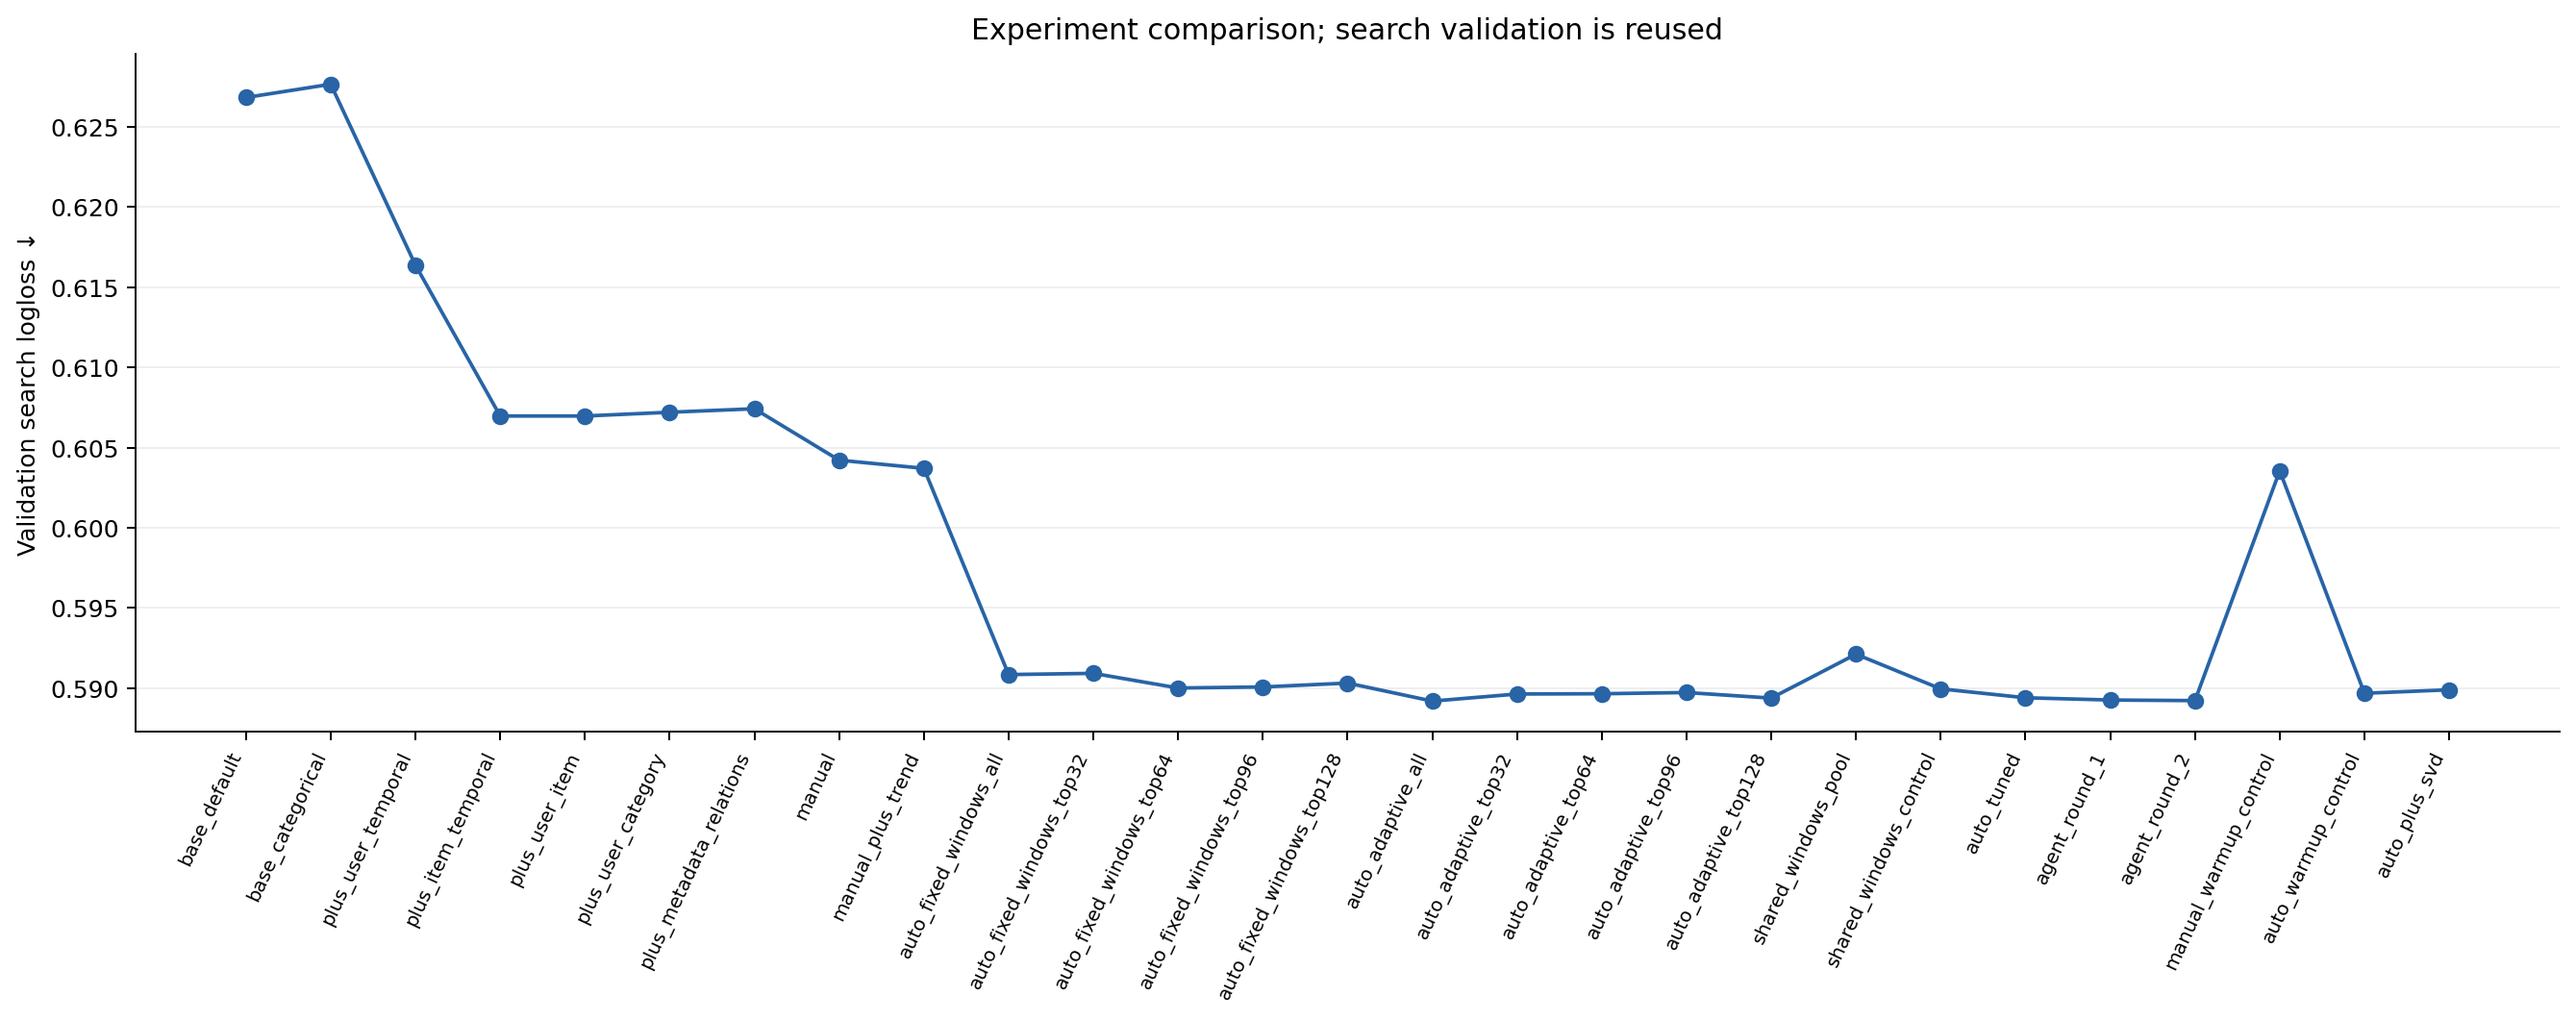

### metric vs features

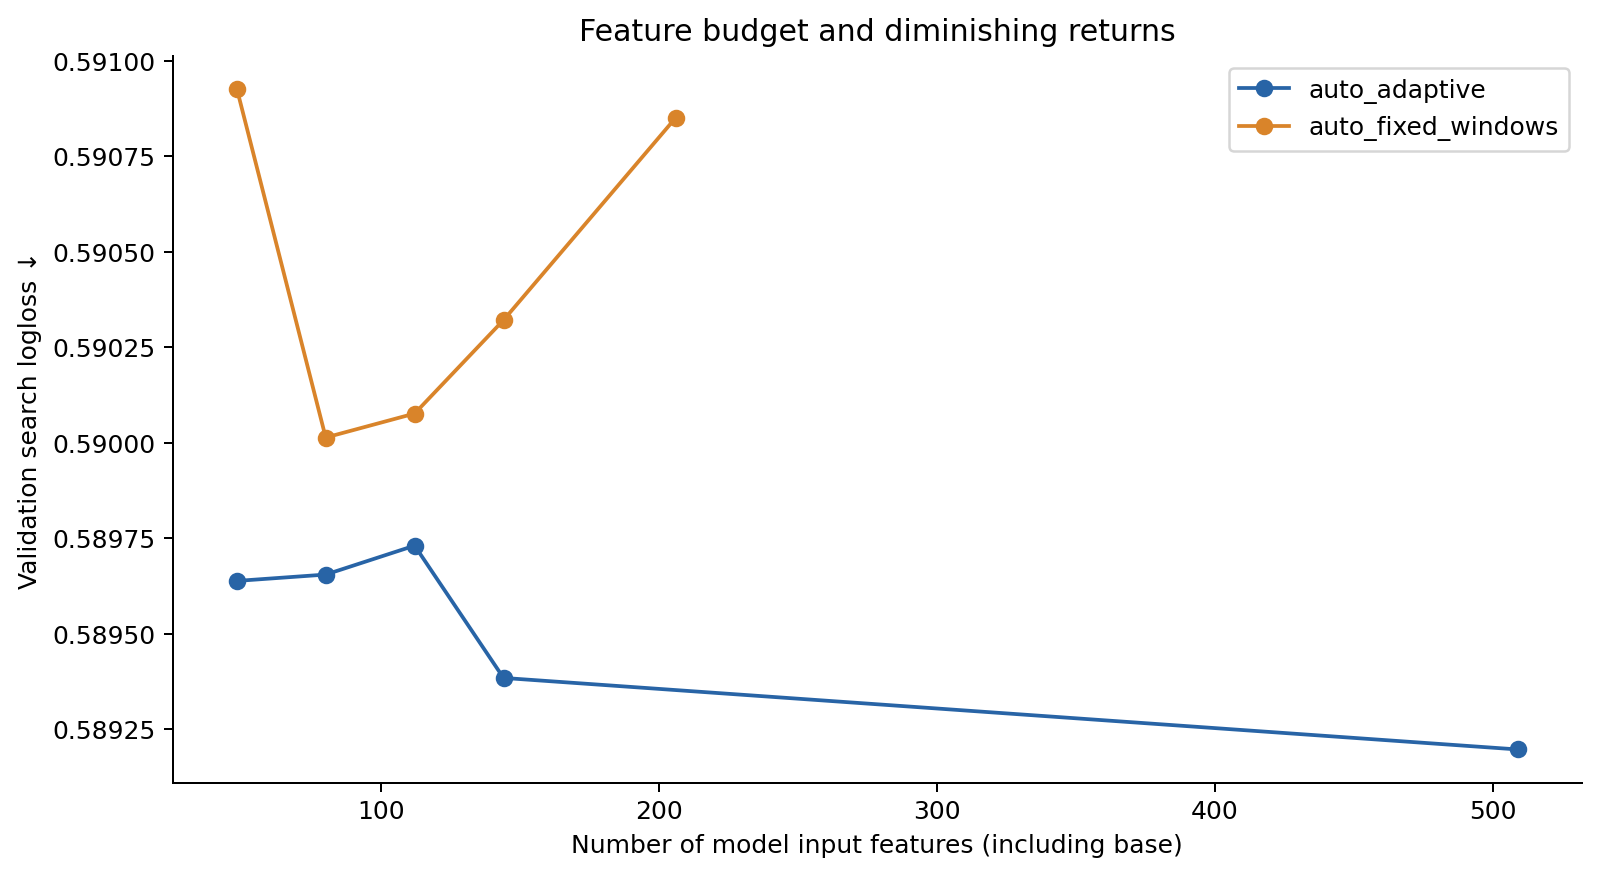

### top30 importance

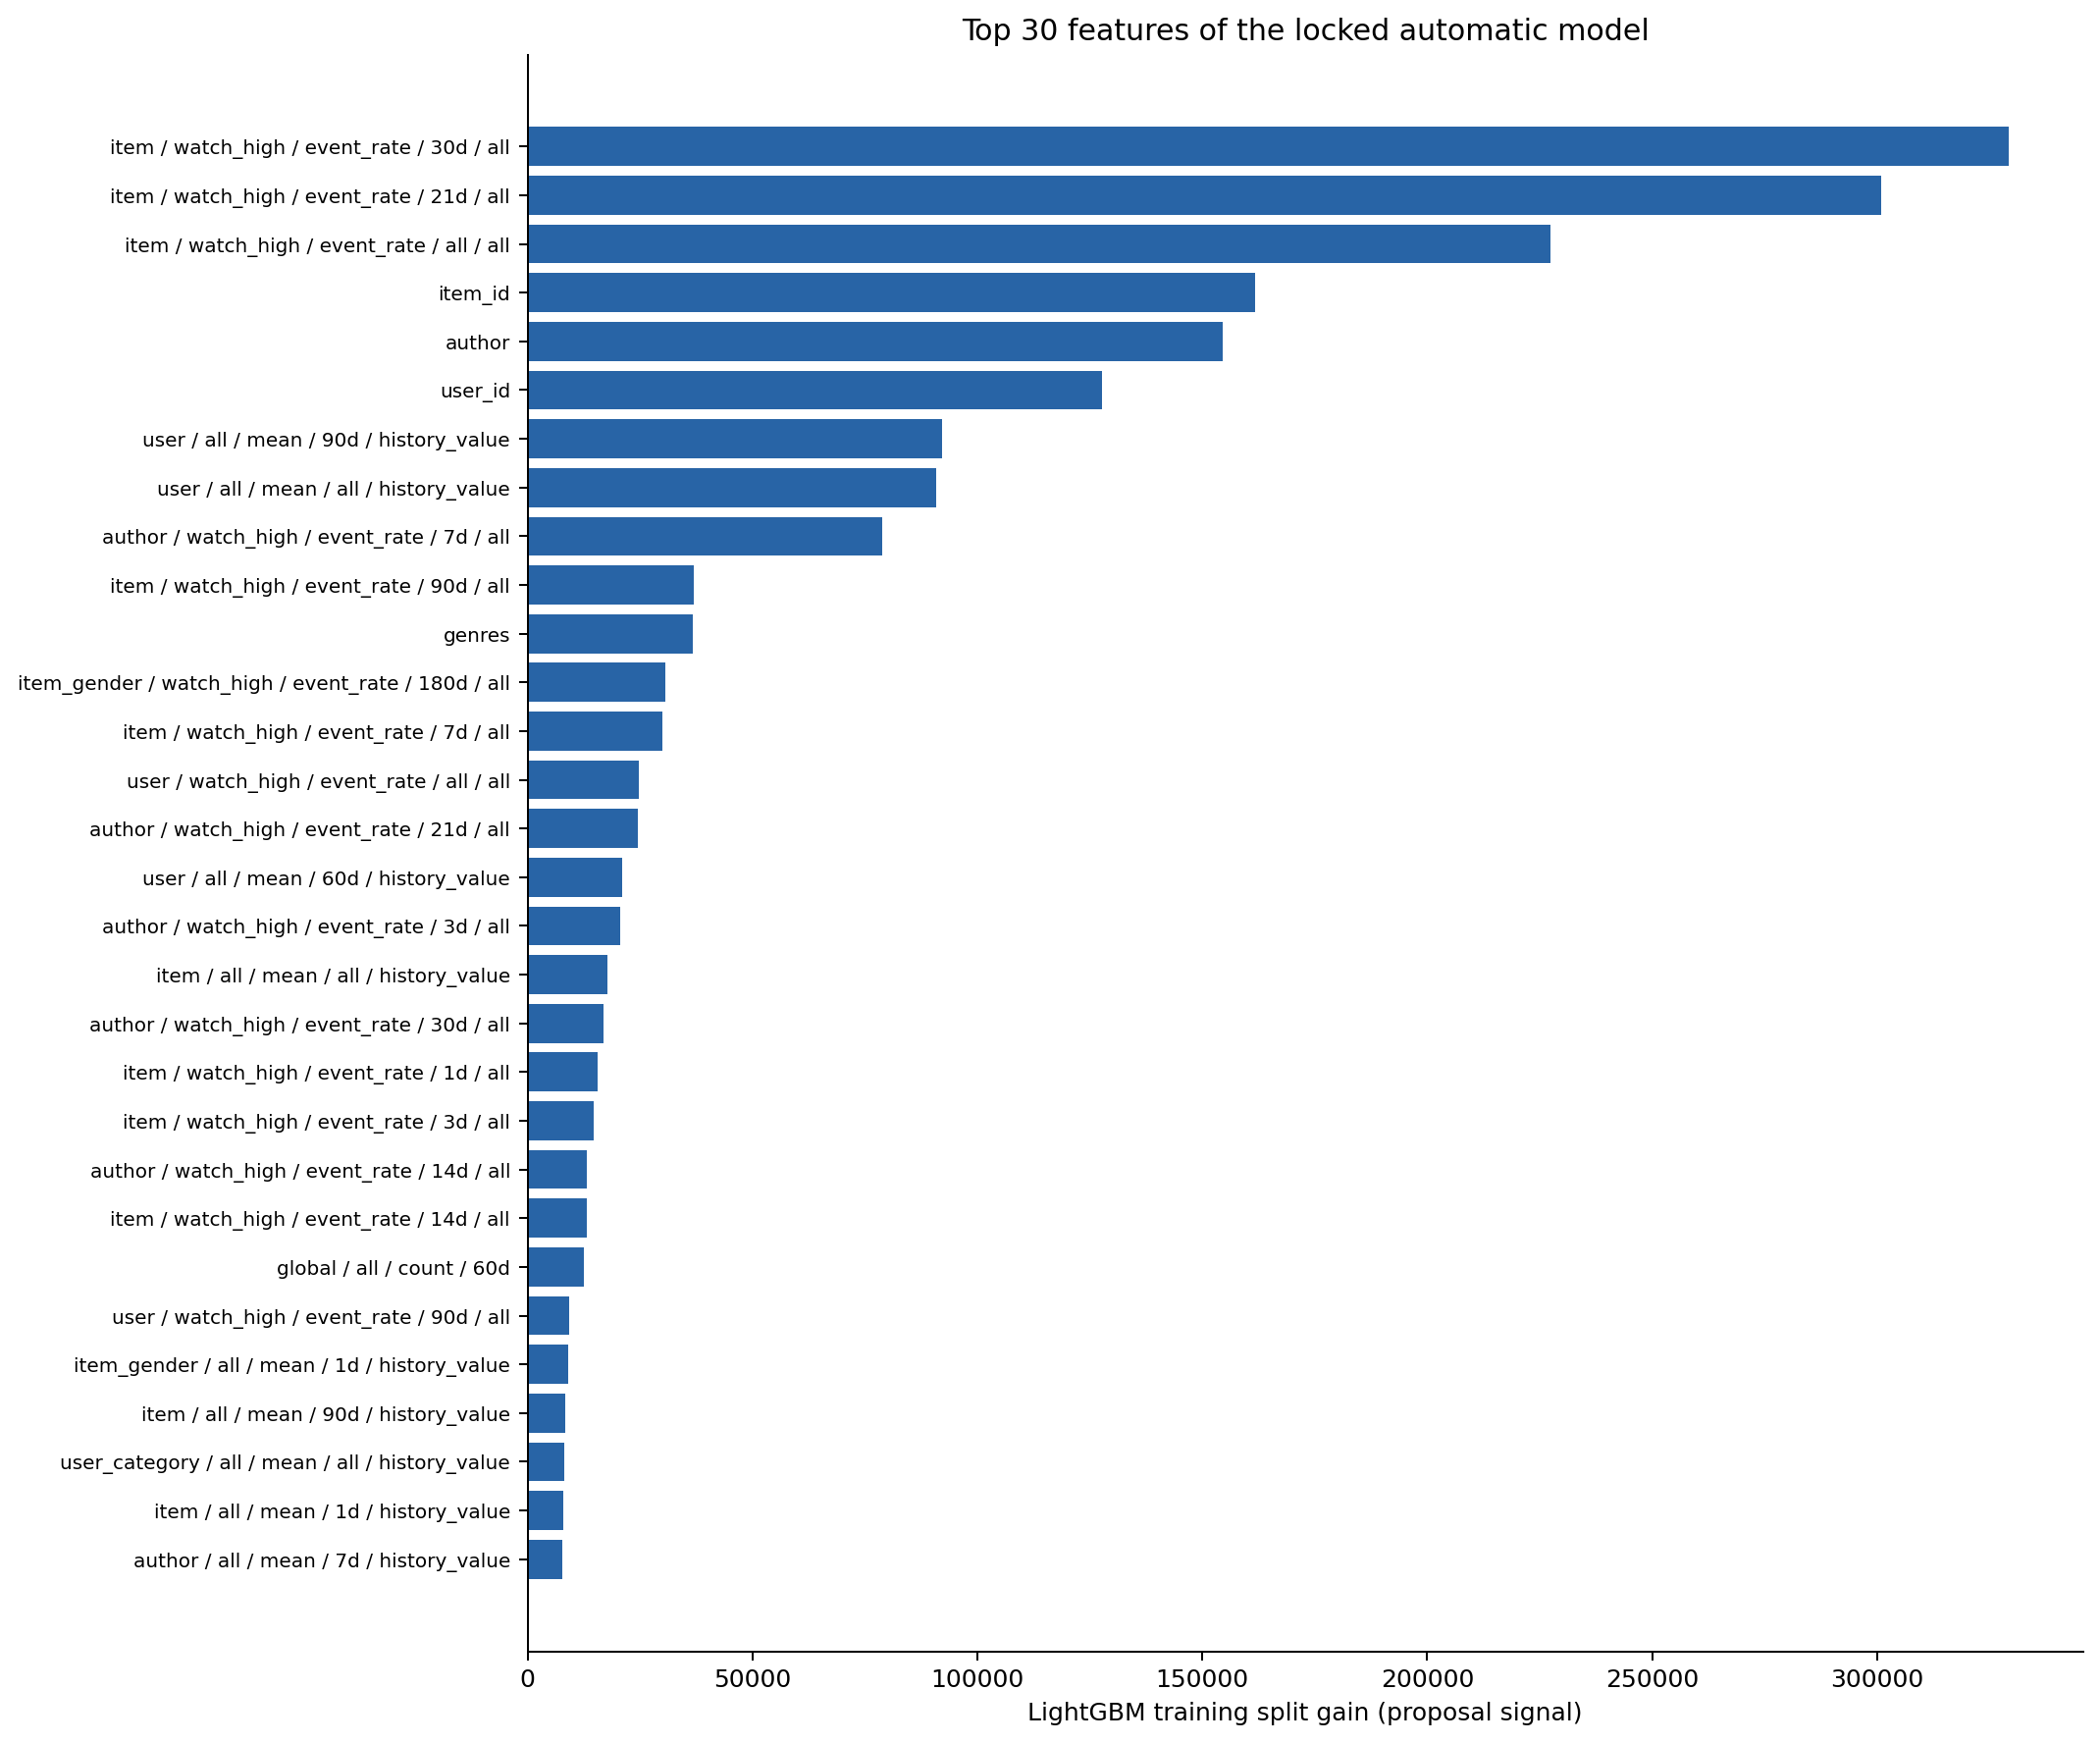

### window distribution

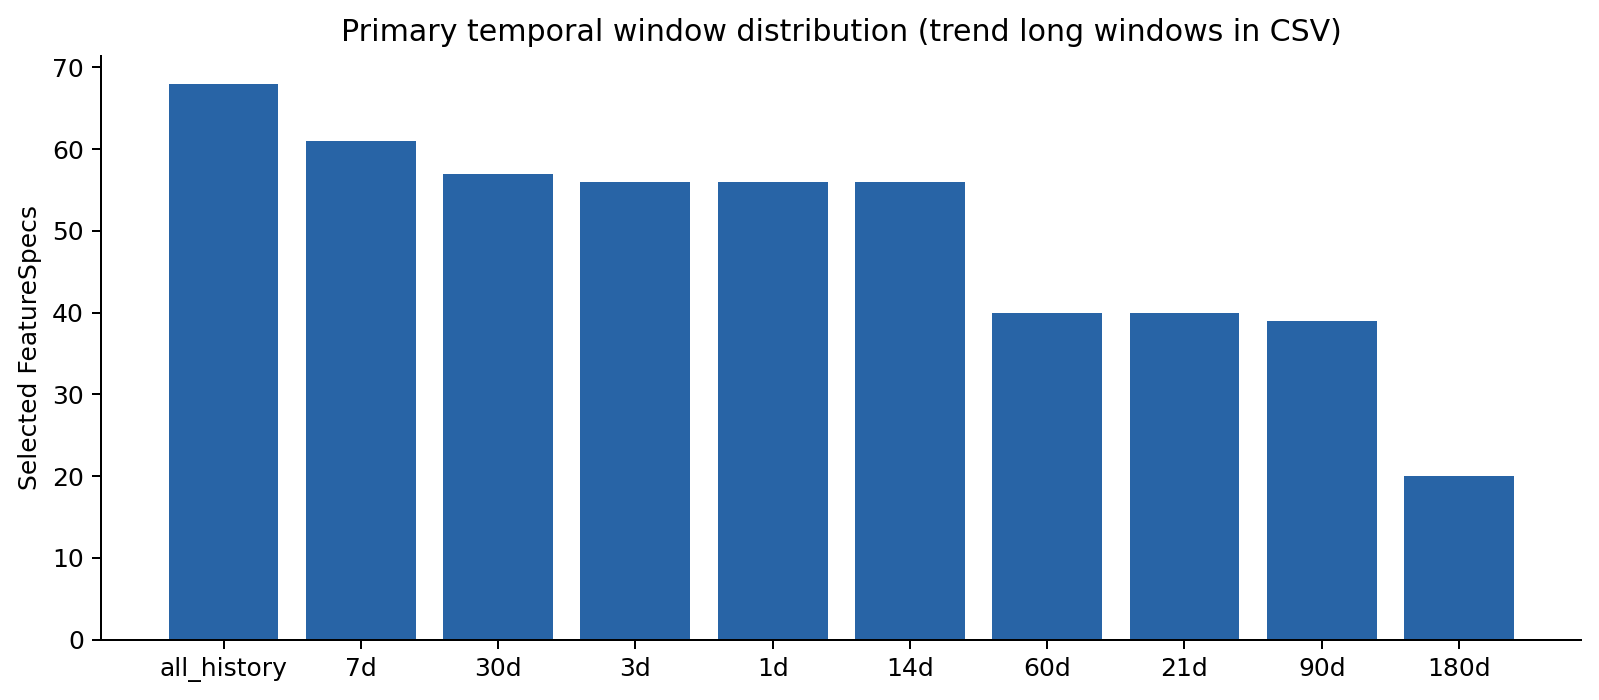

### entity window heatmap

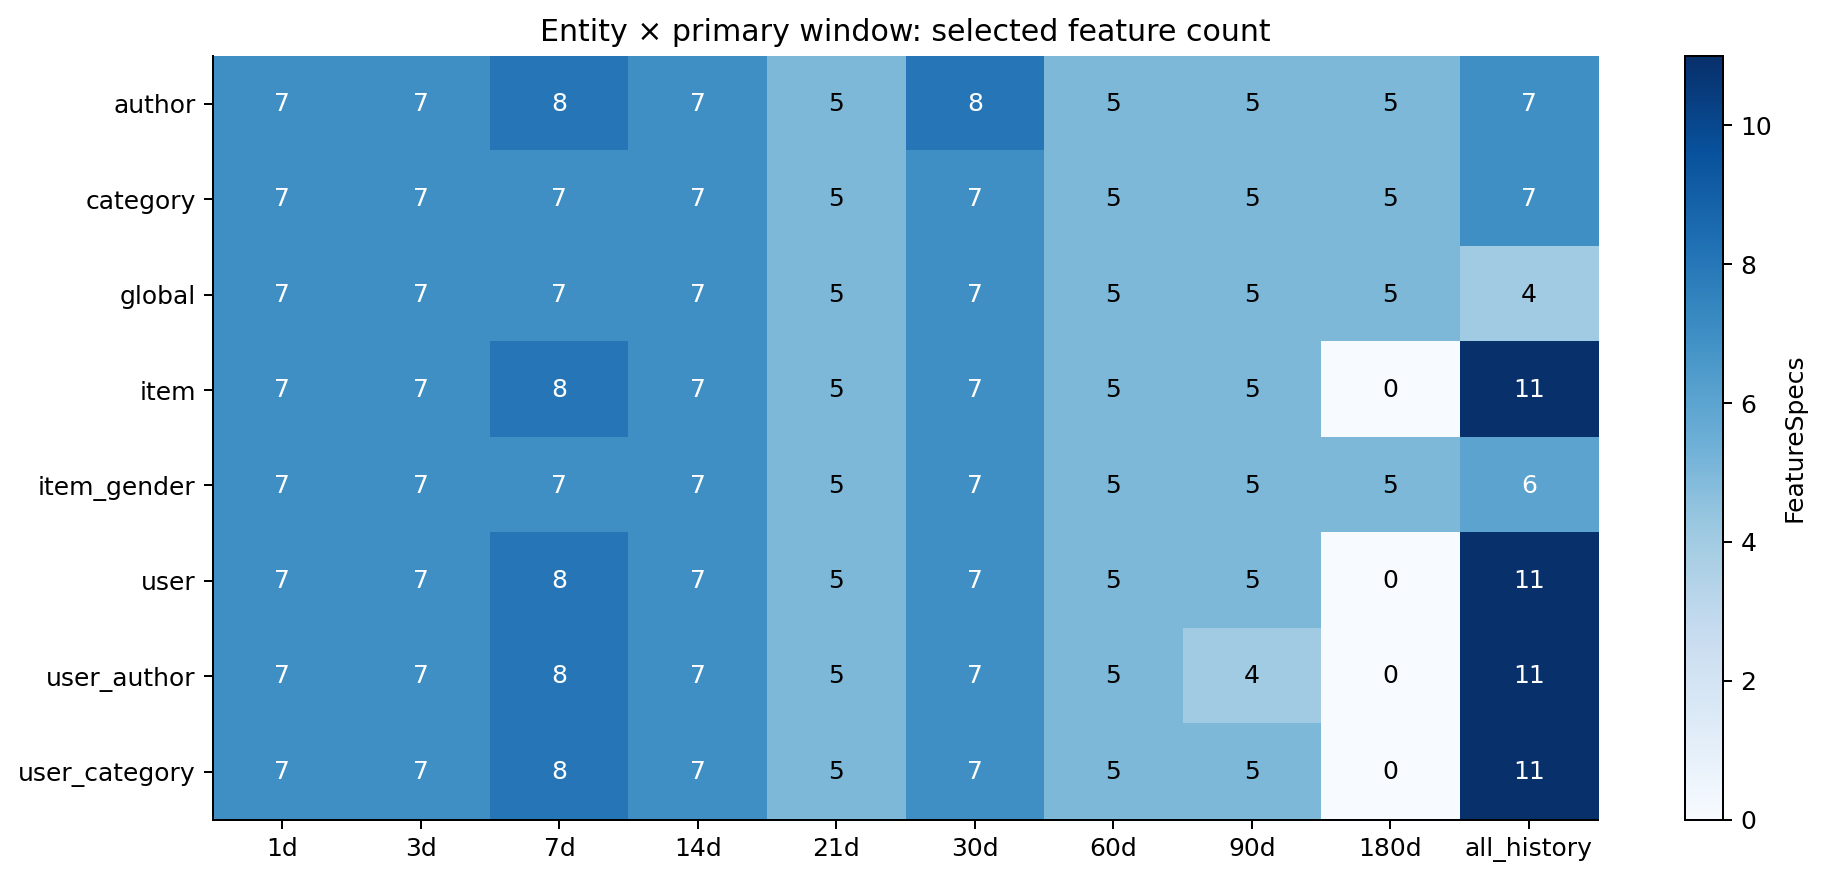

### feature family gain

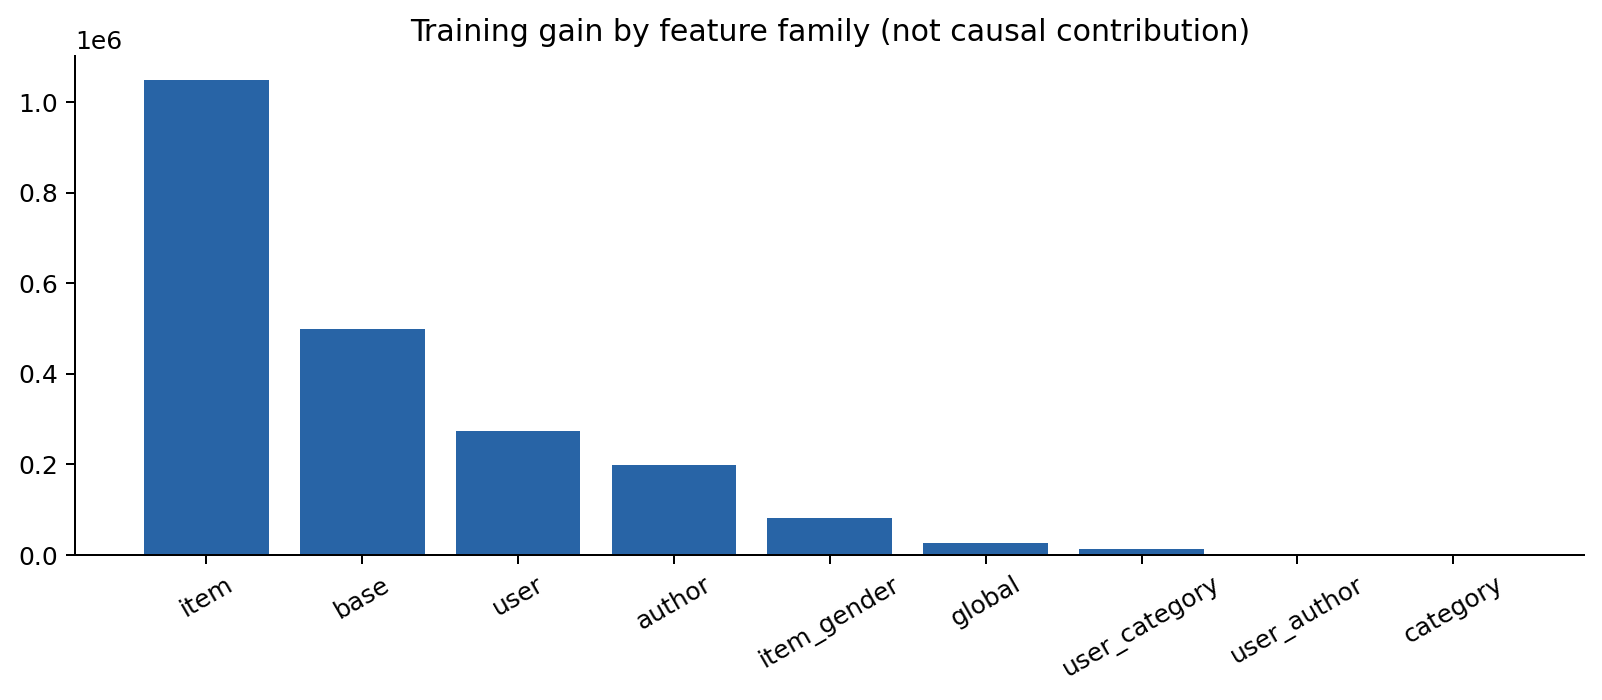

### feature counts

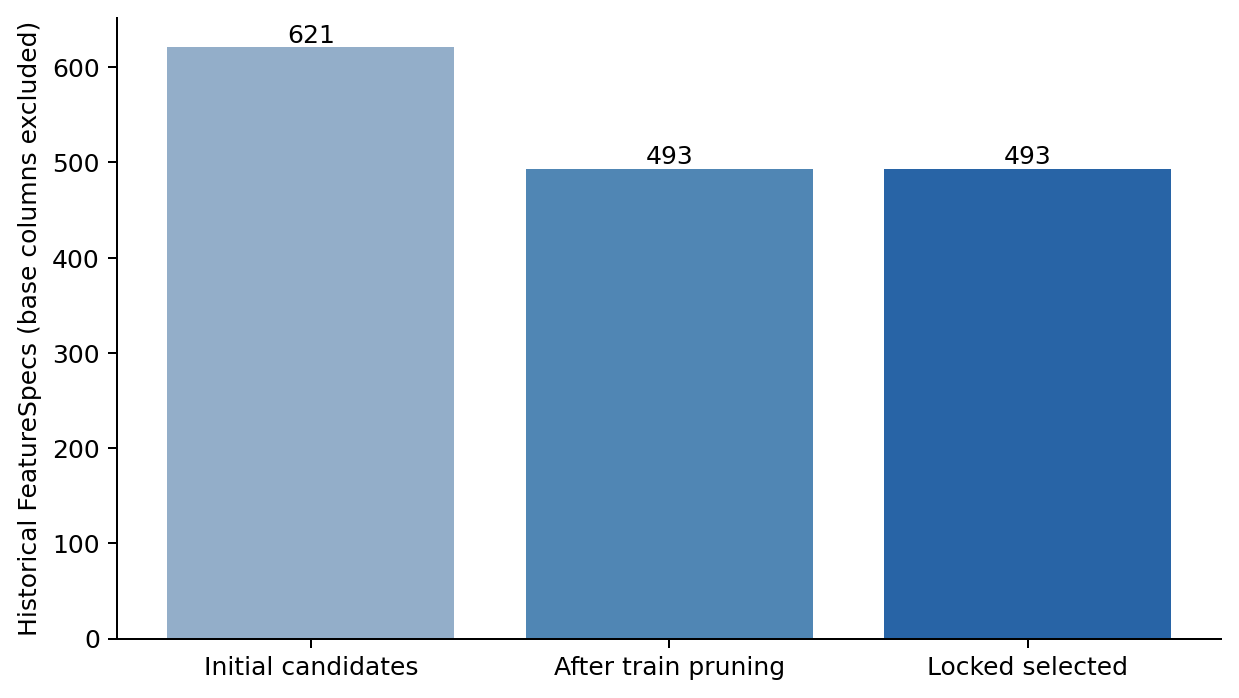

### test metrics

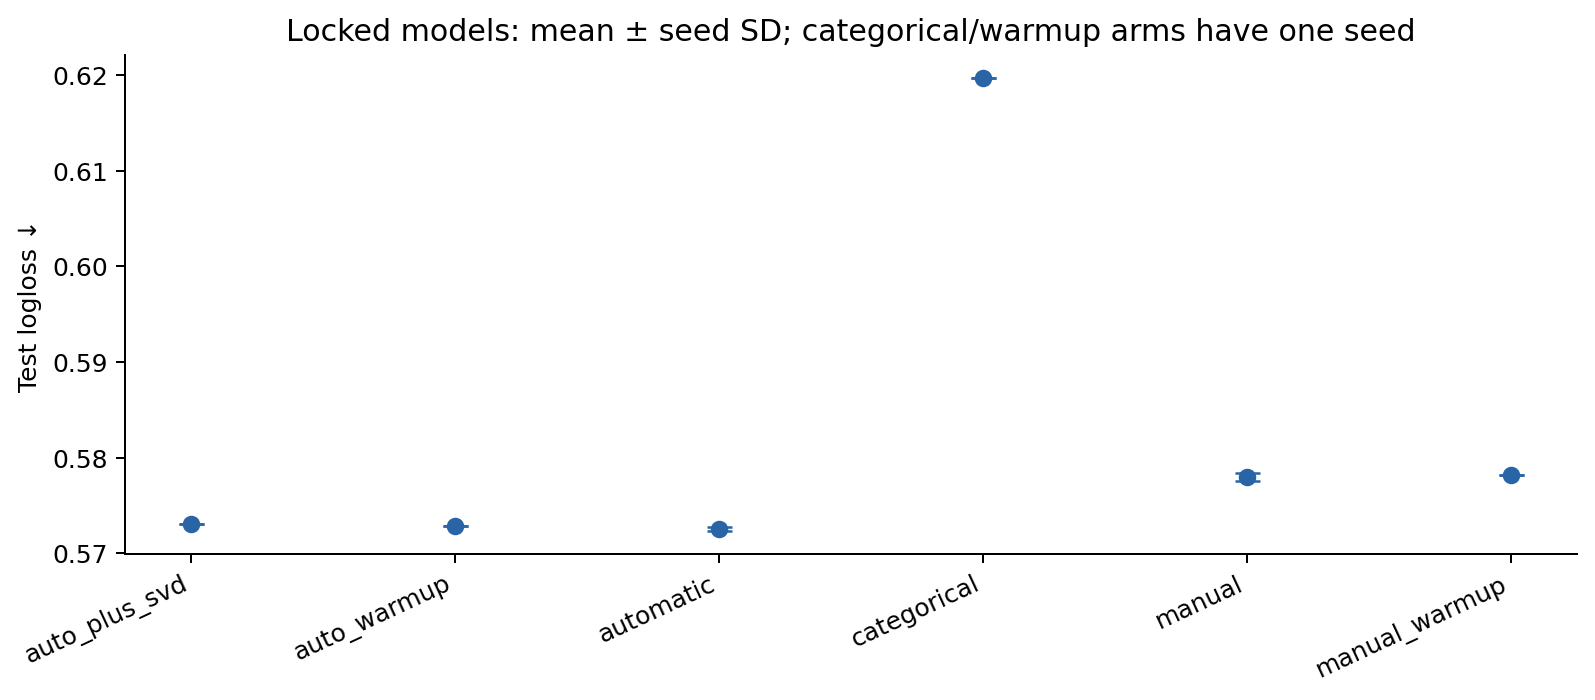

In [44]:
plots(OUTPUT_ROOT)
for plot_name in ["metric_by_experiment.png", "metric_vs_features.png", "top30_importance.png",
                  "window_distribution.png", "entity_window_heatmap.png", "feature_family_gain.png",
                  "feature_counts.png", "test_metrics.png"]:
    display(Markdown("### " + plot_name.removesuffix(".png").replace("_", " ")))
    display(Image(filename=str(OUTPUT_ROOT / "plots" / plot_name)))

## 25. Что можно заключить из сравнения

Сначала сравниваем средний LogLoss основных моделей по трем заранее заданным seeds.
Затем смотрим парный bootstrap для seed 42. Эти проверки отвечают на разные вопросы:
первая показывает разброс обучения при фиксированном наборе, вторая — неопределенность
разницы на пользователях test при уже обученных моделях.

Если automatic выигрывает, это поддерживает полезность выбранного набора на данном
периоде. Чтобы утверждать, что сам поиск устойчиво переносится во времени, понадобятся
несколько temporal splits. Для SVD сравниваем `auto_plus_svd` с `auto_warmup`, где
исключены те же ранние строки: иначе эффект векторов смешался бы с размером train.

На главный вопрос об автоматизации есть и отдельный ответ по коду: конкретные колонки
и окна действительно генерируются и выбираются программой. Человек по-прежнему
определяет задачу, допустимые связи, правила расчета и бюджет. Метрики нужны, чтобы
проверить, дает ли такая автоматизация практическую пользу.

In [45]:
test_summary = experiments.filter(pl.col("split") == "test").group_by("experiment_name").agg(
    pl.len().alias("seeds"), pl.col("logloss").mean().alias("mean_logloss"),
    pl.col("logloss").std().alias("sd_logloss"), pl.col("auc").mean().alias("mean_auc")).sort("experiment_name")
display(test_summary)
print(json.dumps(final_results["comparisons"], indent=2))
summary_lookup = {row["experiment_name"]: row for row in test_summary.to_dicts()}
mean_difference = summary_lookup["automatic"]["mean_logloss"] - summary_lookup["manual"]["mean_logloss"]
comparison = final_results["comparisons"]["test_automatic_vs_manual"]
lower, upper = comparison["logloss_ci_95"]
print(f"Mean test LogLoss, automatic − manual: {mean_difference:+.6f}")
if upper < 0 and mean_difference < 0:
    print("Automatic model improves this test; confidence interval is conditional on fixed models.")
else:
    print("Stable superiority of automatic temporal features over manual baseline is NOT established.")
print("Feature generation/selection is automated; humans still define target, schema, grammar, validation and budget.")
if MODE == "smoke":
    print("SMOKE results verify execution only; they are not evidence for the full-data research conclusion.")

experiment_name,seeds,mean_logloss,sd_logloss,mean_auc
str,u32,f64,f64,f64
"""auto_plus_svd""",1,0.573067,null,0.730918
"""auto_warmup""",1,0.572847,null,0.730356
"""automatic""",3,0.572533,0.000238,0.730904
"""categorical""",1,0.619689,null,0.676487
"""manual""",3,0.577981,0.000423,0.726552
"""manual_warmup""",1,0.578137,null,0.726888


{
  "audit_automatic_vs_manual": {
    "delta_logloss": -0.013779284682291507,
    "logloss_ci_95": [
      -0.014722341296618443,
      -0.012609572918716595
    ],
    "delta_auc": 0.001478437301804858,
    "auc_ci_95": [
      0.0007425997150209112,
      0.0021338529162893026
    ],
    "bootstrap_users": 81988,
    "repeats": 300,
    "interpretation": "Fixed models; does not include search/training variability"
  },
  "test_automatic_vs_manual": {
    "delta_logloss": -0.005166011041654492,
    "logloss_ci_95": [
      -0.005595779525580352,
      -0.0047666291589369015
    ],
    "delta_auc": 0.004461085894825523,
    "auc_ci_95": [
      0.0039717524769347454,
      0.004943303548681038
    ],
    "bootstrap_users": 134999,
    "repeats": 300,
    "interpretation": "Fixed models; does not include search/training variability"
  },
  "test_svd_vs_auto_warmup": {
    "delta_logloss": 0.00021981307192658935,
    "logloss_ci_95": [
      5.491499120714657e-05,
      0.00038458540990

### Сводка по двум датасетам

Если оба полных run находятся рядом, выводим их результаты в одной таблице.
Сравнивать KION и Yambda по абсолютному LogLoss некорректно: targets и доли классов
разные. Сравниваем manual и automatic внутри каждого источника. Результаты smoke
в эту сводку не входят.

In [46]:
dataset_summaries = []
for dataset_name in ["kion", "yambda"]:
    dataset_root = WORK_DIR / "artifacts" / dataset_name
    if not (dataset_root / "final_results.json").exists():
        continue
    dataset_experiments = pl.read_csv(dataset_root / "experiments.csv")
    dataset_result = dataset_experiments.filter(
        (pl.col("split") == "test") & pl.col("experiment_name").is_in(["manual", "automatic"])).group_by(
        "experiment_name").agg(pl.col("logloss").mean(), pl.col("auc").mean())
    for row in dataset_result.to_dicts():
        dataset_summaries.append({"dataset": dataset_name, **row})
if dataset_summaries:
    display(pl.DataFrame(dataset_summaries).sort(["dataset", "experiment_name"]))

dataset,experiment_name,logloss,auc
str,str,f64,f64
"""kion""","""automatic""",0.572533,0.730904
"""kion""","""manual""",0.577981,0.726552
"""yambda""","""automatic""",0.16115,0.93679
"""yambda""","""manual""",0.163072,0.936045


## 26. Время, память и оставшиеся ограничения

Автоматический поиск экономит ручную работу, но требует дополнительных расчетов
и обучений. Ниже время создания блоков признаков, память процесса и время final fit.
Это разные измерения: короткий final fit еще не означает дешевый поиск в целом.
Сегменты известных/новых пользователей помогают заметить, если общий score скрывает
проблему cold start; после test по этим сегментам модель не перенастраиваем.

In [47]:
generation_profile = json.loads((OUTPUT_ROOT / "generation_profile.json").read_text())
print(json.dumps(generation_profile, indent=2))
display(experiments.filter(pl.col("split") == "test").select("experiment_name", "seed", "n_features", "training_time", "memory_usage"))
if (OUTPUT_ROOT / "test_segments.csv").exists():
    display(pl.read_csv(OUTPUT_ROOT / "test_segments.csv").select("model", "segment", "rows", "logloss", "auc"))

{
  "manual": {
    "seconds": 22.011900334007805,
    "memory_mb": 536.8761386871338,
    "n_features": 102,
    "groups": [
      {
        "entity": "user",
        "seconds": 3.1035365420102607,
        "n_features": 18
      },
      {
        "entity": "item",
        "seconds": 0.4442760410020128,
        "n_features": 18
      },
      {
        "entity": "user_item",
        "seconds": 6.232246625004336,
        "n_features": 18
      },
      {
        "entity": "user_category",
        "seconds": 4.306580707983812,
        "n_features": 18
      },
      {
        "entity": "user_author",
        "seconds": 7.868041208013892,
        "n_features": 18
      }
    ],
    "cutoff": "[T - window, T); all_history < T",
    "audit_passed": true,
    "peak_process_mb": 2356.1875,
    "key": "9e458165ae8d46cac7ba33ca8de406aca75bd11c96704047957ceb8d10ba2af6"
  },
  "additional_candidates": {
    "seconds": 35.718053624994354,
    "memory_mb": 2702.9437589645386,
    "n_features": 519

experiment_name,seed,n_features,training_time,memory_usage
str,i64,i64,f64,f64
"""categorical""",42,16,12.757742,2492.328125
"""manual""",42,118,28.028123,2889.71875
"""manual""",2024,118,21.827201,3058.25
"""manual""",7,118,26.153081,3134.90625
"""automatic""",42,509,135.595977,6178.859375
"""automatic""",2024,509,144.037388,5561.390625
"""automatic""",7,509,137.672691,4823.984375
"""manual_warmup""",42,118,20.239038,3936.3125
"""auto_warmup""",42,509,110.930937,7908.4375


model,segment,rows,logloss,auc
str,str,i64,f64,f64
"""categorical""","""known_user_id""",129632,0.627186,0.679332
"""categorical""","""unknown_user_id""",110815,0.610919,0.67585
"""manual""","""known_user_id""",129632,0.588495,0.733349
"""manual""","""unknown_user_id""",110815,0.564624,0.712009
"""automatic""","""known_user_id""",129632,0.583218,0.738127
…,…,…,…,…
"""manual_warmup""","""unknown_user_id""",110815,0.565179,0.71259
"""auto_warmup""","""known_user_id""",129632,0.583955,0.736578
"""auto_warmup""","""unknown_user_id""",110815,0.559853,0.71606


RSS измеряет память всего процесса с удерживаемыми матрицами. Cache profile хранит
время первоначального создания блока. В повторном KION run часть блоков использована
заново при совпавших data/spec/engine hashes; эти времена нельзя выдавать за новое
измерение длительности расчета. Время обучения моделей измерялось отдельно.

Главное ограничение исследования — один временной split и многократное использование
search validation. Три seeds не заменяют проверку на нескольких будущих периодах.
Кроме того, здесь есть допущения о готовности labels и статичности metadata, а категории
и авторы сведены к одной связи. Для production их нужно проверять по реальным логам.

На миллиард событий прямое расширение этого расчета не подойдет: одна матрица
из 400 float32 колонок заняла бы около 1.6 TB без накладных расходов. Поиск пришлось бы
проводить на выборке, а историю считать по разделенным entity states и хранить так,
чтобы на запрос выдавались значения только из допустимого прошлого. Поздние события
потребовали бы пересчета затронутой истории. Производительность на 1B+ здесь не измерялась.

Следующие полезные проверки — несколько rolling-origin splits, полный контекст
прослушиваний и отмен реакций Yambda, реальные candidate sets и новый закрытый holdout.
После этого можно сравнивать более сложные модели и проводить online A/B test.
GNN и Transformers пока рассмотрены в обзоре, их результатов в эксперименте нет.

Модульная версия сохранена для сопровождения, но все нужные для расчета функции
уже находятся в этом notebook.